## Delivery version

# If you see "step xx." That means you need to deploy somthing. Step 0.xx means the preparation work before deployment, because we are not directly deployment, we need to first build the material needed in Fedrated learning. Then Step 1~xx mean your real deployment.

You will find only 4 steps required

# 1 Before your edge and cloud demo deployment, somthing needs to be done in preparation.



## 1.1 This part has nothing to do with your deployment, jsut I change the saveing path to my cloud path to ensure I can run on Googld colab in traveling, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/utility/

In [1]:

import os, sys
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Add your project root to sys.path
BASE = '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun'
sys.path.append(BASE)

# Ensure `utility` and `model` folders are Python packages (i.e., contain __init__.py)
for sub in ['utility', 'model']:
    subdir = os.path.join(BASE, sub)
    if os.path.isdir(subdir) and not os.path.exists(os.path.join(subdir, '__init__.py')):
        open(os.path.join(subdir, '__init__.py'), 'a').close()
        print(f"Created: {subdir}/__init__.py")

# ===== Keras 3 compatibility patch =====
import tensorflow as tf
import keras.backend as K

# Backfill backend functions removed in Keras 3 for legacy 2.x codebases
def _random_normal(shape, mean=0.0, stddev=1.0, dtype=None, seed=None):
    return tf.random.normal(shape=shape, mean=mean, stddev=stddev, dtype=dtype or tf.float32, seed=seed)

def _random_uniform(shape, minval=0.0, maxval=1.0, dtype=None, seed=None):
    return tf.random.uniform(shape=shape, minval=minval, maxval=maxval, dtype=dtype or tf.float32, seed=seed)

if not hasattr(K, "random_normal"):
    K.random_normal = _random_normal
if not hasattr(K, "random_uniform"):
    K.random_uniform = _random_uniform

print("✅ Keras 3 compatibility patch applied.")

# ===== Import your modules now =====
from utility.logger import aiLogger
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from model.componentModel import mainModel
from model.tepSystemModel import SystemModel
from preProcessingDataTEP import PreProcessData
from prettytable import PrettyTable

from keras.optimizers import Adam
from utility.matpilotDraw import MatPlot
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os, warnings, random, json

print("\n All imports succeeded and the environment is ready.")


Mounted at /content/drive
✅ Keras 3 compatibility patch applied.

 All imports succeeded and the environment is ready.


In [2]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from model.tepSystemModel   import SystemModel
from preProcessingDataTEP   import PreProcessData
from prettytable            import PrettyTable

from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json
# ---------------------------
# Loading config file
# ---------------------------
with open('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]

# ---------------------------
# Set debug level and
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore')

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 100
normalizeHI             = True
showRedundantShutdown   = False

## 1.2. This part is your original code, define the model

In [3]:

# ====================================
#  IMPORT LIBRARIES
# ====================================
from keras.layers                   import Conv1D,  Flatten, Dense, Conv1DTranspose, Reshape, Input, Layer, GRU, LSTM, Concatenate, Embedding, MultiHeadAttention, Lambda, Multiply, Minimum, Maximum
from keras                          import backend as K
from keras.models                   import Model
from keras.optimizers               import Adam
from model.vaeBase                  import BaseVariationalAutoencoder, Sampling
from re                             import T
from keras.metrics                  import Mean
from utility.logger                 import aiLogger
from scipy.stats                    import spearmanr
import  numpy                       as np
import  tensorflow                  as tf
import time
import  os, warnings, sys
import  joblib, random, json
from tensorflow.keras import backend as K


# -----------------------
# Filter the level of
# debuging
# -----------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore')
tf.random.set_seed(1)

# ====================================
#  The custom model checkpoint for
#   subclass method
# ====================================
class SubclassModelCheckpoint(tf.keras.callbacks.ModelCheckpoint):
    def __init__(self, customSaveFunction, config= None, *args, **kwargs):
        super(SubclassModelCheckpoint, self).__init__(*args, **kwargs)

        self.config             = config
        self.customSaveFunction = customSaveFunction

    # --------------------------------
    # Override the default saving function
    # --------------------------------
    def _save_model(self, epoch, logs, *args, **kwargs):
        logs    = logs or {}
        current = logs.get(self.monitor)                                       # Get the monitored metric value (e.g., val_loss)

        if current is None:
            print(f"Warning: Metric {self.monitor} is not available.")
            return

        if self.save_best_only:
            if self.monitor_op(current, self.best):
                if self.verbose > 0:
                    print(f" \n Epoch {epoch + 1}: {self.monitor} improved from {self.best} to {current}. Saving model...")

                self.best   = current
                filepath    = self.filepath.format(epoch=epoch + 1, **logs)         # Format the file path and get the directory
                model_dir   = os.path.dirname(filepath)                             # Extract the directory
                self.customSaveFunction(model_dir, config=self.config)              # Call the custom save function
        else:
            filepath    = self.filepath.format(epoch=epoch + 1, **logs)
            model_dir   = os.path.dirname(filepath)                             # Extract the directory
            self.customSaveFunction(model_dir, config=self.config)              # Call the custom save function


# ====================================
# Attention convolution
# ====================================
class AttentionMaskedConv1D(tf.keras.layers.Layer):
    def __init__(self, filters, kernel_size, strides=2,  activation='relu', padding = 'same', **kwargs):
        super(AttentionMaskedConv1D, self).__init__(**kwargs)
        self.conv = Conv1D(filters, kernel_size, strides=strides, padding=padding, activation=activation)
        self.attention_weights = Dense(filters, activation='sigmoid')

    def call(self, inputs):
        conv_output = self.conv(inputs)
        attn_weights = self.attention_weights(conv_output)
        attended_output = conv_output * attn_weights
        return attended_output

# ====================================
# VAE Time (VariationalAutoencoderConv)
# ====================================
class VAEConvInterpretable(BaseVariationalAutoencoder):
    def __init__(   self,
                    hidden_layer_sizes,
                    config      = None,
                    **kwargs   ):
        '''
            hidden_layer_sizes  : list of number of filters in convolutional layers in encoder and residual connection of decoder.
            trend_poly          : integer for number of orders for trend component. e.g. setting trend_poly = 2 will include linear and quadratic term.
            num_gen_seas        : Number of sine-waves to use to model seasonalities. Each sine wae will have its own amplitude, frequency and phase.
            custom_seas         : list of tuples of (num_seasons, len_per_season).
            num_seasons         : number of seasons per cycle.
            len_per_season      : number of epochs (time-steps) per season.
            use_residual_conn   : boolean value indicating whether to use a residual connection for reconstruction in addition to trend, generic and custom seasonalities.
        '''

        super(VAEConvInterpretable, self).__init__(**kwargs)

        self.hidden_layer_sizes = hidden_layer_sizes
        self.encoder            = self.get_encoder()
        self.decoder            = self.get_decoder()
        self.config             = config

    # ================================
    # Full AE
    # --------------------------------
    def getUnsymetricDecoder(self,kernelSize = 3, stride = 1):
        z   = Input(shape=(self.latent_dim,), name="decoder_input")
        wIn = Input(shape=(self.seq_len,self.config["manipulationDim"]), name="manipulatedVar")

        x = tf.keras.layers.RepeatVector(self.seq_len,name='repeat')(z)
        x = tf.keras.layers.Concatenate(axis  =-1)([x, wIn])

        for numFilters in reversed(self.hidden_layer_sizes):
            x = tf.keras.layers.Conv1D(filters      =   numFilters,
                                       kernel_size  =   kernelSize,
                                       stride      =   stride,
                                       activation   =   'relu',
                                       padding = 'same')(x)

        reconsData  = tf.keras.layers.Dense(self.config["efficiencyDim"],name='X')(x)

        decoder     = tf.keras.models.Model([z, wIn],reconsData)
        return decoder

    # ================================
    # Attention encoder
    # --------------------------------
    def getAttentionEncoder(self, kernelSize = 3, stride = 2):
        encoder_inputs  = Input(shape   = (self.seq_len, self.feat_dim),
                                name    = 'encoder_input')
        x               = encoder_inputs
        # --------------------
        # Repeat to create Conv1D
        # --------------------
        for i, num_filters in enumerate(self.hidden_layer_sizes):
            x = AttentionMaskedConv1D(  filters     = num_filters,
                                        kernel_size = kernelSize,
                                        strides     = stride,
                                        activation  = 'relu',
                                        padding     = 'same',
                                        name        = f'enc_conv_{i}')(x)
        sysHILayer = AttentionMaskedConv1D(     filters     = 5,
                                                kernel_size = kernelSize,
                                                strides     = stride,
                                                activation  = 'relu',
                                                padding     = 'same',
                                                name        = 'extractedSysHiLayer')(x)

        print("The shape of sysHILayer",sysHILayer.shape)
        # --------------------
        # Flat and create latent
        # --------------------
        x                       = Flatten(name='enc_flatten')(x)
        self.encLastDenseDim    = K.int_shape(x)[-1]                                 # save the dimensionality of this last dense layer before the hidden state layer. We need it in the decoder.

        # ----------------------
        # For VAE
        # ----------------------
        encoder_output          = Dense(self.latent_dim, name="encoder_output")(x)
        self.encoder_output     = encoder_output

        encoder                 = Model(encoder_inputs, [encoder_output, sysHILayer], name="encoder")
        return encoder
    # ================================
    # Create module Encoder separately
    # --------------------------------
    def get_encoder(self, kernelSize = 3, stride = 2):
        # --------------------
        # Input
        # --------------------
        encoder_inputs  = Input(shape   = (self.seq_len, self.feat_dim),
                                name    = 'encoder_input')
        x               = encoder_inputs
        # --------------------
        # Repeat to create Conv1D
        # --------------------
        for i, num_filters in enumerate(self.hidden_layer_sizes):
            x = Conv1D( filters     = num_filters,
                        kernel_size = kernelSize,
                        strides     = stride,
                        activation  = 'relu',
                        padding     = 'same',
                        name        = f'enc_conv_{i}')(x)
        sysHILayer = Conv1D(    filters     = 5,
                                kernel_size = kernelSize,
                                strides     = stride,
                                activation  = 'relu',
                                padding     = 'same',
                                name        = 'extractedSysHiLayer')(x)
        print("The shape of sysHILayer",sysHILayer.shape)
        # --------------------
        # Flat and create latent
        # --------------------
        x                       = Flatten(name='enc_flatten')(x)
        self.encLastDenseDim    = K.int_shape(x)[-1]                                 # save the dimensionality of this last dense layer before the hidden state layer. We need it in the decoder.

        # ----------------------
        # For VAE
        # ----------------------
        encoder_output          = Dense(self.latent_dim, name="encoder_output")(x)
        self.encoder_output     = encoder_output

        encoder                 = Model(encoder_inputs, [encoder_output, sysHILayer], name="encoder")
        # print(encoder.summary())
        return encoder

    # =================================
    # ---------------------------------
    def get_decoder(self, kernelSize = 3, stride = 2):
        decoder_inputs = Input(shape=(self.latent_dim,), name="decoder_input")

        x = decoder_inputs
        x = Dense(self.encLastDenseDim, name="dec_dense", activation="relu")(x)


        x = Reshape(target_shape=(-1, self.hidden_layer_sizes[-1]), name="dec_reshape")(x)


        for i, num_filters in enumerate(reversed(self.hidden_layer_sizes[:-1])):
            x = Conv1DTranspose(    filters     = num_filters,
                                    kernel_size = kernelSize,
                                    strides     = stride,
                                    padding     = "same",
                                    activation  = "relu",
                                    name        = f"dec_deconv_{i}",
                                )(x)


        # last de-convolution
        self.decoder_outputs = Conv1DTranspose(        filters     = self.feat_dim,
                                    kernel_size = kernelSize,
                                    strides     = stride,
                                    padding     = "same",
                                    activation  = "relu",
                                    name        = f"dec_deconv__{i+1}",
                                )(x)


        # x                       = Flatten(name="dec_flatten")(x)
        # x                       = Dense(self.seq_len * self.feat_dim, name="decoder_dense_final")(x)
        # self.decoder_outputs    = Reshape(target_shape=(self.seq_len, self.feat_dim))(x)
        decoder                 = Model(decoder_inputs, self.decoder_outputs, name="decoder")
        # print(decoder.summary())
        return decoder
    # =================================
    # This one is decoder model. Using it
    # when the input is the power of 2
    # ---------------------------------
    def decoderNoDense(self, kernelSize = 3, stride = 2):
        decoder_inputs = Input(shape=(self.latent_dim,), name="decoder_input")

        x = decoder_inputs
        x = Dense(self.encLastDenseDim, name="dec_dense", activation="relu")(x)


        x = Reshape(target_shape=(-1, self.hidden_layer_sizes[-1]), name="dec_reshape")(x)


        for i, num_filters in enumerate(reversed(self.hidden_layer_sizes[:-1])):
            x = Conv1DTranspose(    filters     = num_filters,
                                    kernel_size = kernelSize,
                                    strides     = stride,
                                    padding     = "same",
                                    activation  = "relu",
                                    name        = f"dec_deconv_{i}",
                                )(x)


        # last de-convolution
        self.decoder_outputs = Conv1DTranspose(        filters     = self.feat_dim,
                                    kernel_size = kernelSize,
                                    strides     = stride,
                                    padding     = "same",
                                    activation  = "relu",
                                    name        = f"dec_deconv__{i+1}",
                                )(x)

        # x                       = Flatten(name="dec_flatten")(x)
        # x                       = Dense(self.seq_len * self.feat_dim, name="decoder_dense_final")(x)
        # self.decoder_outputs    = Reshape(target_shape=(self.seq_len, self.feat_dim))(x)
        decoder                 = Model(decoder_inputs, self.decoder_outputs, name="decoder")
        return decoder


# ====================================
#  Hi system block and RUL
# ====================================
from tensorflow.keras.layers import Input, Dense, Flatten, Concatenate, Multiply, Minimum, Maximum, LSTM, Lambda
from tensorflow.keras import Model
import tensorflow as tf

class HiSystemAndRul(tf.keras.Model):
    def __init__(self, config):
        super(HiSystemAndRul, self).__init__()
        self.config = config

        # Placeholder Inputs
        inputSensor = Input(shape=(128, 45), name="SensorInputForHISelection")  # included only when useInputAsHISelection=True
        inputRUL1   = Input(shape=(8, 5),   name="lastLayerAEComponent1")
        inputRUL2   = Input(shape=(8, 5),   name="lastLayerAEComponent2")
        inputRUL3   = Input(shape=(8, 5),   name="lastLayerAEComponent3")

        inputHI1    = Input(shape=(1,),     name="compHI1")
        inputHI2    = Input(shape=(1,),     name="compHI2")
        inputHI3    = Input(shape=(1,),     name="compHI3")

        # Select source for HI-selection vector and decide inputs_list
        if config.get("useInputAsHISelection", False):
            hiSelectionInput = inputSensor
            inputs_list = [inputSensor, inputRUL1, inputRUL2, inputRUL3, inputHI1, inputHI2, inputHI3]   # 7 inputs
        else:
            flatInRUL1       = Flatten()(inputRUL1)
            flatInRUL2       = Flatten()(inputRUL2)
            flatInRUL3       = Flatten()(inputRUL3)
            hiSelectionInput = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])                # (None, 120)
            inputs_list = [inputRUL1, inputRUL2, inputRUL3, inputHI1, inputHI2, inputHI3]               # 6 inputs

        aiLogger.debug(f"The shape of hiSelectionInput {hiSelectionInput.shape}")

        # Selection matrix (3 branches)
        x                = Dense(24, activation="relu")(hiSelectionInput)
        x                = Dense(16, activation="relu")(x)
        selection_logits = Dense(3, activation=None, name="Selection_Logits")(x)
        hiMatrixOutput   = Lambda(lambda t: tf.nn.softmax(t / 1.0), name="Selection_Output")(selection_logits)
        aiLogger.debug(f"The shape of multiplied matrix {hiMatrixOutput.shape}")

        # min / max / linear HI candidates
        concatenatedHiInput = Concatenate(axis=-1)([inputHI1, inputHI2, inputHI3])
        minSysHi            = Minimum()([inputHI1, inputHI2, inputHI3])
        maxSysHi            = Maximum()([inputHI1, inputHI2, inputHI3])
        linearSysHi         = Dense(1)(concatenatedHiInput)
        aiLogger.debug(f"The shape of min, max and linear HI {minSysHi.shape, maxSysHi.shape, linearSysHi.shape}")

        sysConcatenatedHi   = Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
        aiLogger.debug(f"The shape after concatenation {sysConcatenatedHi.shape}")
        selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])
        aiLogger.debug(f"The shape after multiplying with mask {selected_HI.shape}")
        sysHi               = Lambda(lambda t: tf.reduce_sum(t, axis=-1, keepdims=True), name="Final_HI")(selected_HI)
        aiLogger.debug(f"The shape of HI after reducing dimension {sysHi.shape}")

        # RUL branch
        concatenatedRULInput = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])  # (None, 8, 15)
        rulLayer1   = LSTM(32, return_sequences=True)(concatenatedRULInput)
        rulLayer2   = LSTM(16, return_sequences=True)(rulLayer1)
        rulLayer3   = LSTM(3,  return_sequences=False)(rulLayer2)
        rulInput    = Concatenate(axis=-1)([rulLayer3, sysHi])   # (None, 4)
        rul         = Dense(1, activation='linear')(rulInput)

        # Functional model: include only actually-used inputs
        self.model = Model(inputs=inputs_list, outputs=[hiMatrixOutput, sysHi, rul], name="HiSystemAndRul")

    def call(self, inputs):
        return self.model(inputs)

# ====================================
#  The sensor selection block
# ====================================
class SensorSelection(tf.keras.Model):
    def __init__(self, inFeature = 45, numEnvs = 3, comp = "Reac"):
        '''
        The input size should be (batchSize, timeStep, featureDim)
        '''
        super(SensorSelection, self).__init__()
        # self.mask_logits = self.add_weight(shape        = (inFeature,),
        #                                    initializer  = 'zeros',
        #                                    trainable    = True,
        #                                    name         = 'mask_logits')
        # self.numComponents  = numComponents

        # Mode 2 matrices
        self.physicMask = tf.Variable(tf.zeros((3, 45), dtype=tf.float32))
        if comp == "Reac":
            reac_2 = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1])
            reac_3 = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0])
            reac_4 = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1])
            self.physicMask = tf.constant(np.array([reac_2, reac_3, reac_4]), dtype=tf.float32)
        elif comp == "Sep":
            sep_2 = np.array([1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0])
            sep_3 = np.array([1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0])
            sep_4 = np.array([1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0])
            self.physicMask = tf.constant(np.array([sep_2, sep_3, sep_4]), dtype=tf.float32)

        else:
            strip_2 = np.array([1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0])
            strip_3 = np.array([1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0])
            strip_4 = np.array([1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0])
            self.physicMask = tf.constant(np.array([strip_2, strip_3, strip_4]), dtype=tf.float32)

        # Mode 3 matrices

        # Mode 4 matrices
        self.numModes       = numEnvs         # 3 modes in total
        self.mask_logits    = self.add_weight(  shape       =   (self.numModes, inFeature),  # Each mode has different sensor probabilities
                                                initializer =   "random_normal",
                                                trainable   =   True,
                                                name        =   "sensorMask"
                                            )
        # print(self.mask_logits.shape)

    def call(self,rawData,env):
        # ------------------------
        # Select the environment
        # ------------------------
        # print("-------------------------------", env.shape)
        env                 = tf.cast(env-2, tf.int32)                                # Ensure integer type for indexing, and env from 1 to three, so we need index from 0 to 2
        env_mask_logits     = tf.gather(self.mask_logits, env, axis=0)              # (batch_size, num_sensors) each sequence (after split) will have a different env, so env should be a batch (include differnt env to access to the mask)
        # withPhysicMask      = tf.gather(self.physicMask, env, axis=0)

        probs               = tf.sigmoid(env_mask_logits)
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(random_uniform, probs), tf.float32)
        # print("==================================",env_mask_logits.shape)
        # mask                = binary_mask + probs - tf.stop_gradient(probs)         # Apply the mask using the reparameterization trick
        # mask                = tf.expand_dims(mask, axis=0)
        # maskedData      = rawData * mask
        # print("-------------------------------")
        # print(self.mask_logits.shape)
        # print(env_mask_logits.shape)
        # print(rawData.shape)

        maskedData          = rawData * probs
        # print(maskedData.shape)
        # print("-------------------------------")
        return maskedData, probs, binary_mask

    def getMask(self,):
        probs               = tf.sigmoid(self.mask_logits)
        # random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(0.5, probs), tf.float32)
        return binary_mask, probs


# ==================================================
#                   SYSTEM MODEL
# ==================================================
class SystemModel(tf.keras.Model):
    def __init__(self,config = None,componentDir = "checkpoint/bestModel_200epoch/"):
        super(SystemModel, self).__init__()
        # ----------------------------
        # For model
        # ----------------------------
        self.config             = config

        vaeCr1                     = VAEConvInterpretable(  seq_len             = config["seqLength"],
                                                            feat_dim            = config["in" + config["allComp"][0]],
                                                            latent_dim          = config["latentDim"],
                                                            hidden_layer_sizes  = config["hiddenVAESize"], # [50,100,200]      #[80, 200, 250]
                                                            config              = config
                                                        )
        vaeCr2                     = VAEConvInterpretable(  seq_len             = config["seqLength"],
                                                            feat_dim            = config["in" + config["allComp"][1]],
                                                            latent_dim          = config["latentDim"],
                                                            hidden_layer_sizes  = config["hiddenVAESize"], # [50,100,200]      #[80, 200, 250]
                                                            config              = config
                                                            )
        vaeCv2                     = VAEConvInterpretable(  seq_len             = config["seqLength"],
                                                            feat_dim            = config["in" + config["allComp"][2]],
                                                            latent_dim          = config["latentDim"],
                                                            hidden_layer_sizes  = config["hiddenVAESize"], # [50,100,200]      #[80, 200, 250]
                                                            config              = config
                                                            )


        self.maskCr1           = SensorSelection(inFeature= config["in" + config["allComp"][0]], comp= "Reac")
        self.maskCr2           = SensorSelection(inFeature= config["in" + config["allComp"][1]], comp= "Sep")
        self.maskCv2           = SensorSelection(inFeature= config["in" + config["allComp"][2]], comp= "Strip")

        # self.encoder        = vae.getAttentionEncoder(kernelSize = 3, stride = 2)
        self.encoderCr1        = vaeCr1.get_encoder(kernelSize = 3, stride = 2)
        self.decoderCr1        = vaeCr1.decoderNoDense(kernelSize = 3, stride = 2)

        self.encoderCr2        = vaeCr2.get_encoder(kernelSize = 3, stride = 2)
        self.decoderCr2        = vaeCr2.decoderNoDense(kernelSize = 3, stride = 2)

        self.encoderCv2        = vaeCv2.get_encoder(kernelSize = 3, stride = 2)
        self.decoderCv2        = vaeCv2.decoderNoDense(kernelSize = 3, stride = 2)

        dataDir                = os.path.expanduser(config["dataDir"])
        modelName1             = "bestModelReac"
        modelName2             = "bestModelSep"
        modelName3             = "bestModelStrip"
        if config["frezeComponents"]:
            self.loadWeightAndFreezePretrainedHI(modelDirComp1= componentDir + modelName1,
                                                 modelDirComp2= componentDir + modelName2,
                                                 modelDirComp3= componentDir + modelName3)

        # self.encoder     = vae.get_encoder(kernelSize = 85, stride = 2)
        # self.decoder     = vae.getUnsymetricDecoder(kernelSize = 85, stride = 1)
        self.hiSystemAndRul  = HiSystemAndRul(self.config)

        # ----------------------------
        # For loss tracker
        # ----------------------------
        self.totalLossTracker               = Mean(name="totalLoss")
        self.rulLossTracker                 = Mean(name= "rulLoss")
        self.hiSelectionLossTracker         = Mean(name = "hiSelectionLoss")

        self.bestLoss                      = tf.Variable(float('inf'), trainable=False)


    # ==========================================
    # Call function
    # ------------------------------------------
    def call(self,input):

        seqData,seqCycle, env                   = input
        # ------------------------------------
        # Encoder and Decoder for 3 components
        # ------------------------------------
        # print("Encoder ")
        # print(input.shape)
        binaryMaskCr1 = None
        binaryMaskCr2 = None
        binaryMaskCv2 = None
        probsMaskCr1 = None
        probsMaskCr2 = None
        probsMaskCv2 = None
        if self.config["useMask"]:
            encInCr1, probsMaskCr1, binaryMaskCr1   = self.maskCr1(seqData, env)
            encInCr2, probsMaskCr2, binaryMaskCr2   = self.maskCr2(seqData, env)
            encInCv2, probsMaskCv2, binaryMaskCv2   = self.maskCv2(seqData, env)

            zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)
        else:
            zCr1,  sysHILayerCr1                    = self.encoderCr1(seqData)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(seqData)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(seqData)

        # ===== pass inputs to HI+RUL depending on config =====
        if self.config.get("useInputAsHISelection", False):
            hi_inputs = [seqData, sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]  # 7 inputs
        else:
            hi_inputs = [sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]          # 6 inputs

        hiMatrixOutput, sysHi, predictedRul = self.hiSystemAndRul(hi_inputs)
        # hiSystem, predictedRul = self.hiSystemAndRul([sysHILayerCr1, sysHILayerCr2, zCr1, zCr2])

        return zCr1, zCr2,  zCv2, binaryMaskCr1, binaryMaskCr2, binaryMaskCv2, probsMaskCr1, probsMaskCr2, probsMaskCv2, sysHi, predictedRul

    # ==========================================
    # Get custom layer
    # ------------------------------------------
    def getHIandRUL(self,input):
        seqData,seqCycle, env                   = input
        # ------------------------------------
        # Encoder and Decoder for 3 components
        # ------------------------------------
        # print("Encoder ")
        # print(input.shape)
        binaryMaskCr1 = None
        binaryMaskCr2 = None
        binaryMaskCv2 = None
        probsMaskCr1 = None
        probsMaskCr2 = None
        probsMaskCv2 = None
        if self.config["useMask"]:
            encInCr1, probsMaskCr1, binaryMaskCr1   = self.maskCr1(seqData, env)
            encInCr2, probsMaskCr2, binaryMaskCr2   = self.maskCr2(seqData, env)
            encInCv2, probsMaskCv2, binaryMaskCv2   = self.maskCv2(seqData, env)

            zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)
        else:
            zCr1,  sysHILayerCr1                    = self.encoderCr1(seqData)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(seqData)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(seqData)

        # ===== pass inputs to HI+RUL depending on config =====
        if self.config.get("useInputAsHISelection", False):
            hi_inputs = [seqData, sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]  # 7 inputs
        else:
            hi_inputs = [sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]          # 6 inputs

        hiMatrixOutput, sysHi, predictedRul = self.hiSystemAndRul(hi_inputs)

        # hiMatrixOutput, sysHi, predictedRul = self.hiSystemAndRul([seqData,sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2])
        # hiSystem, predictedRul = self.hiSystemAndRul([sysHILayerCr1, sysHILayerCr2, zCr1, zCr2])


        return zCr1, zCr2,  zCv2, sysHi, predictedRul, hiMatrixOutput

    def getRUL(self,input):
        seqDataCr1, seqDataCr2, seqDataCv2 = input
        # ------------------------------------
        # Encoder and Decoder for 3 components
        # ------------------------------------
        # print("Encoder ")
        # print(input.shape)
        binaryMaskCr1 = None
        binaryMaskCr2 = None
        binaryMaskCv2 = None
        probsMaskCr1 = None
        probsMaskCr2 = None
        probsMaskCv2 = None
        if self.config["useMask"]:
            encInCr1, probsMaskCr1, binaryMaskCr1   = self.maskCr1(seqDataCr1)
            encInCr2, probsMaskCr2, binaryMaskCr2   = self.maskCr2(seqDataCr2)
            encInCv2, probsMaskCv2, binaryMaskCv2   = self.maskCv2(seqDataCv2)

            zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)
        else:
            zCr1,  sysHILayerCr1                    = self.encoderCr1(seqDataCr1)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(seqDataCr2)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(seqDataCv2)

        # Note: getRUL uses the 6-input path (no sensor input)
        hiSystem, predictedRul = self.hiSystemAndRul([sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2])
        # hiSystem, predictedRul = self.hiSystemAndRul([sysHILayerCr1, sysHILayerCr2, zCr1, zCr2])


        return predictedRul

    # ==========================================
    # Training (replace the default)
    # ------------------------------------------
    def train_step(self, input):
        with tf.GradientTape() as tape:

            # ====================================
            #           MODEL FLOW
            # ------------------------------------
            seqData,seqCycle, env                   = input[0]
            rulY                                    = input[1]
            # ------------------------------------
            # Encoder and Decoder for 3 components
            # ------------------------------------
            if self.config["useMask"]:
                encInCr1, probsMaskCr1, binaryMaskCr1   = self.maskCr1(seqData, env)
                encInCr2, probsMaskCr2, binaryMaskCr2   = self.maskCr2(seqData, env)
                encInCv2, probsMaskCv2, binaryMaskCv2   = self.maskCv2(seqData, env)


                zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
                zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
                zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)

            else:
                encInCr1                                = seqData
                encInCr2                                = seqData
                encInCv2                                = seqData

                zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
                zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
                zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)

            # ===== pass inputs to HI+RUL depending on config =====
            if self.config.get("useInputAsHISelection", False):
                hi_inputs = [seqData, sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]  # 7
            else:
                hi_inputs = [sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]          # 6

            hiMatrixOutput, hiSystem, predictedRul = self.hiSystemAndRul(hi_inputs)

            # ====================================
            #               LOSS
            # ------------------------------------

            # ------------------------------------
            # Loss for RUL
            # ------------------------------------
            rulLoss     = tf.keras.losses.mae(predictedRul,rulY)
            rulLoss     = tf.reduce_mean(rulLoss)
            totalLoss   = rulLoss

            if self.config["hiSelection"]:
                hiSelectionLoss  = -tf.reduce_sum(hiMatrixOutput * tf.math.log(hiMatrixOutput + 1e-10), axis=-1)    #  Entropy-like loss to select only 1 value of 1
                totalLoss       += hiSelectionLoss
            else:
                hiSelectionLoss = 0



        # --------------------------------
        # Update gradient
        # --------------------------------
        grads = tape.gradient(totalLoss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        # --------------------------------
        # Update losses
        # --------------------------------
        self.totalLossTracker.update_state(totalLoss)
        self.rulLossTracker.update_state(rulLoss)
        self.hiSelectionLossTracker.update_state(hiSelectionLoss)



        return {
            "totalLoss"                 : self.totalLossTracker.result(),
            "rulLoss"                   : self.rulLossTracker.result(),
            "hiSelectionLoss"           : self.hiSelectionLossTracker.result()
        }

    # -----------------------------
    # Testing (replace the default)
    # -----------------------------
    def test_step(self, input):


        # ====================================
        #           MODEL FLOW
        # ------------------------------------
        seqData,seqCycle, env                   = input[0]
        rulY                                    = input[1]
        # ------------------------------------
        # Encoder and Decoder for 3 components
        # ------------------------------------
        if self.config["useMask"]:
            encInCr1, probsMaskCr1, binaryMaskCr1   = self.maskCr1(seqData, env)
            encInCr2, probsMaskCr2, binaryMaskCr2   = self.maskCr2(seqData, env)
            encInCv2, probsMaskCv2, binaryMaskCv2   = self.maskCv2(seqData, env)


            zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)

        else:
            encInCr1                                = seqData
            encInCr2                                = seqData
            encInCv2                                = seqData

            zCr1,  sysHILayerCr1                    = self.encoderCr1(encInCr1)
            zCr2,  sysHILayerCr2                    = self.encoderCr2(encInCr2)
            zCv2,  sysHILayerCv2                    = self.encoderCv2(encInCv2)

        # ===== pass inputs to HI+RUL depending on config =====
        if self.config.get("useInputAsHISelection", False):
            hi_inputs = [seqData, sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]  # 7
        else:
            hi_inputs = [sysHILayerCr1, sysHILayerCr2, sysHILayerCv2, zCr1, zCr2, zCv2]          # 6

        hiMatrixOutput, hiSystem, predictedRul = self.hiSystemAndRul(hi_inputs)

        # ====================================
        #               LOSS
        # ------------------------------------

        # ------------------------------------
        # Loss for RUL
        # ------------------------------------
        rulLoss     = tf.keras.losses.mae(predictedRul,rulY)
        rulLoss     = tf.reduce_mean(rulLoss)
        totalLoss   = rulLoss

        if self.config["hiSelection"]:
            hiSelectionLoss  = -tf.reduce_sum(hiMatrixOutput * tf.math.log(hiMatrixOutput + 1e-10), axis=-1)    #  Entropy-like loss to select only 1 value of 1
            totalLoss       += hiSelectionLoss
        else:
            hiSelectionLoss = 0




        # --------------------------------
        # Update losses
        # --------------------------------
        self.totalLossTracker.update_state(totalLoss)
        self.rulLossTracker.update_state(rulLoss)
        self.hiSelectionLossTracker.update_state(hiSelectionLoss)



        return {
            "totalLoss"                 : self.totalLossTracker.result(),
            "rulLoss"                   : self.rulLossTracker.result(),
            "hiSelectionLoss"           : self.hiSelectionLossTracker.result()
        }

    # --------------------------------
    # The reconstruction loss
    # --------------------------------
    def _get_reconstruction_loss(self, X, X_recons):
        def get_reconst_loss_by_axis(X, X_c, axis):
            x_r     = tf.reduce_mean(X, axis = axis)
            x_c_r   = tf.reduce_mean(X_recons, axis = axis)
            err     = tf.math.squared_difference(x_r, x_c_r)
            loss    = tf.reduce_sum(err)
            return loss

        # overall
        err             = tf.math.squared_difference(X, X_recons)
        reconst_loss    = tf.reduce_sum(err)

        reconst_loss += get_reconst_loss_by_axis(X, X_recons, axis=[2])     # by time axis
        # reconst_loss += get_reconst_loss_by_axis(X, X_recons, axis=[1])    # by feature axis
        return reconst_loss

        # --------------------------------
        # Latent space constrains
        # --------------------------------
    def _getConstrain(self,inputData, type="expertCurve",alpha = 1, initCurve = 0, kRate = 0.064, tMovement = 20):
        if type == "trendability":
            x, t = inputData
            x_mu = tf.reduce_mean(x)        # Calculate means
            t_mu = tf.reduce_mean(t)        # Calculate means

            # -------------------------
            # Calculate covariance and
            # standard deviation
            # -------------------------
            cov = tf.reduce_sum((x - x_mu) * (t - t_mu))


            # Calculate standard deviations
            std = tf.math.sqrt(tf.reduce_sum(tf.square(x - x_mu))) * tf.math.sqrt(tf.reduce_sum(tf.square(t - t_mu)))
            # -------------------------
            # Check if std is finite and
            # greater than zero
            # -------------------------
            loss = tf.cond(tf.math.is_finite(std) & (std > 0), lambda: cov / (std), lambda: self.bestLoss)  # Use last loss if std is not finite
            self.add_update(self.bestLoss.assign(loss))         # Update lastLoss if std is valid
            # loss = tf.abs(1/loss)                               # Making positive values and increase



        elif type == "reliability":
            # A       = 0.012
            # B       = 4.95
            # C       = 0.89
            # BETA    = 6.7
            # P       = 0.5

            A       = 3.24689126e-04
            B       = 6.75139693e-01
            C       = 1.02044605e+00
            BETA    = 3.5
            P       = 0.5

            # x, t        = inputData
            # exp_part    = tf.pow(-tf.math.log(1 - P), -1 / BETA)
            # HI          = C - tf.pow((t * exp_part) * A, B)
            # # Use tf.where to ensure no negative HI values
            # HI          = tf.where(HI < 0, tf.zeros_like(HI), HI)
            # loss        = tf.reduce_mean(tf.abs(x - HI))

            z, t    = inputData
            HI      = C - ((t * (-np.log(1 - P))**(-1/BETA))*A)**B
            mask    = tf.math.less(HI,0)
            HI      = tf.where(mask,0.0,HI)

            # print(HI.shape, z.shape)

            loss    = tf.reduce_mean(tf.abs(z-HI))

        elif type == "expertCurve":
            x, t    = inputData
            y       = tf.exp(kRate*(t+ tMovement))
            loss    = tf.reduce_mean(tf.square(y - x))

        elif type == "normalExp":
            x, t    = inputData
            k       = 0.04986
            y       = tf.exp(-k*x)
            loss    = tf.reduce_mean(tf.square(y - x))
        return alpha*loss


    # --------------------------------
    # Save weight of each block
    # --------------------------------
    def save_weights(self, modelDir, type = "subclass"):
        # encoderCr1Wts       = self.encoderCr1.get_weights()
        # decoderCr1Wts       = self.decoderCr1.get_weights()
        # maskCr1Wts          = self.maskCr1.get_weights()

        # encoderCr2Wts       = self.encoderCr2.get_weights()
        # decoderCr2Wts       = self.decoderCr2.get_weights()
        # maskCr2Wts          = self.maskCr2.get_weights()

        # encoderCv2Wts       = self.encoderCv2.get_weights()
        # decoderCv2Wts       = self.decoderCv2.get_weights()
        # maskCv2Wts          = self.maskCv2.get_weights()


        hiAndRulWts         = self.hiSystemAndRul.get_weights()

        # joblib.dump(encoderCr1Wts, os.path.join(modelDir, "encoderCr1Wts.h5"))
        # joblib.dump(decoderCr1Wts, os.path.join(modelDir, "decoderCr1Wts.h5"))
        # joblib.dump(maskCr1Wts, os.path.join(modelDir, "maskCr1Wts.h5"))

        # joblib.dump(encoderCr2Wts, os.path.join(modelDir, "encoderCr2Wts.h5"))
        # joblib.dump(decoderCr2Wts, os.path.join(modelDir, "decoderCr2Wts.h5"))
        # joblib.dump(maskCr2Wts, os.path.join(modelDir, "maskCr2Wts.h5"))

        # joblib.dump(encoderCv2Wts, os.path.join(modelDir, "encoderCv2Wts.h5"))
        # joblib.dump(decoderCv2Wts, os.path.join(modelDir, "decoderCv2Wts.h5"))
        # joblib.dump(maskCv2Wts, os.path.join(modelDir, "maskCv2Wts.h5"))

        joblib.dump(hiAndRulWts, os.path.join(modelDir, "hiAndRulWts.h5"))



    # --------------------------------
    # Load weight for each block
    # of the model
    # --------------------------------
    def load_weights(self, modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys,type = "subclass"):
        aiLogger.info(f"Loading the model at the direction: {modelDirComp1}, {modelDirComp2}, {modelDirComp3}, {modelDirSys}")
        encoderCr1Wts      = joblib.load(os.path.join(modelDirComp1, "encoderWts.h5"))
        decoderCr1Wts      = joblib.load(os.path.join(modelDirComp1, "decoderWts.h5"))
        maskCr1Wts         = joblib.load(os.path.join(modelDirComp1, "maskWts.h5"))

        encoderCr2Wts      = joblib.load(os.path.join(modelDirComp2, "encoderWts.h5"))
        decoderCr2Wts      = joblib.load(os.path.join(modelDirComp2, "decoderWts.h5"))
        maskCr2Wts         = joblib.load(os.path.join(modelDirComp2, "maskWts.h5"))

        encoderCv2Wts      = joblib.load(os.path.join(modelDirComp3, "encoderWts.h5"))
        decoderCv2Wts      = joblib.load(os.path.join(modelDirComp3, "decoderWts.h5"))
        maskCv2Wts         = joblib.load(os.path.join(modelDirComp3, "maskWts.h5"))

        hiAndRulWts         = joblib.load(os.path.join(modelDirSys, "hiAndRulWts.h5"))

        self.encoderCr1.set_weights(encoderCr1Wts)
        self.decoderCr1.set_weights(decoderCr1Wts)
        self.maskCr1.set_weights(maskCr1Wts)

        self.encoderCr2.set_weights(encoderCr2Wts)
        self.decoderCr2.set_weights(decoderCr2Wts)
        self.maskCr2.set_weights(maskCr2Wts)

        self.encoderCv2.set_weights(encoderCv2Wts)
        self.decoderCv2.set_weights(decoderCv2Wts)
        self.maskCv2.set_weights(maskCv2Wts)


        # print("aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa")
        # for layer in hiAndRulWts:
        #     print(layer)
        self.hiSystemAndRul.set_weights(hiAndRulWts)
        aiLogger.info(f"Loaded the model at the direction:{modelDirComp1}, {modelDirComp2}, {modelDirComp3}, {modelDirSys} successfully!!!")

    def loadWeightAndFreezePretrainedHI(self, modelDirComp1, modelDirComp2, modelDirComp3, type = "subclass"):
        aiLogger.info(f"Loading the model at the direction: {modelDirComp1}, {modelDirComp2}, {modelDirComp3}")
        encoderCr1Wts      = joblib.load(os.path.join(modelDirComp1, 'encoderWts.h5'))
        decoderCr1Wts      = joblib.load(os.path.join(modelDirComp1, "decoderWts.h5"))
        maskCr1Wts         = joblib.load(os.path.join(modelDirComp1, "maskWts.h5"))

        encoderCr2Wts      = joblib.load(os.path.join(modelDirComp2, "encoderWts.h5"))
        decoderCr2Wts      = joblib.load(os.path.join(modelDirComp2, "decoderWts.h5"))
        maskCr2Wts         = joblib.load(os.path.join(modelDirComp2, "maskWts.h5"))

        encoderCv2Wts      = joblib.load(os.path.join(modelDirComp3, "encoderWts.h5"))
        decoderCv2Wts      = joblib.load(os.path.join(modelDirComp3, "decoderWts.h5"))
        maskCv2Wts         = joblib.load(os.path.join(modelDirComp3, "maskWts.h5"))


        self.encoderCr1.set_weights(encoderCr1Wts)
        self.decoderCr1.set_weights(decoderCr1Wts)
        self.maskCr1.set_weights(maskCr1Wts)

        self.encoderCr2.set_weights(encoderCr2Wts)
        self.decoderCr2.set_weights(decoderCr2Wts)
        self.maskCr2.set_weights(maskCr2Wts)

        self.encoderCv2.set_weights(encoderCv2Wts)
        self.decoderCv2.set_weights(decoderCv2Wts)
        self.maskCv2.set_weights(maskCv2Wts)


        self.encoderCr1.trainable   = False
        self.decoderCr1.trainable   = False
        self.maskCr1.trainable      = False

        self.encoderCr2.trainable   = False
        self.decoderCr2.trainable   = False
        self.maskCr2.trainable      = False

        self.encoderCv2.trainable   = False
        self.decoderCv2.trainable   = False
        self.maskCv2.trainable      = False

        aiLogger.info(f"Loaded the model at the direction:{modelDirComp1, modelDirComp2, modelDirComp3} and freezed it successfully!!!")

    # --------------------------------
    # This function is used for subclassing
    # saving, for function api or sequential
    # method, change to use tensorflow saving
    # --------------------------------
    def save(self, model_dir, config = None):
        aiLogger.info(f"Saving the model at the direction:{model_dir}")
        os.makedirs(model_dir, exist_ok=True)
        self.save_weights(model_dir)

        # print(config)
        # ---------------------
        # Save parameter if possible
        # if config is not None:
        #     parameters = {  "seqLength"             : config["seqLength"],
        #                     "featureDim"            : config["inFeatureDim"],
        #                     "latentDim"             : config["latentDim"],
        #                     "hiddenVAESize"         : config["hiddenVAESize"],
        #                     }
        #     parameterFile = os.path.join(model_dir, "parameters.pkl")
        #     joblib.dump(parameters, parameterFile)
        aiLogger.info(f"Saved the model at the direction:{model_dir} successfully!!!")



# if __name__ == '__main__':
#     os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"
#     os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
#     warnings.filterwarnings('ignore')

#     np.random.seed(1)
#     random.seed(1)
#     tf.random.set_seed(1)

#     # ====================================
#     # Config
#     # ------------------------------------
#     with open('utility/modelConfig.json', 'r') as configFile:
#         config = json.load(configFile)
#     myConfig   = config["system"]

#     model       = SystemModel(myConfig)
#     model.compile( optimizer   =   Adam())


## 1.3 **step 0.1.**  Client data preparation, simualating the avaible training/testing scenarios for different edge device on different environment. You need to do three things by using this part.

1. This part you should run and save data before deployment, and let your device just read one of the testing data, for expample, just read and show your dashborad and all the results on Data “test_client_3.”or any test data from just one envirnment as you want.

2. And also you should validate data transmission from your edge device to cloud by MQTT, for example, sending data“train_client_3” to cloud, becuase we assume cloud has the most richful data information and all the avaiable data for training and testing. Because cloud can get data
from edge device to build these richful training data bricks.

3. For the other divided training, validation, and testing data, put them on the cloud scenario, they should be well saved and organized by SQL or the other thing, if you want, I suggest besides the npy array，also added the explanation to each tragetory, about the signature, time, working proflie, these manual design information allow us to make these data look like more closer to the real industrial data. and when you show your data organization things, you output these information, on cloud or edge device, to look like more professional.

The division of training, validation, and testing sets by engine ID(tragetory ID) in this module is designed to simulate different edge devices (clients) in a federated learning setup. Each split represents data collected under a distinct operating environment, ensuring that every client trains on its own temporally consistent subset without data leakage. This mirrors real-world deployment conditions where distributed edge devices possess heterogeneous, non-overlapping datasets, allowing realistic evaluation of federated learning behavior across diverse local domains.

Because we are simulating federated learning, federated learning is suitable for scenarios where data is dispersed across multiple institutions or devices and cannot be centrally shared, but collaborative model training is required.



1. Limited data sharing: Data cannot be aggregated due to privacy, regulatory, or commercial barriers.




2. Limited connectivity or a heterogeneous environment: Nodes have varying computing power, networks, and data distribution.

3. Limited central resources: Training load must be shared across all nodes.




In [4]:

"""
Purpose:
- Create three clients strictly for environment IDs 2, 3, and 4.
- For each client, construct trajectory-disjoint train/val/test splits.
- Each split returns model-ready arrays:
    X = [seqXAllSensor, seqTime, seqEnv]  # full sequences
    y = seqRUL (TRUE/UNNORMALIZED RUL from the LAST timestep of each window, shape: [N, 1])
- Output format returns NINE variables in order:
    train_client_2, val_client_2, test_client_2,
    train_client_3, val_client_3, test_client_3,
    train_client_4, val_client_4, test_client_4
- Robust handling of `norData` structure (dict/list/DataFrame) and key normalization to real environment IDs.
- RUL values are ALWAYS extracted from the ORIGINAL (unnormalized) data to ensure TRUE RUL labels.
- Labels are the LAST RUL value from each sequence window (the target RUL at the end of the sequence).
"""

from typing import Dict, List, Tuple, Any
import os
import numpy as np


# ==============================
# Low-level helpers
# ==============================
def _to_int(x: Any) -> Any:
    """Cast to int when possible; otherwise return original."""
    try:
        return int(x)
    except (ValueError, TypeError):
        return x


def _ensure_env_maps_to_real_ids(data: Any) -> Dict[Any, Any]:
    """
    Build {real_env_id: DataFrame} regardless of `data` shape:
    - If dict/list: derive the REAL environmentID from the DataFrame content.
      * If a chunk contains mixed environmentIDs, split it by groupby.
    - If single DataFrame: split by environmentID.
    Result keys are the actual environmentID values present in the data (e.g., 2, 3, 4).
    """
    env_map: Dict[Any, Any] = {}

    def _ingest_df(df):
        assert "environmentID" in df.columns, "Column 'environmentID' not found."
        for eid, g in df.groupby("environmentID", sort=False):
            env_map[_to_int(eid)] = g

    # dict-like
    if hasattr(data, "keys") and callable(getattr(data, "keys")):
        for k in list(data.keys()):
            _ingest_df(data[k])
        return env_map

    # list/tuple-like
    if isinstance(data, (list, tuple)):
        for i in range(len(data)):
            _ingest_df(data[i])
        return env_map

    # single DataFrame
    _ingest_df(data)
    return env_map


def _get_sequences_for_one_trajectory(
    env_df_normalized,
    env_df_original,
    preData,
    getAtIdx: int
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Build sequences for a single trajectory index (1-based) via `preData.getTensorData`.
    - Features (allSensor, env, time) are extracted from NORMALIZED data.
    - RUL labels are ALWAYS extracted from ORIGINAL (unnormalized) data.
    - The RUL label for each sequence is the LAST timestep of the window.

    Returns:
        seqXAllSensor: (n_seq, seq_len, n_features) - normalized features
        seqXRul:       (n_seq, 1) - TRUE RUL at the LAST timestep of each window
        seqXEnv:       (n_seq, seq_len, env_dim) - normalized environment
        seqTime:       (n_seq, seq_len, time_dim) - normalized time
    """
    # Extract from normalized data for features
    trajectID = env_df_normalized["Id"]
    allSensor = env_df_normalized[preData.headline["allWithoutLabelNoBias"]]
    env_col   = env_df_normalized["environmentID"]
    time_col  = env_df_normalized["Time"]

    # CRITICAL: Extract TRUE RUL from ORIGINAL (unnormalized) data
    # This ensures we always have the real, unnormalized RUL values
    rul_original = env_df_original["rul"]

    # Get normalized features (allSensor, env, time)
    seqXAllSensor, _, seqXEnv, seqTime = preData.getTensorData(
        dataList   = [allSensor, allSensor.iloc[:, :1], env_col, time_col],  # dummy for RUL slot
        trajectId  = trajectID,
        shuffle    = False,
        getAtIdx   = getAtIdx,
        seqLength  = preData.config["seqLength"],
        overlap    = preData.config["overLap"]
    )

    # Get TRUE RUL sequences (UNNORMALIZED) - then extract LAST timestep
    # This is the key: we get full sequences then take the last value from each window
    _, seqXRul_full, _, _ = preData.getTensorData(
        dataList   = [allSensor.iloc[:, :1], rul_original, env_col, time_col],  # TRUE RUL from original
        trajectId  = trajectID,
        shuffle    = False,
        getAtIdx   = getAtIdx,
        seqLength  = preData.config["seqLength"],
        overlap    = preData.config["overLap"]
    )

    # Extract the LAST timestep RUL from each sequence window
    # seqXRul_full has shape (n_seq, seq_len, 1)
    # We want the RUL at index -1 (last timestep) for each sequence
    # Result shape: (n_seq, 1)
    seqXRul = seqXRul_full[:, -1, :]  # Take the last timestep from each sequence

    return seqXAllSensor, seqXRul, seqXEnv, seqTime


def _stack(arrs: List[np.ndarray]) -> np.ndarray:
    """Concatenate arrays along axis 0; return empty array if list is empty."""
    if not arrs:
        return np.empty((0,))
    return np.concatenate(arrs, axis=0)


def _split_indices(
    n_items: int,
    train_ratio: float = 0.7,
    val_ratio: float = 0.15,
    seed: int = 42
) -> Tuple[List[int], List[int], List[int]]:
    """Split [0..n_items-1] into train/val/test by ratios with a fixed seed."""
    rng = np.random.default_rng(seed)
    idx = np.arange(n_items)
    rng.shuffle(idx)

    n_train = int(round(train_ratio * n_items))
    n_val   = int(round(val_ratio * n_items))
    n_test  = n_items - n_train - n_val

    train_idx = idx[:n_train].tolist()
    val_idx   = idx[n_train:n_train + n_val].tolist()
    test_idx  = idx[n_train + n_val:].tolist()
    return train_idx, val_idx, test_idx


def _federated_split_env(
    env_df_normalized,
    env_df_original,
    preData,
    train_ratio: float = 0.7,
    val_ratio: float = 0.15,
    seed: int = 42
) -> Dict[str, Dict[str, List[np.ndarray]]]:
    """
    Build X/y for all trajectories in a single environment.
    Split by trajectory into train/val/test to avoid leakage.
    - Features from normalized data (full sequences)
    - RUL labels from ORIGINAL (UNNORMALIZED) data - LAST timestep of each window

    Returns:
        {
          "train": {"X": [X_allSensor, X_time, X_env], "y": y_TRUE_RUL_last_step},
          "val":   {"X": [...], "y": ...},
          "test":  {"X": [...], "y": ...}
        }
        where y_TRUE_RUL_last_step has shape (N, 1) and contains TRUE unnormalized RUL values
        from the LAST timestep of each sequence window
    """
    unique_ids = env_df_normalized["Id"].unique().tolist()
    total_traj = len(unique_ids)

    if total_traj == 0:
        empty = {"X": [np.empty((0,)), np.empty((0,)), np.empty((0,))], "y": np.empty((0,))}
        return {"train": empty, "val": empty, "test": empty}

    X_all_list:  List[np.ndarray] = []
    X_time_list: List[np.ndarray] = []
    X_env_list:  List[np.ndarray] = []
    y_list:      List[np.ndarray] = []

    for getAtIdx in range(1, total_traj + 1):
        seqXAllSensor, seqXRul, seqXEnv, seqTime = _get_sequences_for_one_trajectory(
            env_df_normalized=env_df_normalized,
            env_df_original=env_df_original,
            preData=preData,
            getAtIdx=getAtIdx
        )
        # Store sequences and labels
        # seqXRul: (n_seq, 1) - LAST timestep RUL from each window (TRUE values from ORIGINAL data)
        # seqTime: (n_seq, seq_len, time_dim) - full time sequences
        # seqXEnv: (n_seq, seq_len, env_dim) - full env sequences

        X_all_list.append(seqXAllSensor)
        X_time_list.append(seqTime)        # Full time sequences
        X_env_list.append(seqXEnv)         # Full env sequences
        y_list.append(seqXRul)             # LAST timestep RUL from original data

    train_ids, val_ids, test_ids = _split_indices(
        n_items=total_traj, train_ratio=train_ratio, val_ratio=val_ratio, seed=seed
    )

    def _concat(id_list: List[int]) -> Tuple[List[np.ndarray], np.ndarray]:
        X_all  = _stack([X_all_list[i]  for i in id_list]) if id_list else np.empty((0,))
        X_time = _stack([X_time_list[i] for i in id_list]) if id_list else np.empty((0,))
        X_env  = _stack([X_env_list[i]  for i in id_list]) if id_list else np.empty((0,))
        y      = _stack([y_list[i]      for i in id_list]) if id_list else np.empty((0,))
        return [X_all, X_time, X_env], y

    X_train, y_train = _concat(train_ids)
    X_val,   y_val   = _concat(val_ids)
    X_test,  y_test  = _concat(test_ids)

    return {
        "train": {"X": X_train, "y": y_train},
        "val":   {"X": X_val,   "y": y_val},
        "test":  {"X": X_test,  "y": y_test}
    }


# ==============================
# Public API
# ==============================
def build_env_clients_2_3_4(
    preData,
    norData,
    originalData,
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
    seed: int = 42
):
    """
    Build three clients for environment IDs 2, 3, and 4, and return NINE variables:
        train_client_2, val_client_2, test_client_2,
        train_client_3, val_client_3, test_client_3,
        train_client_4, val_client_4, test_client_4

    Each *_client_* variable is a dict with:
        {"X": [X_allSensor, X_time, X_env], "y": y_TRUE_RUL_last_step}
        where:
        - X_allSensor: (N, seq_len, n_features) - normalized sensor features
        - X_time: (N, seq_len, time_dim) - normalized time sequences
        - X_env: (N, seq_len, env_dim) - normalized environment sequences
        - y_TRUE_RUL_last_step: (N, 1) - TRUE RUL at the LAST timestep of each window (UNNORMALIZED from original data)

    Parameters:
        preData: PreProcessData object
        norData: Normalized data (for features)
        originalData: Original UNNORMALIZED data (CRITICAL for TRUE RUL labels)

    Note:
        - The originalData parameter is ESSENTIAL and must contain the true, unnormalized RUL values.
        - All returned y arrays contain TRUE RUL values from the LAST timestep of each window in the originalData.
    """
    env_map_normalized = _ensure_env_maps_to_real_ids(norData)
    env_map_original = _ensure_env_maps_to_real_ids(originalData)

    required_envs = [2, 3, 4]
    for eid in required_envs:
        assert eid in env_map_normalized, f"Environment ID {eid} not found in normalized data."
        assert eid in env_map_original, f"Environment ID {eid} not found in original data."

    # Header checks for robustness
    for eid in required_envs:
        df_norm = env_map_normalized[eid]
        df_orig = env_map_original[eid]

        assert "Id" in df_norm.columns, "Column 'Id' not found in normalized data."
        assert "Time" in df_norm.columns, "Column 'Time' not found in normalized data."
        assert "environmentID" in df_norm.columns, "Column 'environmentID' not found in normalized data."
        assert "rul" in df_orig.columns, "Column 'rul' not found in original data - REQUIRED for TRUE RUL."
        _ = df_norm[preData.headline["allWithoutLabelNoBias"]]

    # Build clients - each will use originalData for TRUE RUL extraction
    client2 = _federated_split_env(
        env_map_normalized[2], env_map_original[2], preData, train_ratio, val_ratio, seed
    )
    client3 = _federated_split_env(
        env_map_normalized[3], env_map_original[3], preData, train_ratio, val_ratio, seed
    )
    client4 = _federated_split_env(
        env_map_normalized[4], env_map_original[4], preData, train_ratio, val_ratio, seed
    )

    train_client_2 = client2["train"]
    val_client_2   = client2["val"]
    test_client_2  = client2["test"]

    train_client_3 = client3["train"]
    val_client_3   = client3["val"]
    test_client_3  = client3["test"]

    train_client_4 = client4["train"]
    val_client_4   = client4["val"]
    test_client_4  = client4["test"]

    return (
        train_client_2, val_client_2, test_client_2,
        train_client_3, val_client_3, test_client_3,
        train_client_4, val_client_4, test_client_4
    )


# ==============================
# Example: data loading + preprocessing + function call
# ==============================
# The following block demonstrates full flow from raw H5 to the nine return variables.

if __name__ == "__main__":
    # ---- Configuration and data loading (adjust paths as needed) ----
    preData = PreProcessData(config=config)

    data_dir  = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/"
    data_file = "teps.h5"  # file name only
    assert os.path.exists(os.path.join(data_dir, data_file)), "H5 file not found. Please check the path."

    rawData = preData.loadDataFromH5Format(
        dir              = data_dir,
        name             = data_file,
        case             = "all",
        reduceSampleRate = True,
        removeHigherThr  = False
    )

    withRULData = preData.addRULAndEnvironment(rawData)

    cleanData = preData.cleanData(
        rawSignal        = withRULData,
        columnName       = preData.allWithoutLabel,
        getMovingAverage = False,
        flipToDown       = False
    )

    cleanData = preData.cleanData(
        rawSignal        = cleanData,
        columnName       = preData.degraLiq,
        getMovingAverage = False,
        flipToDown       = False
    )

    # CRITICAL: Keep original data with TRUE RUL before ANY normalization
    # This originalData MUST contain the true, unnormalized RUL values
    originalData = cleanData.copy()  # Use .copy() to ensure independence

    norData = preData.normalizeDataEachModes(
        rawData  = cleanData,
        headline = preData.headline["allWithoutLabelNoBias"] + ["rul"]
    )

    # ---- Build three clients for env IDs 2, 3, 4 and get the NINE outputs ----
    # CRITICAL: Pass originalData (with TRUE RUL) separately from norData (normalized features)
    (
        train_client_2, val_client_2, test_client_2,
        train_client_3, val_client_3, test_client_3,
        train_client_4, val_client_4, test_client_4
    ) = build_env_clients_2_3_4(
        preData=preData,
        norData=norData,           # Normalized data for features
        originalData=originalData,  # Original data for TRUE RUL labels
        train_ratio=0.70,
        val_ratio=0.15,
        seed=42
    )

    # ---- Optional: quick shape summaries ----
    def _summary(dct: Dict[str, List[np.ndarray]]) -> Dict[str, Tuple]:
        X_all, X_time, X_env = dct["X"]
        y = dct["y"]
        return {
            "X_allSensor": None if (isinstance(X_all, np.ndarray) and X_all.size == 0) else X_all.shape,
            "X_time":      None if (isinstance(X_time, np.ndarray) and X_time.size == 0) else X_time.shape,
            "X_env":       None if (isinstance(X_env, np.ndarray) and X_env.size == 0) else X_env.shape,
            "y_TRUE_RUL":  None if (isinstance(y,     np.ndarray) and y.size     == 0) else y.shape,
        }

    print("\nclient 2:")
    print("  train:", _summary(train_client_2))
    print("  val  :", _summary(val_client_2))
    print("  test :", _summary(test_client_2))

    print("\nclient 3:")
    print("  train:", _summary(train_client_3))
    print("  val  :", _summary(val_client_3))
    print("  test :", _summary(test_client_3))

    print("\nclient 4:")
    print("  train:", _summary(train_client_4))
    print("  val  :", _summary(val_client_4))
    print("  test :", _summary(test_client_4))


Process:4034||2025-10-27 10:08:09,644-INFO [preProcessingDataTEP.py:loadDataFromH5Format():357]:Loading data from H5 files ...
Process:4034||2025-10-27 10:08:37,927-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:4034||2025-10-27 10:08:38,056-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:4034||2025-10-27 10:08:38,057-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:4034||2025-10-27 10:08:38,057-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:4034||2025-10-27 10:08:38,057-INFO [preProcessingDataTEP.py:normalizeDataEachModes():800]:Normalizing the data ...
Process:4034||2025-10-27 10:08:39,444-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...
Process:4034||2025-10-27 10:08:39,630-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...
Process:4034||2025-10-27


client 2:
  train: {'X_allSensor': (89803, 128, 45), 'X_time': (89803, 128, 1), 'X_env': (89803, 128, 1), 'y_TRUE_RUL': (89803, 1)}
  val  : {'X_allSensor': (19180, 128, 45), 'X_time': (19180, 128, 1), 'X_env': (19180, 128, 1), 'y_TRUE_RUL': (19180, 1)}
  test : {'X_allSensor': (19276, 128, 45), 'X_time': (19276, 128, 1), 'X_env': (19276, 128, 1), 'y_TRUE_RUL': (19276, 1)}

client 3:
  train: {'X_allSensor': (90709, 128, 45), 'X_time': (90709, 128, 1), 'X_env': (90709, 128, 1), 'y_TRUE_RUL': (90709, 1)}
  val  : {'X_allSensor': (19578, 128, 45), 'X_time': (19578, 128, 1), 'X_env': (19578, 128, 1), 'y_TRUE_RUL': (19578, 1)}
  test : {'X_allSensor': (19587, 128, 45), 'X_time': (19587, 128, 1), 'X_env': (19587, 128, 1), 'y_TRUE_RUL': (19587, 1)}

client 4:
  train: {'X_allSensor': (77122, 128, 45), 'X_time': (77122, 128, 1), 'X_env': (77122, 128, 1), 'y_TRUE_RUL': (77122, 1)}
  val  : {'X_allSensor': (16475, 128, 45), 'X_time': (16475, 128, 1), 'X_env': (16475, 128, 1), 'y_TRUE_RUL': (16

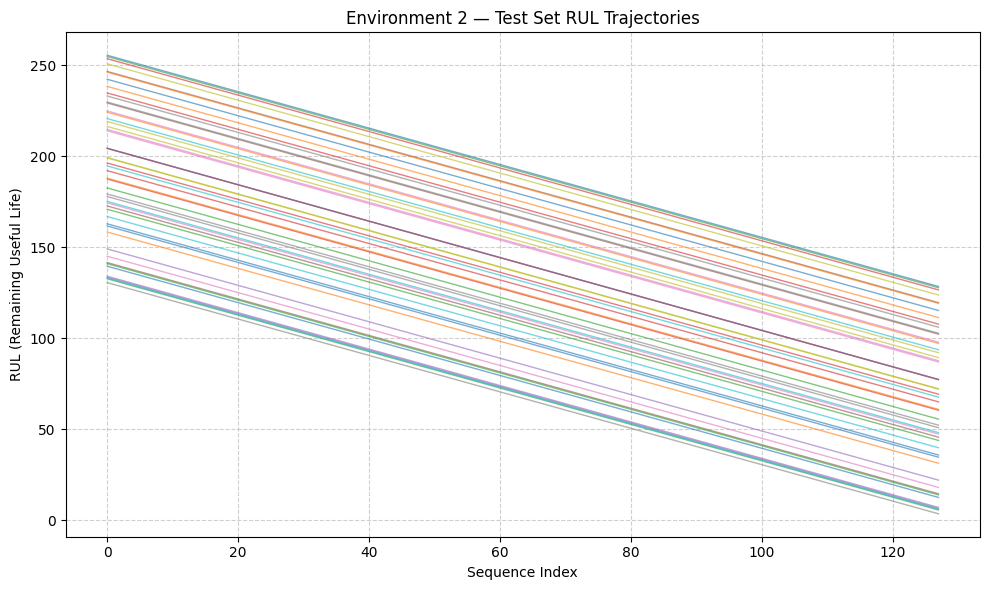

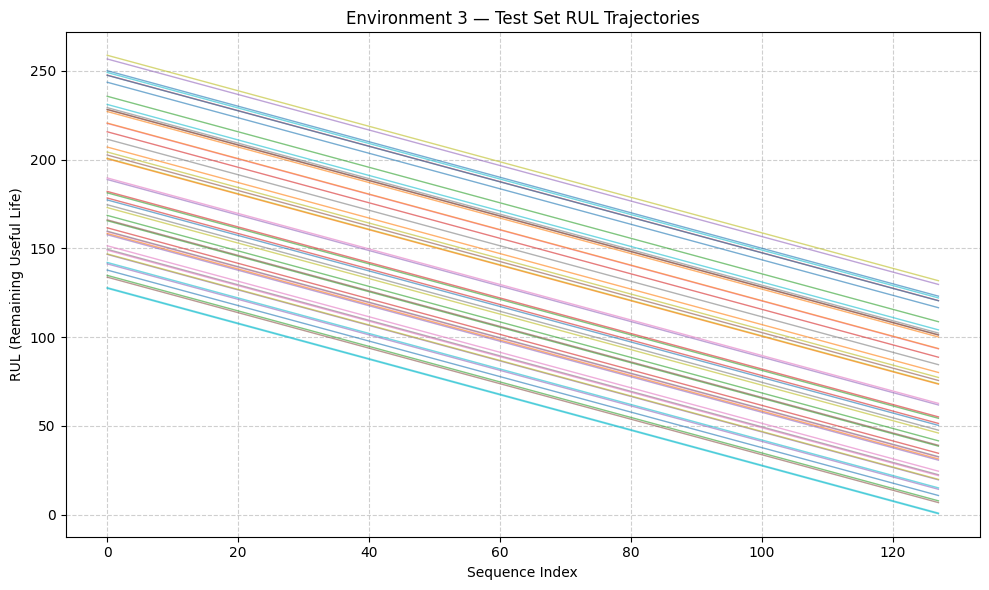

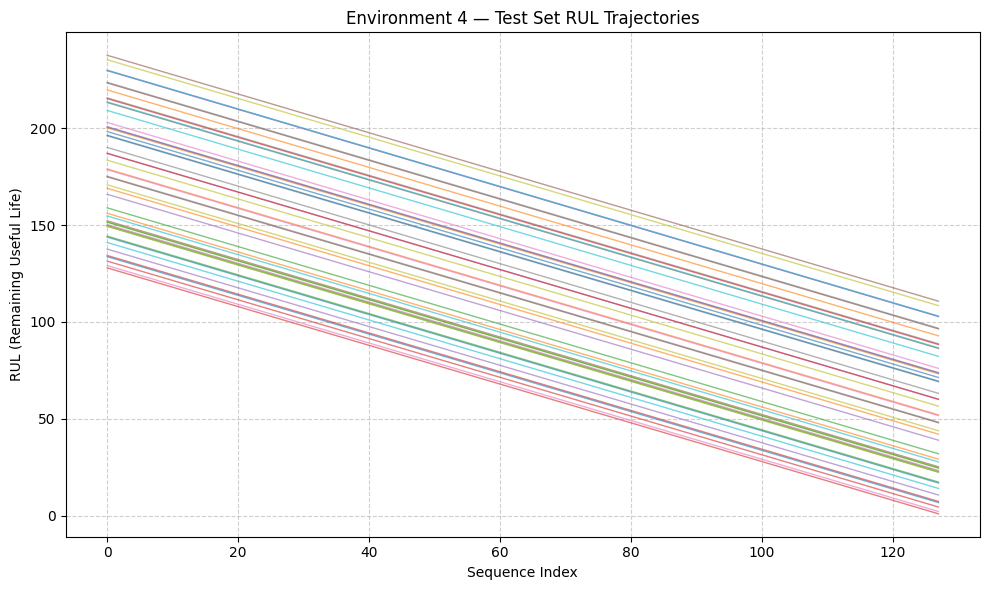

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def plot_env_test_rul_trajectories(test_client_2, test_client_3, test_client_4,
                                   max_engines_per_env=None):
    """
    Plot RUL trajectories for test set engines in each client (environments 2, 3, 4).

    Args:
        test_client_2: Test data dict for environment 2 with {"X": [X_all, X_time, X_env], "y": y_rul}
        test_client_3: Test data dict for environment 3
        test_client_4: Test data dict for environment 4
        max_engines_per_env: If test set is too large, limit max trajectories to plot (None = all)
    """
    clients = {
        2: test_client_2,
        3: test_client_3,
        4: test_client_4
    }

    for env_id in sorted(clients.keys()):
        client_data = clients[env_id]

        # Extract data: X = [X_allSensor, X_timeLast, X_envLast], y = y_lastRUL
        X_all_sensor = client_data["X"][0]  # (n_seq, seq_len, n_features)
        X_time_last = client_data["X"][1]   # (n_seq, time_dim)
        y_rul = client_data["y"]             # (n_seq, label_dim)

        if X_all_sensor.size == 0:
            print(f"Environment {env_id}: No test data available")
            continue

        n_sequences = X_all_sensor.shape[0]
        seq_len = X_all_sensor.shape[1]

        # Optional: limit number of sequences to plot
        indices = np.arange(n_sequences)
        if max_engines_per_env is not None and n_sequences > max_engines_per_env:
            rng = np.random.RandomState(42 + env_id)
            indices = rng.choice(indices, size=max_engines_per_env, replace=False)

        plt.figure(figsize=(10, 6))

        # Plot each trajectory
        for idx in indices:
            # Use sequence index as x-axis (0, 1, 2, ..., seq_len-1)
            x = np.arange(seq_len)
            # Get RUL for this sequence (last step value)
            rul_last = y_rul[idx, 0] if y_rul.ndim > 1 else y_rul[idx]

            # Create complete RUL trajectory (linear degradation from last RUL to 0)
            # RUL decreases linearly: at last step = rul_last, at end of life = 0
            # So the complete trajectory is: rul_last + (seq_len - 1 - x)
            rul_trajectory = rul_last + (seq_len - 1 - x)

            # Plot the complete RUL curve
            plt.plot(x, rul_trajectory, alpha=0.6, linewidth=1)

        plt.xlabel("Sequence Index")
        plt.ylabel("RUL (Remaining Useful Life)")
        plt.title(f"Environment {env_id} — Test Set RUL Trajectories")
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.tight_layout()
        plt.show()


plot_env_test_rul_trajectories(test_client_2, test_client_3, test_client_4, max_engines_per_env=50)


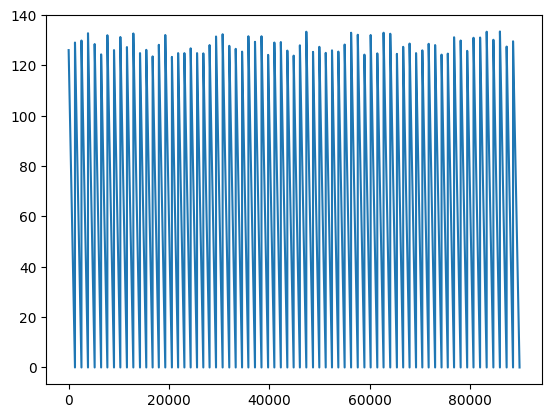

In [6]:
plt.plot(train_client_2['y'])

## 1.4 **step 0.2.** Model Perturbation and Pruning Framework for Federated LoRA Simulation. You need to do two thing by using this part：
1. **Just randomly choose any of the generated model weights, deploy it on your edge device model.** This model represents a bad model on edge device, then this bad model will trigger the model update demand to cloud. If used your pretrained model, they are all too good to trigger the updating demand.

2. The other models should be saved on the cloud, because cloud recieve all the model from edge. In fedrated learning scenario, according to its definition, we assume, these model are trained on limited training resource,limited data, limited environment, so they are bad, but because they can communicate with cloud, cloud can receieve these bad models' weights and their corresponding environment data, so cloud have the ability to combine they to get a stronger model. So here, we use model perturbation to simulate a series of model trained on edge divice under limited data and traiing resources, **you just build a file on the cloud to storage diffferent weights, if you can add some json file to add the working information of each model weights would be better.**（These json file has nothing to do with your deployment, just to make your weights management look professional, becasue, each weight have theri handbook to show the necessary information in json file）

3. **You should show how your edge device tansfer the weight to cloud by MQTT or any other aggrement,it should be a safety way with signature**, because FL on cloud are built on the basis of the weights it get from the edge.

Purpose:
This script generates multiple perturbed and sparsified variants of a base neural network model’s weights, simulating heterogeneous client models for federated learning experiments involving LoRA fine-tuning.

How it works:
It loads checkpoints (HDF5, PyTorch, or joblib/pickle), adds Gaussian noise scaled by the layer’s standard deviation, prunes small weights by percentile, and saves multiple reproducible variants under separate directories (normal vs. high-intensity updates).

Usage context:
Used to simulate decentralized model drift across clients before computing layer-wise weight deltas (ΔW) and initializing LoRA modules via SVD.

By applying this perturbation, we have a series of models from contributing device:

$model_{loc1}$,$model_{loc2}$,...,$model_{locn}$

**Pay attention, if you run this, you should run the lora training part together so that the pertbubation and lora are alignment. and their random seed are fixed to be repeatble**

In [7]:

# ====== 0) Imports ======
import os
import shutil
import time
import h5py
import numpy as np
from tqdm import tqdm
import joblib
import torch

# ====== 1) Configuration ======
# Source and destination roots
SRC_ROOT = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch"
DST_ROOT = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update"

# Expected weight file names inside each component folder
WEIGHT_FILES = ["encoderWts.h5", "decoderWts.h5", "hiAndRulWts.h5", "maskWts.h5"]

# Number of variants per model (N variants will be produced as <name>_1.h5 ... <name>_N.h5)
NUM_VARIANTS = 10

# Perturbation configs
# noise_ratio: Gaussian noise scale relative to tensor std
# sparsity: prune smallest |values| fraction (0.30 => prune bottom 30% by magnitude)
CFG_NORMAL     = {"noise_ratio": 0.30, "sparsity": 0.30}
CFG_HI_UPDATES = {"noise_ratio": 0.30, "sparsity": 0.30}

# Base seed for deterministic variant generation
SEED_BASE = 20251013


# ====== 2) Utilities ======
def ensure_dir(path: str):
    """Create directory if it doesn't exist."""
    os.makedirs(path, exist_ok=True)

def all_subdirs(path: str):
    """Return sorted list of subdirectories in given path."""
    return sorted([d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))])

def is_valid_hdf5(path: str) -> bool:
    """Check if file has valid HDF5 signature."""
    try:
        with open(path, "rb") as f:
            return f.read(8).startswith(b"\x89HDF\r\n\x1a\n")
    except Exception:
        return False

def torch_load_compat(path: str):
    """Load PyTorch checkpoint with compatibility for different versions."""
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

def try_load_torch(path: str):
    """
    Attempt to load a PyTorch checkpoint.
    Returns: (original_object, state_dict, is_nested_format)
    Raises ValueError if not a valid PyTorch checkpoint.
    """
    obj = torch_load_compat(path)

    # Handle nested format: {'state_dict': {...}, ...}
    if isinstance(obj, dict):
        if "state_dict" in obj and isinstance(obj["state_dict"], dict):
            return obj, obj["state_dict"], True
        if any(isinstance(v, torch.Tensor) for v in obj.values()):
            return obj, obj, False

    # Handle tuple format where first element is state_dict
    if isinstance(obj, tuple) and len(obj) > 0 and isinstance(obj[0], dict):
        if any(isinstance(v, torch.Tensor) for v in obj[0].values()):
            return obj, obj[0], False

    raise ValueError("Not a recognizable PyTorch checkpoint")

def try_load_joblib(path: str):
    """Load joblib/pickle serialized object (handles .h5 files saved with joblib)."""
    return joblib.load(path)

def list_float_datasets(h5file: h5py.File):
    """Recursively find all floating-point datasets in HDF5 file."""
    ds_paths = []
    def visitor(name, obj):
        if isinstance(obj, h5py.Dataset) and np.issubdtype(obj.dtype, np.floating):
            ds_paths.append(name)
    h5file.visititems(visitor)
    return ds_paths


# ====== 2.1) Perturb ops ======
def perturb_and_prune_array(arr: np.ndarray, rng: np.random.Generator, noise_ratio: float, sparsity: float):
    """
    Add Gaussian noise and apply magnitude-based pruning to numpy array.
    - noise_ratio: scale of Gaussian noise relative to array std
    - sparsity: fraction of smallest-magnitude values to zero out (0.1 = prune bottom 10%)
    """
    if arr.size == 0 or not np.issubdtype(arr.dtype, np.floating):
        return arr

    std = float(arr.std()) if float(arr.std()) > 0 else 1e-8
    out = arr + rng.normal(0.0, noise_ratio * std, size=arr.shape).astype(arr.dtype, copy=False)

    if 0.0 < sparsity < 1.0:
        flat_abs = np.abs(out).ravel()
        if not np.all(flat_abs == 0):
            thresh = np.percentile(flat_abs, sparsity * 100.0)
            out = out * (np.abs(out) >= thresh).astype(out.dtype, copy=False)

    return out

def perturb_torch_tensor(t: torch.Tensor, rng: np.random.Generator, noise_ratio: float, sparsity: float):
    """Apply perturbation and pruning to PyTorch tensor."""
    if not isinstance(t, torch.Tensor) or not torch.is_floating_point(t):
        return t
    np_arr = t.detach().cpu().numpy()
    np_out = perturb_and_prune_array(np_arr, rng, noise_ratio, sparsity)
    return torch.from_numpy(np_out).to(t.dtype)


# ====== 2.2) Selectors ======
# Skip batchnorm running stats where we can detect names
_BN_SKIP_TOKENS = ("running_mean", "running_var", "num_batches_tracked")

def _contains_any(hay: str, tokens):
    h = hay.lower()
    return any(tok.lower() in h for tok in tokens)

def _bn_like_name(name: str) -> bool:
    if not name:
        return False
    name = name.lower()
    return ("running_mean" in name) or ("running_var" in name) or ("num_batches_tracked" in name)

def should_perturb_torch(key: str, t: torch.Tensor) -> bool:
    """Only perturb keys that belong to encoder or RUL predictor; skip BN running stats."""
    if not (isinstance(t, torch.Tensor) and torch.is_floating_point(t)):
        return False
    k = str(key)
    if any(tok in k for tok in _BN_SKIP_TOKENS):
        return False
    # include if key mentions encoder or rul
    include = _contains_any(k, ("encoder", "rul", "rul_head", "rulpredictor", "rul_predictor", "predictor.rul"))
    return include

def should_perturb_h5_path(dspath: str, filename: str) -> bool:
    """
    HDF5 selection logic:
    - encoderWts.h5: perturb ALL float datasets (still skip BN running stats)
    - hiAndRulWts.h5: perturb ALL float datasets (still skip BN running stats)
    - other files: do not perturb
    """
    p = dspath.lower()
    fname = os.path.basename(filename).lower()
    if any(tok in p for tok in _BN_SKIP_TOKENS):
        return False

    if "encoderwts.h5" in fname:
        return True
    if "hiandrulwts.h5" in fname:
        return True
    return False

def should_perturb_path_like(path_like: str) -> bool:
    """Legacy path-based selector (often useless for pickle without names)."""
    p = path_like.lower()
    if any(tok in p for tok in _BN_SKIP_TOKENS):
        return False
    return ("encoder" in p) or ("rul" in p)


# ====== 2.3) Joblib perturbation (filename-driven) ======
def perturb_nested_structure_joblib(obj,
                                    rng: np.random.Generator,
                                    noise_ratio: float,
                                    sparsity: float,
                                    perturb_all: bool,
                                    path: str = ""):
    """
    Recursively perturb arrays/tensors inside a joblib/pickle object.

    - If `perturb_all` is True (filename indicates encoderWts/hiAndRulWts),
      perturb ALL floating arrays/tensors (still try to skip BN-like names if we can see them).
    - Else fall back to the old path-based selector (rarely triggered for pickle objects).

    Returns: (new_obj, changed_arrays, changed_elems, total_elems)
    """
    changed_arrays = 0
    changed_elems = 0
    total_elems   = 0

    def _perturb_np(a: np.ndarray, name_hint: str):
        nonlocal changed_arrays, changed_elems, total_elems
        if a.size == 0 or not np.issubdtype(a.dtype, np.floating):
            return a
        total_elems += a.size
        out = perturb_and_prune_array(a, rng, noise_ratio, sparsity)
        diffs = int(np.sum(a != out))
        if diffs > 0:
            changed_arrays += 1
            changed_elems  += diffs
        return out

    def _perturb_torch(t: torch.Tensor, name_hint: str):
        nonlocal changed_arrays, changed_elems, total_elems
        if not (isinstance(t, torch.Tensor) and torch.is_floating_point(t)):
            return t
        np_arr = t.detach().cpu().numpy()
        total_elems += np_arr.size
        np_out = perturb_and_prune_array(np_arr, rng, noise_ratio, sparsity)
        diffs = int(np.sum(np_arr != np_out))
        if diffs > 0:
            changed_arrays += 1
            changed_elems  += diffs
        return torch.from_numpy(np_out).to(t.dtype)

    if perturb_all:
        do_perturb_here = not _bn_like_name(path)
    else:
        do_perturb_here = should_perturb_path_like(path) and (not _bn_like_name(path))

    # Leaf cases
    if isinstance(obj, np.ndarray):
        return (_perturb_np(obj, path) if do_perturb_here else obj,
                changed_arrays, changed_elems, total_elems)

    if isinstance(obj, torch.Tensor):
        return (_perturb_torch(obj, path) if do_perturb_here else obj,
                changed_arrays, changed_elems, total_elems)

    # Containers
    if isinstance(obj, dict):
        new_d = {}
        for k, v in obj.items():
            v_new, ca, ce, te = perturb_nested_structure_joblib(
                v, rng, noise_ratio, sparsity, perturb_all, path=f"{path}.{k}"
            )
            new_d[k] = v_new
            changed_arrays += ca; changed_elems += ce; total_elems += te
        return new_d, changed_arrays, changed_elems, total_elems

    if isinstance(obj, (list, tuple)):
        new_list = []
        for i, v in enumerate(obj):
            v_new, ca, ce, te = perturb_nested_structure_joblib(
                v, rng, noise_ratio, sparsity, perturb_all, path=f"{path}[{i}]"
            )
            new_list.append(v_new)
            changed_arrays += ca; changed_elems += ce; total_elems += te
        return (type(obj)(new_list), changed_arrays, changed_elems, total_elems)

    # Other types unchanged
    return obj, changed_arrays, changed_elems, total_elems


# ====== 3) Variant Generation Functions ======
def make_variants_from_hdf5(src_h5_path: str, dst_dir: str, base_seed: int, num_variants: int,
                            noise_ratio: float, sparsity: float):
    """Generate perturbed variants of HDF5 file and record change evidence."""
    ensure_dir(dst_dir)
    stem, ext = os.path.splitext(os.path.basename(src_h5_path))

    for k in range(1, num_variants + 1):
        rng = np.random.default_rng(base_seed + k)
        out_path = os.path.join(dst_dir, f"{stem}_{k}{ext}")

        shutil.copy2(src_h5_path, out_path)
        changed_elems = 0
        changed_dsets = 0
        total_elems   = 0

        with h5py.File(out_path, "r+") as f:
            for dspath in list_float_datasets(f):
                if not should_perturb_h5_path(dspath, src_h5_path):
                    continue
                ds = f[dspath]
                arr = ds[()]
                total_elems += arr.size
                out = perturb_and_prune_array(arr, rng, noise_ratio, sparsity)
                diffs = np.sum(arr != out)
                if diffs > 0:
                    changed_dsets += 1
                    changed_elems += int(diffs)
                    ds[...] = out
            f.attrs["perturb_meta"] = (
                f"ts={int(time.time())}; noise={noise_ratio}; sparsity={sparsity}; "
                f"changed_dsets={changed_dsets}; changed_elems={changed_elems}; total_elems={total_elems}"
            )
        print(f"[HDF5] {out_path} -> changed_dsets={changed_dsets}, "
              f"changed_elems={changed_elems}/{total_elems}")

def make_variants_from_torch(src_path: str, dst_dir: str, base_seed: int, num_variants: int,
                             noise_ratio: float, sparsity: float):
    """Generate perturbed variants of PyTorch checkpoint (selective by key) with evidence."""
    ensure_dir(dst_dir)
    stem, ext = os.path.splitext(os.path.basename(src_path))
    base_obj, base_sd, is_nested = try_load_torch(src_path)

    for k in range(1, num_variants + 1):
        rng = np.random.default_rng(base_seed + k)
        changed_tensors = 0
        total_tensors   = 0

        new_sd = {}
        for key, val in base_sd.items():
            if isinstance(val, torch.Tensor) and torch.is_floating_point(val) and should_perturb_torch(key, val):
                total_tensors += 1
                out = perturb_torch_tensor(val, rng, noise_ratio, sparsity)
                if not torch.equal(out, val):
                    changed_tensors += 1
                new_sd[key] = out
            else:
                new_sd[key] = val

        if is_nested:
            new_obj = dict(base_obj)
            new_obj["state_dict"] = new_sd
            to_save = new_obj
        else:
            to_save = new_sd

        out_path = os.path.join(dst_dir, f"{stem}_{k}{ext}")
        torch.save(to_save, out_path)
        print(f"[TORCH] {out_path} -> changed_tensors={changed_tensors}/{total_tensors}")

def make_variants_from_joblib(src_path: str, dst_dir: str, base_seed: int, num_variants: int,
                              noise_ratio: float, sparsity: float):
    """
    Generate perturbed variants of joblib/pickle objects.
    IMPORTANT: If filename is encoderWts.h5 or hiAndRulWts.h5, we perturb ALL floats.
    """
    ensure_dir(dst_dir)
    stem, ext = os.path.splitext(os.path.basename(src_path))
    base_obj = try_load_joblib(src_path)

    lower_name  = os.path.basename(src_path).lower()
    perturb_all = ("encoderwts.h5" in lower_name) or ("hiandrulwts.h5" in lower_name)

    for k in range(1, num_variants + 1):
        rng = np.random.default_rng(base_seed + k)
        new_obj, changed_arrays, changed_elems, total_elems = perturb_nested_structure_joblib(
            base_obj, rng, noise_ratio, sparsity, perturb_all, path=""
        )
        out_path = os.path.join(dst_dir, f"{stem}_{k}{ext}")
        joblib.dump(new_obj, out_path)
        print(f"[JOBLIB] {out_path} -> changed_arrays={changed_arrays}, "
              f"changed_elems={changed_elems}/{total_elems}, perturb_all={perturb_all}")

def copy_variants_unmodified(src_path: str, dst_dir: str, num_variants: int):
    """For non-target files: create k copies <stem>_k.ext without any perturbation."""
    ensure_dir(dst_dir)
    stem, ext = os.path.splitext(os.path.basename(src_path))
    for k in range(1, num_variants + 1):
        out_path = os.path.join(dst_dir, f"{stem}_{k}{ext}")
        shutil.copy2(src_path, out_path)
        print(f"[COPY]  {src_path} -> {out_path}")


# ====== 4) Model Directory Processor ======
def process_one_model_dir(src_model_dir: str, dst_normal_dir: str, dst_hi_dir: str):
    """
    Process all weight files in a model directory.
    Creates two sets of variants: normal and HI_updates with different perturbation levels.
    Only encoder & RUL predictor are perturbed; other files are copied unmodified (k variants).
    """
    ensure_dir(dst_normal_dir)
    ensure_dir(dst_hi_dir)

    for fname in WEIGHT_FILES:
        src_path = os.path.join(src_model_dir, fname)
        if not os.path.isfile(src_path):
            print(f"[WARN] Missing file: {src_path}")
            continue

        # Decide whether this file should be perturbed or simply replicated
        lower_name = fname.lower()
        is_encoder_file = ("encoderwts.h5" in lower_name)
        is_hi_rul_file  = ("hiandrulwts.h5" in lower_name)

        # If the file is neither encoder nor hiAndRul, just copy variants unmodified
        if not (is_encoder_file or is_hi_rul_file):
            copy_variants_unmodified(src_path, dst_normal_dir, NUM_VARIANTS)
            copy_variants_unmodified(src_path, dst_hi_dir, NUM_VARIANTS)
            continue

        # Determine file format and generate variants (selective inside)
        seed_offset = abs(hash((src_model_dir, fname))) % 10_000_000

        # Try HDF5 format
        if is_valid_hdf5(src_path):
            print(f"[HDF5] Generating selective variants for: {src_path}")
            make_variants_from_hdf5(src_path, dst_normal_dir, SEED_BASE + seed_offset,
                                    NUM_VARIANTS, **CFG_NORMAL)
            make_variants_from_hdf5(src_path, dst_hi_dir, SEED_BASE + 777 + seed_offset,
                                    NUM_VARIANTS, **CFG_HI_UPDATES)
            continue

        # Try PyTorch format
        try:
            _ = try_load_torch(src_path)
            print(f"[TORCH] Generating selective variants for: {src_path}")
            make_variants_from_torch(src_path, dst_normal_dir, SEED_BASE + seed_offset,
                                     NUM_VARIANTS, **CFG_NORMAL)
            make_variants_from_torch(src_path, dst_hi_dir, SEED_BASE + 777 + seed_offset,
                                     NUM_VARIANTS, **CFG_HI_UPDATES)
            continue
        except Exception:
            pass

        # Try joblib/pickle format
        try:
            _ = try_load_joblib(src_path)
            print(f"[JOBLIB] Generating selective variants for: {src_path}")
            make_variants_from_joblib(src_path, dst_normal_dir, SEED_BASE + seed_offset,
                                      NUM_VARIANTS, **CFG_NORMAL)
            make_variants_from_joblib(src_path, dst_hi_dir, SEED_BASE + 777 + seed_offset,
                                      NUM_VARIANTS, **CFG_HI_UPDATES)
            continue
        except Exception as e:
            print(f"[SKIP] Cannot process file: {src_path}")
            print(f"       Error: {e}")


# ====== 5) Main Execution ======
def main():
    """
    Main workflow:
    1. Find all model subdirectories in source root
    2. For each subdirectory, process all weight files
    3. Generate two sets of variants (normal and HI_updates)
       - Only encoder & RUL predictor are perturbed
       - Other files are replicated unmodified for each k
    """
    ensure_dir(DST_ROOT)
    model_dirs = all_subdirs(SRC_ROOT)

    if not model_dirs:
        raise RuntimeError(f"No subfolders found under {SRC_ROOT}")

    print(f"Found {len(model_dirs)} model subfolders:")
    for d in model_dirs:
        print(f" - {d}")

    for sub in tqdm(model_dirs, desc="Processing all subfolders"):
        src_model_dir = os.path.join(SRC_ROOT, sub)
        dst_normal_dir = os.path.join(DST_ROOT, sub)
        dst_hi_dir     = os.path.join(DST_ROOT, f"{sub}_HI_updates")
        process_one_model_dir(src_model_dir, dst_normal_dir, dst_hi_dir)

    print(f"\n✅ Done. New weights saved under: {DST_ROOT}")

# Execute
if __name__ == "__main__":
    main()


Found 4 model subfolders:
 - bestModelReac
 - bestModelSep
 - bestModelStrip
 - bestModelSys


Processing all subfolders:   0%|          | 0/4 [00:00<?, ?it/s]

[JOBLIB] Generating selective variants for: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelReac/encoderWts.h5
[JOBLIB] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/encoderWts_1.h5 -> changed_arrays=10, changed_elems=103905/103906, perturb_all=True
[JOBLIB] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/encoderWts_2.h5 -> changed_arrays=9, changed_elems=103904/103906, perturb_all=True
[JOBLIB] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/encoderWts_3.h5 -> changed_arrays=9, changed_elems=103904/103906, perturb_all=True
[JOBLIB] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/encoderWts_4.h5 -> changed_arrays=9, changed_elems=103904/103906, perturb_all=True
[JOBLIB] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/b

Processing all subfolders:  25%|██▌       | 1/4 [00:06<00:18,  6.29s/it]

[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelReac/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/maskWts_1.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelReac/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/maskWts_2.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelReac/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/maskWts_3.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelReac/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac/maskWts_4.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epo

Processing all subfolders:  50%|█████     | 2/4 [00:11<00:11,  5.83s/it]

[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelSep/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelSep/maskWts_1.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelSep/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelSep/maskWts_2.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelSep/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelSep/maskWts_3.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelSep/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelSep/maskWts_4.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestM

Processing all subfolders:  75%|███████▌  | 3/4 [00:17<00:05,  5.60s/it]

[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelStrip/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelStrip/maskWts_1.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelStrip/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelStrip/maskWts_2.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelStrip/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelStrip/maskWts_3.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelStrip/maskWts.h5 -> /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelStrip/maskWts_4.h5
[COPY]  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestMo

Processing all subfolders: 100%|██████████| 4/4 [00:18<00:00,  4.52s/it]

[JOBLIB] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelSys_HI_updates/hiAndRulWts_10.h5 -> changed_arrays=17, changed_elems=12882/12884, perturb_all=True
[WARN] Missing file: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelSys/maskWts.h5

✅ Done. New weights saved under: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update


#2 Beofre your deployment, see the different models'performance

This section，nothing to do with your real deployment，just to show you different model‘s result for deeping your understanding.




## 2.1. **This part has nothing to do with your deployment, just because I need to generate these figure for paper writing, I combine your results plotting code  to build this, if you want, you can use this function, because all my testing results are drawn by this "evaluate_clients_2_3_4_on_test" function**:

Because we are doing FL in the cloud, the cloud can see data from various environments and devices, so we do a one-time loading and draw the result graph of all environments.

“vaeSys_initiator=”this position you put your model here can also test on all environment.
'''
summary = evaluate_clients_2_3_4_on_test(
    test_client_2=test_client_2,
    test_client_3=test_client_3,
    test_client_4=test_client_4,
    vaeSys_initiator=vaeSys_initiator,
    config=config,
    save_csv_path="checkpoint/client_predictions/test_metrics_clients_2_3_4_initiator.csv",
    visualize_each=True,
    save_dir="checkpoint/client_predictions/",
    # Enable trajectory-based testing
    norData=norData,
    preData=preData,
    trajectory_based_test=True,
    normalize_hi=True,
    show_redundant_shutdown=False,
    subplot_num_row=20,
    subplot_num_col=5,
)
'''

If not, just use your old version.


Function definition for testing and aggregating results

I asked GPT to help me aggregate the results according to your code, and then defined the calling functions of your original results that you want to output here.

In [8]:
# -*- coding: utf-8 -*-
"""
Per-Client TEST Evaluation for SystemModel (revised for dict-based splits)
--------------------------------------------------------------------------------

What's inside:
- MatPlot: comprehensive plotting helper from utility.plot
- _to_numpy, _safe_feature_mean: helpers
- test_client_split_with_model: runs inference on a single split dict and computes metrics
- visualize_client_predictions_matplot: MatPlot-like plotting for predictions
- evaluate_clients_2_3_4_on_test: evaluate all three clients on test splits and summarize
- test_client_trajectory_based: trajectory-based testing with HI normalization
- visualize_trajectories_subplot: subplot visualization for all trajectories

CRITICAL UPDATES FOR DICT-BASED SPLITS:
- Adapted to work with dict format from build_env_clients_2_3_4
- Each split dict has keys: {"X": [X_allSensor, X_time, X_env], "y": y_lastRUL}
- X_time and X_env are FULL SEQUENCES (shape: [N, seq_len, dim])
- We extract the LAST timestep for model input: X_time[:, -1, :] and X_env[:, -1, :]
- y_lastRUL is already the last timestep RUL with shape [N, 1] - no need to reshape
"""

import os
import numpy as np
from typing import Any, Dict, List, Optional, Tuple
from tqdm import tqdm

# ==============================================================================
# MatPlot helper (import from utility.plot)
# ==============================================================================
from utility.matpilotDraw   import MatPlot

# ==============================================================================
# Utilities
# ==============================================================================
def _to_numpy(x: Any) -> np.ndarray:
    """
    Convert TF/PyTorch/NumPy inputs to a NumPy array safely.
    """
    if hasattr(x, "numpy"):
        return x.numpy()
    try:
        import torch  # noqa: F401
        import torch as _torch
        if isinstance(x, _torch.Tensor):  # type: ignore[attr-defined]
            return x.detach().cpu().numpy()
    except Exception:
        pass
    return np.asarray(x)


def _safe_feature_mean(arr: np.ndarray, n_samples: int) -> np.ndarray:
    """
    Compute mean over feature/channel dimension robustly.
    Many HI arrays are [N, D, ...]. We want a per-sample scalar trend.
    """
    try:
        return arr[:n_samples].mean(axis=1)
    except Exception:
        arr2 = arr[:n_samples].reshape(n_samples, -1)
        return arr2.mean(axis=1)


# ==============================================================================
# Core: single-split evaluation (adapted for dict-based splits from build_env_clients_2_3_4)
# ==============================================================================
def test_client_split_with_model(
    split_data: Dict[str, Any],
    client_id: Any,
    vaeSys_initiator: Any,
    config: Dict[str, Any],
    split_name: str = "test",
) -> Dict[str, Any]:
    """
    Run SystemModel on a single client's split (dict format from build_env_clients_2_3_4).

    CRITICAL: This function is adapted to work with the NEW dict-based split format:
    - split_data["X"] = [X_allSensor, X_time, X_env]
      * X_allSensor: (N, seq_len, n_features) - full sensor sequences (NORMALIZED)
      * X_time: (N, seq_len, time_dim) - full time sequences (NORMALIZED)
      * X_env: (N, seq_len, env_dim) - full environment sequences (NORMALIZED)
    - split_data["y"] = y_lastRUL
      * y_lastRUL: (N, 1) - TRUE RUL at the LAST timestep (UNNORMALIZED from original data)

    The model expects inputs with last timestep for time and env:
    - model_input = [X_allSensor, X_time[:, -1, :], X_env[:, -1, :]]

    Args:
        split_data: dict with keys "X" (list of [X_allSensor, X_time, X_env]) and "y" (y_lastRUL)
        client_id: identifier for the client (e.g., 2, 3, 4)
        vaeSys_initiator: model instance with method getHIandRUL(input=[seqX, time, env])
        config: dict with model configuration
        split_name: name of the split for logging (e.g., "test", "val", "train")

    Returns:
        results: dict with numpy arrays:
            - 'hi_reac', 'hi_sep', 'hi_strip', 'hi_sys', 'hi_matrix'
            - 'rul_pred', 'rul_true', 'time_values'
            - 'metrics' (mae/rmse/smape/r2)
    """
    print("=" * 80)
    print(f"Testing Client {client_id} - {split_name.upper()} Split")
    print("=" * 80)

    # Extract data from split_data dict
    X_list = split_data.get("X", [])
    y_true = split_data.get("y", np.array([]))

    if len(X_list) != 3:
        raise ValueError(f"Expected X to contain 3 arrays [X_allSensor, X_time, X_env], got {len(X_list)}")

    # Extract arrays from dict format
    # CRITICAL: X_time and X_env are FULL SEQUENCES from build_env_clients_2_3_4
    X_allSensor = _to_numpy(X_list[0])  # shape: (N, seq_len, n_features) - normalized sensor features
    X_time_full = _to_numpy(X_list[1])  # shape: (N, seq_len, time_dim) - normalized time sequences
    X_env_full = _to_numpy(X_list[2])   # shape: (N, seq_len, env_dim) - normalized env sequences
    y_true = _to_numpy(y_true)          # shape: (N, 1) - TRUE RUL at last timestep (unnormalized)

    n_samples = X_allSensor.shape[0]

    print(f"Total samples: {n_samples}")
    print(f"Model configuration:")
    print(f"  - Sequence length: {config.get('seqLength')}")
    print(f"  - Input features:  {config.get('inReac')}")
    print(f"  - HI selection dim:{config.get('hiSelectionDim', 120)}")

    if n_samples == 0:
        print("Warning: No samples in this split. Returning empty results.")
        return {
            "hi_reac": np.array([]),
            "hi_sep": np.array([]),
            "hi_strip": np.array([]),
            "hi_sys": np.array([]),
            "hi_matrix": np.array([]),
            "rul_pred": np.array([]),
            "rul_true": np.array([]),
            "time_values": np.array([]),
            "metrics": {"mae": np.nan, "rmse": np.nan, "smape": np.nan, "r2": np.nan}
        }

    # Extract LAST timestep for time and env to match model expectations
    # This is CRITICAL: the model expects (N, time_dim) and (N, env_dim) for last timestep
    X_time_last = X_time_full[:, -1, :]  # shape: (N, time_dim) - last timestep
    X_env_last = X_env_full[:, -1, :]    # shape: (N, env_dim) - last timestep

    print(f"Input shapes:")
    print(f"  - X_allSensor (full sequences): {X_allSensor.shape}")
    print(f"  - X_time (full sequences): {X_time_full.shape}")
    print(f"  - X_env (full sequences): {X_env_full.shape}")
    print(f"  - X_time_last (last timestep for model): {X_time_last.shape}")
    print(f"  - X_env_last (last timestep for model): {X_env_last.shape}")
    print(f"  - y_true (last timestep RUL): {y_true.shape}")

    # Run model inference with LAST timestep for time and env
    model_input = [X_allSensor, X_time_last, X_env_last]
    hiReac, hiSep, hiStrip, hiSystem, predictedRul, hiMatrixOutput = vaeSys_initiator.getHIandRUL(input=model_input)

    # Convert to numpy
    hi_reac = _to_numpy(hiReac)
    hi_sep = _to_numpy(hiSep)
    hi_strip = _to_numpy(hiStrip)
    hi_sys = _to_numpy(hiSystem)
    hi_matrix = _to_numpy(hiMatrixOutput)
    y_pred = _to_numpy(predictedRul)

    # Use LAST timestep time values for visualization (already extracted)
    time_vals = X_time_last.reshape(-1) if X_time_last.size > 0 else np.array([])

    # Flatten y arrays for metric computation
    y_true_flat = y_true.reshape(-1)
    y_pred_flat = y_pred.reshape(-1)

    # Sanity checks
    for name, arr in [("time", time_vals), ("rul_true", y_true_flat), ("rul_pred", y_pred_flat)]:
        if np.isnan(arr).any() or np.isinf(arr).any():
            raise ValueError(f"[NaN/Inf] Found in {name}")

    print(f"\nProcessed samples: {y_true_flat.shape[0]}")
    print(f"Time range: {time_vals.min():.3f} -> {time_vals.max():.3f}")
    print(f"True RUL  : min={y_true_flat.min():.3f}  max={y_true_flat.max():.3f}")
    print(f"Pred RUL  : min={y_pred_flat.min():.3f}  max={y_pred_flat.max():.3f}")

    # Compute metrics (using sMAPE instead of MAPE to avoid division by zero)
    mae = float(np.mean(np.abs(y_pred_flat - y_true_flat)))
    rmse = float(np.sqrt(np.mean((y_pred_flat - y_true_flat) ** 2)))

    # sMAPE: Symmetric Mean Absolute Percentage Error (avoids division by zero)
    # sMAPE = 100 * mean(|y_true - y_pred| / (|y_true| + |y_pred|))
    denominator = np.abs(y_true_flat) + np.abs(y_pred_flat) + 1e-8
    smape = float(np.mean(np.abs(y_true_flat - y_pred_flat) / denominator) * 200.0)

    ss_res = float(np.sum((y_true_flat - y_pred_flat) ** 2))
    ss_tot = float(np.sum((y_true_flat - np.mean(y_true_flat)) ** 2) + 1e-12)
    r2 = float(1.0 - ss_res / ss_tot)

    print("\n" + "=" * 80)
    print(f"Evaluation Metrics ({split_name.upper()} - Client {client_id})")
    print("=" * 80)
    print(f"  MAE:   {mae:.4f}")
    print(f"  RMSE:  {rmse:.4f}")
    print(f"  sMAPE: {smape:.2f}%")
    print(f"  R2:    {r2:.4f}")

    results = {
        "hi_reac": hi_reac,
        "hi_sep": hi_sep,
        "hi_strip": hi_strip,
        "hi_sys": hi_sys,
        "hi_matrix": hi_matrix,
        "rul_pred": y_pred_flat,
        "rul_true": y_true_flat,
        "time_values": time_vals,
        "metrics": {"mae": mae, "rmse": rmse, "smape": smape, "r2": r2}
    }
    return results


# ==============================================================================
# Trajectory-based testing with HI normalization
# ==============================================================================
def test_client_trajectory_based(
    norData: Any,
    preData: Any,
    vaeSys_initiator: Any,
    environment_idx: int = 2,
    normalize_hi: bool = True,
    show_redundant_shutdown: bool = False,
) -> Dict[str, Any]:
    """
    Test client using trajectory-based approach with HI normalization.

    Args:
        norData: normalized data array
        preData: preprocessor instance with methods getTensorData and normalizeHIInGeneral
        vaeSys_initiator: model instance with method getHIandRUL
        environment_idx: environment index to test (e.g., 2 for client 2)
        normalize_hi: whether to normalize HI values
        show_redundant_shutdown: whether to show redundant shutdown information

    Returns:
        results: dict containing HI values, RUL predictions, and time arrays for all trajectories
    """
    print("=" * 80)
    print(f"Trajectory-Based Testing for Environment {environment_idx}")
    print("=" * 80)

    # Extract data for the specified environment
    data = norData[environment_idx]
    trajectory_id = data["Id"]
    reactor = data[preData.headline["reactor"]]
    separator = data[preData.headline["separator"]]
    stripper = data[preData.headline["stripper"]]
    all_sensor = data[preData.headline["allWithoutLabelNoBias"]]
    rul = data["rul"]
    env = data["environmentID"]
    time_traj = data["Time"]

    # Get total number of trajectories
    total_traject = len(np.unique(trajectory_id))
    print(f"Total trajectories in environment {environment_idx}: {total_traject}")

    # Initialize storage dictionaries
    hi_env = {}
    rul_env = {}
    hi_env["Reac"] = []
    rul_env["Reac"] = []
    hi_env["Sep"] = []
    rul_env["Sep"] = []
    hi_env["Strip"] = []
    rul_env["Strip"] = []
    hi_env["Sys"] = []
    rul_env["Sys"] = []
    hi_env["multipliedMatrix"] = []
    time_draw = []

    # Process each trajectory with progress bar (suppressing individual prints)
    print(f"Processing {total_traject} trajectories...")
    for idx in tqdm(range(total_traject), desc=f"Client {environment_idx}", ncols=100):
        get_at_idx = idx + 1

        # Get tensor data for current trajectory
        seq_x_all_sensor_train, seq_x_rul_train, seq_x_train_env, seq_time = preData.getTensorData(
            dataList=[all_sensor, rul, env, time_traj],
            trajectId=trajectory_id,
            shuffle=False,
            getAtIdx=get_at_idx,
            seqLength=preData.config["seqLength"],
            overlap=preData.config["overLap"]
        )

        seq_time_train = seq_time[:, -1, :]

        # Prepare model input
        x_predict = [seq_x_all_sensor_train, seq_time[:, -1, :], seq_x_train_env[:, -1, :]]

        # Get HI and RUL predictions
        hi_reac, hi_sep, hi_strip, hi_system, predicted_rul, hi_matrix_output = vaeSys_initiator.getHIandRUL(input=x_predict)

        # Store results
        time_draw.append(seq_time_train)
        hi_env["Reac"].append(hi_reac)
        hi_env["Sep"].append(hi_sep)
        hi_env["Strip"].append(hi_strip)
        hi_env["Sys"].append(hi_system)
        hi_env["multipliedMatrix"].append(hi_matrix_output)
        rul_env["Sys"].append(predicted_rul)

    # Normalize HI if requested
    if normalize_hi:
        [hi_env["Reac"], hi_env["Sep"], hi_env["Strip"], hi_env["Sys"]], time_draw, rul_env["Sys"], hi_env["multipliedMatrix"] = preData.normalizeHIInGeneral(
            inData=[hi_env["Reac"], hi_env["Sep"], hi_env["Strip"], hi_env["Sys"]],
            time=time_draw,
            rul=rul_env["Sys"],
            multipliedMt=hi_env["multipliedMatrix"],
            indexToShutdown=2,
            showRedundantShutdown=show_redundant_shutdown
        )

    print(f"✓ Completed trajectory-based testing for environment {environment_idx}")
    print(f"  Total trajectories processed: {len(time_draw)}")

    results = {
        "hi_env": hi_env,
        "rul_env": rul_env,
        "time_draw": time_draw,
        "environment_idx": environment_idx,
        "total_trajectories": total_traject
    }

    return results


# ==============================================================================
# Trajectory subplot visualization
# ==============================================================================
def visualize_trajectories_subplot(
    trajectory_results: Dict[str, Any],
    save_dir: str = "checkpoint/client_predictions/",
    num_row: int = 20,
    num_col: int = 5,
) -> None:
    """
    Visualize trajectory-based results using subplot for all trajectories.

    Args:
        trajectory_results: results dict from test_client_trajectory_based
        save_dir: directory to save plots
        num_row: number of rows in subplot grid
        num_col: number of columns in subplot grid
    """
    os.makedirs(save_dir, exist_ok=True)

    hi_env = trajectory_results["hi_env"]
    rul_env = trajectory_results["rul_env"]
    time_draw = trajectory_results["time_draw"]
    environment_idx = trajectory_results["environment_idx"]

    print("\n" + "=" * 80)
    print(f"Creating Subplot Visualizations for Environment {environment_idx}")
    print("=" * 80)

    # Plot HI components subplot
    plot1 = MatPlot()
    plot1.subPlotMultiImg(
        inY=[hi_env["Reac"], hi_env["Sep"], hi_env["Strip"], hi_env["Sys"]],
        inX=time_draw,
        color=['green', 'blue', 'yellow', 'red'],
        numRow=num_row,
        numCol=num_col
    )
    print(f"✓ Created HI components subplot (Reactor, Separator, Stripper, System)")

    # Plot RUL subplot
    plot2 = MatPlot()
    plot2.subPlotMultiImg(
        inY=[rul_env["Sys"]],
        inX=time_draw,
        color=['g'],
        numRow=num_row,
        numCol=num_col
    )
    print(f"✓ Created RUL predictions subplot")

    print("=" * 80)


# ==============================================================================
# MatPlot-like visualization
# ==============================================================================
def visualize_client_predictions_matplot(
    results: Dict[str, Any],
    client_id: Any,
    split: str = "test",
    save_dir: str = "checkpoint/client_predictions/",
    also_plot_error: bool = True,
):
    """
    Draw prediction plots using MatPlot:
      - One plot of True vs Pred RUL over time
      - One plot of error vs sample index
      - Component HI plots
      - System HI plots
    """
    mpl = MatPlot()
    os.makedirs(save_dir, exist_ok=True)

    time_vals = results.get("time_values", np.array([]))
    y_true = results.get("rul_true", np.array([]))
    y_pred = results.get("rul_pred", np.array([]))
    hi_reac = results.get("hi_reac", np.array([]))
    hi_sep = results.get("hi_sep", np.array([]))
    hi_strip = results.get("hi_strip", np.array([]))
    hi_sys = results.get("hi_sys", np.array([]))

    if time_vals.size == 0 or y_true.size == 0 or y_pred.size == 0:
        print(f"No data to visualize for client {client_id} {split} split.")
        return

    # Sort by time for better visualization
    sort_idx = np.argsort(time_vals)
    time_sorted = time_vals[sort_idx]
    y_true_sorted = y_true[sort_idx]
    y_pred_sorted = y_pred[sort_idx]

    # Plot True vs Pred RUL using draw2DMultipleY
    mpl.draw2DMultipleY(
        xCoor=time_sorted,
        yCoor=[y_true_sorted, y_pred_sorted],
        yLabel="RUL",
        xLabel="Time",
        title=f"Client {client_id} — {split.upper()} — True vs Pred RUL",
        saveFig=True,
        direction=save_dir,
        savedName=f"client_{client_id}_{split}_true_vs_pred",
        useLegend=True,
        legend=["True RUL", "Pred RUL"],
        color=["blue", "green"]
    )
    print(f"✓ Saved: {os.path.join(save_dir, f'client_{client_id}_{split}_true_vs_pred.png')}")

    if also_plot_error:
        # Plot error vs sample index
        err = y_pred - y_true
        x_idx = np.arange(err.shape[0], dtype=np.float32)
        mpl.draw2D(
            xCoor=x_idx,
            yCoor=err,
            yLabel="Error (Pred - True)",
            xLabel="Sample Index",
            title=f"Client {client_id} — {split.upper()} — RUL Prediction Error",
            saveFig=True,
            direction=save_dir,
            savedName=f"client_{client_id}_{split}_error",
            color="red"
        )
        print(f"✓ Saved: {os.path.join(save_dir, f'client_{client_id}_{split}_error.png')}")

    # Plot Component HIs
    if hi_reac.size > 0 and hi_sep.size > 0 and hi_strip.size > 0:
        hi_reac_mean = _safe_feature_mean(hi_reac, hi_reac.shape[0])
        hi_sep_mean = _safe_feature_mean(hi_sep, hi_sep.shape[0])
        hi_strip_mean = _safe_feature_mean(hi_strip, hi_strip.shape[0])

        mpl.draw2DMultipleY(
            xCoor=time_sorted,
            yCoor=[hi_reac_mean[sort_idx], hi_sep_mean[sort_idx], hi_strip_mean[sort_idx]],
            yLabel="Component HIs",
            xLabel="Cycle",
            title=f"Client {client_id} — {split.upper()} — Component HIs",
            saveFig=True,
            direction=save_dir,
            savedName=f"client_{client_id}_{split}_component_his",
            useLegend=True,
            legend=["Reactor", "Separator", "Stripper"],
            color=["blue", "green", "orange"],
            yLim=[0, 1.1]
        )
        print(f"✓ Saved: {os.path.join(save_dir, f'client_{client_id}_{split}_component_his.png')}")

    # Plot System HI
    if hi_sys.size > 0:
        hi_sys_mean = _safe_feature_mean(hi_sys, hi_sys.shape[0])

        mpl.draw2D(
            xCoor=time_sorted,
            yCoor=hi_sys_mean[sort_idx],
            yLabel="System HI",
            xLabel="Cycle",
            title=f"Client {client_id} — {split.upper()} — System HI",
            saveFig=True,
            direction=save_dir,
            savedName=f"client_{client_id}_{split}_system_hi",
            color="red"
        )
        print(f"✓ Saved: {os.path.join(save_dir, f'client_{client_id}_{split}_system_hi.png')}")

    # Plot All HIs together
    if hi_reac.size > 0 and hi_sep.size > 0 and hi_strip.size > 0 and hi_sys.size > 0:
        mpl.draw2DMultipleY(
            xCoor=time_sorted,
            yCoor=[hi_reac_mean[sort_idx], hi_sep_mean[sort_idx], hi_strip_mean[sort_idx], hi_sys_mean[sort_idx]],
            yLabel="All HIs",
            xLabel="Cycle",
            title=f"Client {client_id} — {split.upper()} — All HIs",
            saveFig=True,
            direction=save_dir,
            savedName=f"client_{client_id}_{split}_all_his",
            useLegend=True,
            legend=["Reactor", "Separator", "Stripper", "System"],
            color=["blue", "green", "orange", "red"],
            yLim=[0, 1.1]
        )
        print(f"✓ Saved: {os.path.join(save_dir, f'client_{client_id}_{split}_all_his.png')}")


# ==============================================================================
# All-clients TEST evaluation and summary table
# ==============================================================================
def evaluate_clients_2_3_4_on_test(
    test_client_2: Dict[str, Any],
    test_client_3: Dict[str, Any],
    test_client_4: Dict[str, Any],
    vaeSys_initiator: Any,
    config: Dict[str, Any],
    save_csv_path: Optional[str] = None,
    visualize_each: bool = True,
    save_dir: str = "checkpoint/client_predictions/",
    # New parameters for trajectory-based testing
    norData: Optional[Any] = None,
    preData: Optional[Any] = None,
    trajectory_based_test: bool = False,
    normalize_hi: bool = True,
    show_redundant_shutdown: bool = False,
    subplot_num_row: int = 20,
    subplot_num_col: int = 5,
) -> Dict[str, Any]:
    """
    Evaluate TEST splits for clients 2, 3, and 4 and summarize.

    CRITICAL: This function is adapted to work with dict-based splits from build_env_clients_2_3_4:
    - Each test_client_* is a dict with keys {"X": [X_allSensor, X_time, X_env], "y": y_lastRUL}
    - X arrays contain FULL SEQUENCES (X_time and X_env have shape [N, seq_len, dim])
    - We extract the last timestep internally for model input

    Args:
        test_client_2: test split dict for client 2
        test_client_3: test split dict for client 3
        test_client_4: test split dict for client 4
        vaeSys_initiator: model instance
        config: model configuration dict
        save_csv_path: optional path to save per-client metrics CSV
        visualize_each: whether to save visualization plots for each client
        save_dir: directory to save plots
        norData: normalized data for trajectory-based testing
        preData: preprocessor instance for trajectory-based testing
        trajectory_based_test: whether to perform trajectory-based testing
        normalize_hi: whether to normalize HI in trajectory-based testing
        show_redundant_shutdown: whether to show redundant shutdown info
        subplot_num_row: number of rows for subplot visualization
        subplot_num_col: number of columns for subplot visualization

    Returns:
        summary: dict with per-client DataFrame, macro/micro averages, and detailed results
    """
    print("\n" + "#" * 80)
    print("# Evaluating Clients 2, 3, 4 on TEST Split")
    print("# Using dict-based splits from build_env_clients_2_3_4")
    print("#" * 80)

    test_splits = {
        2: test_client_2,
        3: test_client_3,
        4: test_client_4,
    }

    rows: List[Dict[str, Any]] = []
    detailed_results: Dict[Any, Dict[str, Any]] = {}
    trajectory_results: Dict[Any, Dict[str, Any]] = {}

    for client_id, split_data in test_splits.items():
        try:
            res = test_client_split_with_model(
                split_data=split_data,
                client_id=client_id,
                vaeSys_initiator=vaeSys_initiator,
                config=config,
                split_name="test",
            )
            detailed_results[client_id] = res

            m = res.get("metrics", {})
            mae = float(m.get("mae", np.nan))
            rmse = float(m.get("rmse", np.nan))
            smape = float(m.get("smape", np.nan))
            r2 = float(m.get("r2", np.nan))
            n = int(res["rul_true"].shape[0]) if isinstance(res.get("rul_true"), np.ndarray) else 0

            rows.append({
                "client_id": client_id,
                "n_samples": n,
                "MAE": mae,
                "RMSE": rmse,
                "sMAPE(%)": smape,
                "R2": r2
            })

            if visualize_each:
                visualize_client_predictions_matplot(
                    results=res,
                    client_id=client_id,
                    split="test",
                    save_dir=save_dir,
                    also_plot_error=True,
                )

            # Perform trajectory-based testing if requested
            if trajectory_based_test and norData is not None and preData is not None:
                print(f"\n{'=' * 80}")
                print(f"Performing Trajectory-Based Testing for Client {client_id}")
                print(f"{'=' * 80}")

                traj_res = test_client_trajectory_based(
                    norData=norData,
                    preData=preData,
                    vaeSys_initiator=vaeSys_initiator,
                    environment_idx=client_id,
                    normalize_hi=normalize_hi,
                    show_redundant_shutdown=show_redundant_shutdown,
                )
                trajectory_results[client_id] = traj_res

                # Visualize trajectory-based results
                visualize_trajectories_subplot(
                    trajectory_results=traj_res,
                    save_dir=save_dir,
                    num_row=subplot_num_row,
                    num_col=subplot_num_col,
                )

        except Exception as e:
            print(f"[WARN] Client {client_id} evaluation failed: {e}")
            rows.append({
                "client_id": client_id,
                "n_samples": 0,
                "MAE": np.nan,
                "RMSE": np.nan,
                "sMAPE(%)": np.nan,
                "R2": np.nan
            })

    # Summary table
    import pandas as pd
    df = pd.DataFrame(rows).sort_values(by="client_id").reset_index(drop=True)

    macro_mae = df["MAE"].mean(skipna=True)
    macro_rmse = df["RMSE"].mean(skipna=True)
    macro_smape = df["sMAPE(%)"].mean(skipna=True)
    macro_r2 = df["R2"].mean(skipna=True)

    # Micro averages by pooling samples
    pooled_pred, pooled_true = [], []
    for client_id, res in detailed_results.items():
        y_hat = res.get("rul_pred")
        y_true = res.get("rul_true")
        if isinstance(y_hat, np.ndarray) and isinstance(y_true, np.ndarray) and y_hat.size > 0 and y_true.size > 0:
            pooled_pred.append(y_hat.reshape(-1))
            pooled_true.append(y_true.reshape(-1))

    if pooled_pred:
        pooled_pred = np.concatenate(pooled_pred, axis=0)
        pooled_true = np.concatenate(pooled_true, axis=0)
        micro_mae = float(np.mean(np.abs(pooled_pred - pooled_true)))
        micro_rmse = float(np.sqrt(np.mean((pooled_pred - pooled_true) ** 2)))
        denominator = np.abs(pooled_true) + np.abs(pooled_pred) + 1e-8
        micro_smape = float(np.mean(np.abs(pooled_true - pooled_pred) / denominator) * 200.0)
        ss_res = float(np.sum((pooled_true - pooled_pred) ** 2))
        ss_tot = float(np.sum((pooled_true - np.mean(pooled_true)) ** 2) + 1e-12)
        micro_r2 = float(1.0 - ss_res / ss_tot)
    else:
        micro_mae = micro_rmse = micro_smape = micro_r2 = np.nan

    # Pretty print
    print("\n" + "=" * 80)
    print("Per-Client TEST Metrics")
    print("=" * 80)
    with np.printoptions(precision=4, suppress=True):
        print(df.to_string(index=False))

    print("\n" + "-" * 80)
    print("Macro Average (unweighted across clients):")
    print(f"  MAE={macro_mae:.4f}  RMSE={macro_rmse:.4f}  sMAPE%={macro_smape:.2f}  R2={macro_r2:.4f}")
    print("Micro Average (weighted by samples):")
    print(f"  MAE={micro_mae:.4f}  RMSE={micro_rmse:.4f}  sMAPE%={micro_smape:.2f}  R2={micro_r2:.4f}")
    print("-" * 80)

    if save_csv_path:
        os.makedirs(os.path.dirname(save_csv_path), exist_ok=True)
        df.to_csv(save_csv_path, index=False)
        print(f"✓ Saved per-client TEST metrics to: {save_csv_path}")

    summary = {
        "per_client_df": df,
        "macro_avg": {"mae": macro_mae, "rmse": macro_rmse, "smape": macro_smape, "r2": macro_r2},
        "micro_avg": {"mae": micro_mae, "rmse": micro_rmse, "smape": micro_smape, "r2": micro_r2},
        "detailed_results": detailed_results,
        "trajectory_results": trajectory_results,
    }
    return summary


## 2.2. This part has nothing to do with your deployment, just use the code your give me to analayze the data and model I modified to show how bad model will look like, and you will see their HI are easy to trigger the update demand.



### 2.2.1 Declare the contributing model (contributor for fedrated learning), let's call it vaeSys_contributor
Our first edge device or first client is a model I got from you that was trained on limited samples and limited training resources (only trained for 5 epochs).

To not change your code, I first put the perturbed weights, which are to be loaded, into a temporary folder, and then rename the perturbed weights with numbered names to the names in your own function for loading the model, and then I can use your original code directly.

The “mirror” acts as a temporary, standardized directory that copies and renames the selected perturbed weight files (e.g., encoderWts_7.h5 → encoderWts.h5) into the structure expected by the model loader. This lets the system load variant weights seamlessly without altering the original checkpoint layout, while also providing MD5 and dataset-stat prints to verify which exact files are being used.

In [9]:
# --- Robust import & load of your perturbed model weights (encoder + RUL only) ---

import os
import sys
import shutil
import pathlib
import hashlib
import h5py
import numpy as np
from tensorflow.keras import backend as K

# =============================================================================
# Project bootstrap
# =============================================================================
PROJECT_ROOT = pathlib.Path("/content/drive/MyDrive/Duc_an_XAI_edge_cooperation")

# Ensure 'kun' and 'kun/model' are proper Python packages
for pkg_dir in [PROJECT_ROOT / "kun", PROJECT_ROOT / "kun" / "model"]:
    pkg_dir.mkdir(parents=True, exist_ok=True)
    (pkg_dir / "__init__.py").touch(exist_ok=True)

# Put the project on sys.path
path_str = str(PROJECT_ROOT.resolve())
if path_str not in sys.path:
    sys.path.insert(0, path_str)

# (Optional) clear TF session to avoid leftover graphs if you re-run this cell
K.clear_session()


# =============================================================================
# Helpers
# =============================================================================
def _comp_dir(root: str, sub: str, use_hi: bool) -> str:
    """Return the directory that holds numbered variants for a component."""
    return os.path.join(root, f"{sub}{'_HI_updates' if use_hi else ''}")

def _ensure_empty_dir(path: str):
    """Ensure a directory exists and is empty."""
    if os.path.isdir(path):
        shutil.rmtree(path)
    os.makedirs(path, exist_ok=True)

def _md5(path: str) -> str:
    """MD5 of the entire file (debug)."""
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def _first_float_stats(h5_path: str, max_items: int = 3):
    """
    Return up to 'max_items' (name, shape, mean, std) for float datasets in an HDF5 file.
    This gives you a quick fingerprint that should differ between original and perturbed variants.
    """
    out = []
    with h5py.File(h5_path, "r") as f:
        def visitor(n, o):
            if len(out) >= max_items:
                return
            if isinstance(o, h5py.Dataset) and np.issubdtype(o.dtype, np.floating):
                a = o[()]
                out.append((n, a.shape, float(a.mean()), float(a.std())))
        f.visititems(visitor)
    return out

def _print_h5_debug(label: str, path: str):
    """Print MD5 and a few dataset stats for quick verification."""
    print(f"[DEBUG] {label}: {path}")
    try:
        print(f"        MD5: { _md5(path) }")
        stats = _first_float_stats(path)
        if stats:
            for i, (n, shp, m, s) in enumerate(stats, 1):
                print(f"        ds#{i}: name={n}, shape={shp}, mean={m:.6f}, std={s:.6f}")
        else:
            print("        (no float datasets found)")
    except Exception as e:
        print(f"        (debug read failed: {e})")

def _copy_variant(src_dir: str, dst_dir: str, mapping_with_suffix: dict, idx: int, debug_compare_to: str = None):
    """
    Copy numbered variant files and rename them to expected standard names.
    Example mapping: {"encoderWts": "encoderWts"} will copy encoderWts_7.h5 -> encoderWts.h5
    """
    os.makedirs(dst_dir, exist_ok=True)
    for expected_name, base_stem in mapping_with_suffix.items():
        # Numbered variant (e.g., encoderWts_7.h5)
        src = os.path.join(src_dir, f"{base_stem}_{idx}.h5")
        dst = os.path.join(dst_dir, f"{expected_name}.h5")

        if not os.path.isfile(src):
            raise FileNotFoundError(f"Variant file not found: {src}")

        print(f"[COPY] {src}  ->  {dst}")
        shutil.copy2(src, dst)

        # Debug: compare to the original (if provided)
        if debug_compare_to is not None:
            orig = os.path.join(debug_compare_to, base_stem + ".h5")
            if os.path.isfile(orig):
                _print_h5_debug("ORIG ", orig)
            else:
                print(f"[DEBUG] ORIG not found (skipped): {orig}")
        _print_h5_debug("MIRROR", dst)  # show what we actually load afterwards


# =============================================================================
# Main function to load variant model
# =============================================================================
def load_variant_model(config, variant_idx=7, use_hi_updates=True):
    """
    Load a perturbed model variant with specified configuration.

    Args:
        config: Configuration dictionary containing model parameters
        variant_idx: Index of the variant to load (e.g., 7 for encoderWts_7.h5)
        use_hi_updates: Whether to use variants from "_HI_updates" folders

    Returns:
        vaeSys_contributor: Loaded SystemModel instance with variant weights
    """
    # =============================================================================
    # Variant selection
    # =============================================================================
    VARIANT_IDX = variant_idx
    USE_HI_UPDATES = use_hi_updates

    # Where your generated variants live (the destination from your perturbation script)
    VARIANTS_ROOT = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/"

    # For sanity checks against originals (optional but recommended)
    ORIGINALS_ROOT = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/"

    # Temporary mirror: we will copy and rename numbered files here to the canonical names
    TMP_MIRROR_ROOT = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/"
    os.makedirs(TMP_MIRROR_ROOT, exist_ok=True)

    # =============================================================================
    # Source & destination directories (4 components)
    # =============================================================================
    SRC_REAC_DIR = _comp_dir(VARIANTS_ROOT, "bestModelReac", USE_HI_UPDATES)
    SRC_SEP_DIR = _comp_dir(VARIANTS_ROOT, "bestModelSep", USE_HI_UPDATES)
    SRC_STRIP_DIR = _comp_dir(VARIANTS_ROOT, "bestModelStrip", USE_HI_UPDATES)
    SRC_SYS_DIR = _comp_dir(VARIANTS_ROOT, "bestModelSys", USE_HI_UPDATES)

    DST_REAC_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelReac")
    DST_SEP_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelSep")
    DST_STRIP_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelStrip")
    DST_SYS_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelSys")

    # Rebuild mirror directories fresh
    _ensure_empty_dir(DST_REAC_DIR)
    _ensure_empty_dir(DST_SEP_DIR)
    _ensure_empty_dir(DST_STRIP_DIR)
    _ensure_empty_dir(DST_SYS_DIR)

    # Each component requires three files; system head needs the HI+RUL file
    COMP_MAPPING = {
        "encoderWts": "encoderWts",
        "decoderWts": "decoderWts",
        "maskWts": "maskWts",
    }
    SYS_MAPPING = {
        "hiAndRulWts": "hiAndRulWts",
    }

    print("=== Copying selected variants into the mirror (with debug fingerprints) ===")
    _copy_variant(SRC_REAC_DIR, DST_REAC_DIR, COMP_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelReac"))
    _copy_variant(SRC_SEP_DIR, DST_SEP_DIR, COMP_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelSep"))
    _copy_variant(SRC_STRIP_DIR, DST_STRIP_DIR, COMP_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelStrip"))
    _copy_variant(SRC_SYS_DIR, DST_SYS_DIR, SYS_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelSys"))

    print("\n=== Mirror is ready. About to build and load the model from the mirror ===\n")

    required_keys = ["seqLength", "inReac"]
    missing = [k for k in required_keys if k not in config]
    if missing:
        raise KeyError(f"Missing required config keys: {missing}")

    # Force System mode and ensure default HI selection dimension (adjust if your code differs)
    config["component"] = "Sys"
    config.setdefault("hiSelectionDim", 120)

    # The model should read weights from these subfolders when `freezeComponents` is True
    component_dir_root = TMP_MIRROR_ROOT

    # Instantiate your model
    vaeSys_contributor = SystemModel(config=config, componentDir=component_dir_root)

    # Build the model to initialize layers. This shape list must match your architecture.
    vaeSys_contributor.build(input_shape=[
        (None, config["seqLength"], config["inReac"]),  # main sequence
        (None, 1, config["inReac"]),                    # initial state
        (None, 1),                                      # scalar/time feature
        (None, config["hiSelectionDim"]),               # HI selection vector
    ])

    # Print the summary (optional but helpful)
    vaeSys_contributor.summary()

    # Prepare the canonical directories we just mirrored to
    modelDirComp1 = os.path.join(component_dir_root, "bestModelReac")
    modelDirComp2 = os.path.join(component_dir_root, "bestModelSep")
    modelDirComp3 = os.path.join(component_dir_root, "bestModelStrip")
    modelDirSys = os.path.join(component_dir_root, "bestModelSys")

    print("\n=== Loading weights from the MIRROR ===")
    print("Reac:  ", modelDirComp1)
    print("Sep:   ", modelDirComp2)
    print("Strip: ", modelDirComp3)
    print("Sys:   ", modelDirSys)
    vaeSys_contributor.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)
    print("✓ Weights loaded from the selected variant ("
          f"idx={VARIANT_IDX}, HI_updates={USE_HI_UPDATES}).")

    return vaeSys_contributor


# =============================================================================
# Example usage / function call
# =============================================================================
if __name__ == "__main__":

    # Load the variant model
    # You can change variant_idx (0-9) and use_hi_updates (True/False) as needed
    vaeSys_contributor = load_variant_model(
        config=config,
        variant_idx=7,# We pertubte 10 different model,just choose any of them you want to see
        use_hi_updates=True
    )

    print("\n✅ Model loaded successfully and ready for use!")


=== Copying selected variants into the mirror (with debug fingerprints) ===
[COPY] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac_HI_updates/encoderWts_7.h5  ->  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac/encoderWts.h5
[DEBUG] ORIG : /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/bestModelReac/encoderWts.h5
        MD5: 747c2c5715247558f61a5f9224347bfc
        (debug read failed: Unable to synchronously open file (file signature not found))
[DEBUG] MIRROR: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac/encoderWts.h5
        MD5: 732c27579dfce0f7d6387fd35e38f744
        (debug read failed: Unable to synchronously open file (file signature not found))
[COPY] /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/bestModelReac_HI_updates/decoderWts_7.h5  ->  /content/dri

Process:4034||2025-10-27 10:10:28,900-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Process:4034||2025-10-27 10:10:28,956-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:10:28,965-DEBUG [ipython-input-427612

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Model: "system_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_selection                │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_selection_1              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_selection_2              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hi_system_and_rul               │ ?                      │   0 (unbuilt) │
│ (HiSystemAndRul)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636,842 (2.43 MB)

 Trainable params: 12,884 (50.33 KB)

 Non-trainable params: 623,958 (2.38 MB)

Process:4034||2025-10-27 10:10:29,192-INFO [ipython-input-4276122690.py:load_weights():907]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSys
Process:4034||2025-10-27 10:10:29,265-INFO [ipython-input-4276122690.py:load_weights():939]:Loaded the model at the direction:/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_co


=== Loading weights from the MIRROR ===
Reac:   /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac
Sep:    /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep
Strip:  /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Sys:    /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSys
✓ Weights loaded from the selected variant (idx=7, HI_updates=True).

✅ Model loaded successfully and ready for use!


#### Mask the vaeSys_contributor model on each environment

In [10]:
binaryMaskReac, probsReac     = vaeSys_contributor.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)
binaryMaskReac, probsReac     = vaeSys_contributor.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

binaryMaskReac, probsReac     = vaeSys_contributor.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)





The number of selected sensor in the environment 1 is 18.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 0.00013888846 |  0.0   |
| 1  |         A Feed         |  0.0001402943 |  0.0   |
| 2  |      A and C Feed      | 0.00016257293 |  0.0   |
| 3  |         Purge          |   0.99979335  |  1.0   |
| 4  |       Separator        |   0.9997458   |  1.0   |
| 5  |        Stripper        |   0.9995932   |  1.0   |
| 6  |    Reactor Coolant     |  0.0002269053 |  0.0   |
| 7  |   Condenser Coolant    |   0.9998771   |  1.0   |
| 8  |       msv A Feed       | 0.00013811837 |  0.0   |
| 9  |       msv D Feed       |   0.99984586  |  1.0   |
| 10 |       msv E Feed       | 0.00012960982 |  0.0   |
| 11 |    msv A and C Feed    |   0.99977845  |  1.0   |
| 12 |      Recycle Flow      | 0.00024071561 |  0.0   |
| 13 |   Reactor Feed Rate   

#### Test the vaeSys_contributor on each environment


################################################################################
# Evaluating Clients 2, 3, 4 on TEST Split
# Using dict-based splits from build_env_clients_2_3_4
################################################################################
Testing Client 2 - TEST Split
Total samples: 19276
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (19276, 128, 45)
  - X_time (full sequences): (19276, 128, 1)
  - X_env (full sequences): (19276, 128, 1)
  - X_time_last (last timestep for model): (19276, 1)
  - X_env_last (last timestep for model): (19276, 1)
  - y_true (last timestep RUL): (19276, 1)

Processed samples: 19276
Time range: 12.700 -> 145.700
True RUL  : min=0.000  max=133.000
Pred RUL  : min=-24.900  max=50.946

Evaluation Metrics (TEST - Client 2)
  MAE:   45.3273
  RMSE:  48.3516
  sMAPE: 121.95%
  R2:    -0.6940
✓ Saved: checkpoint/client_predictions/client_2_test_tru

Client 2: 100%|███████████████████████████████████████████████████| 100/100 [00:43<00:00,  2.29it/s]


✓ Completed trajectory-based testing for environment 2
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 2


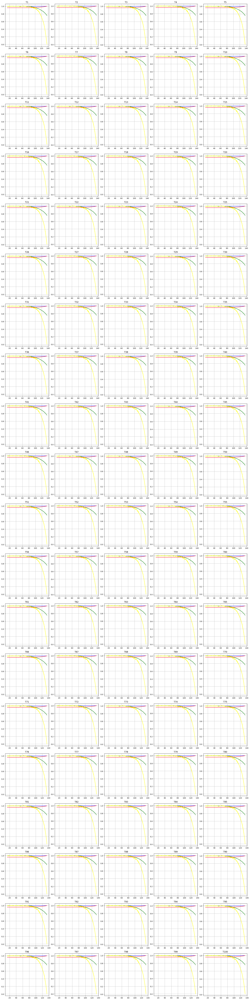

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


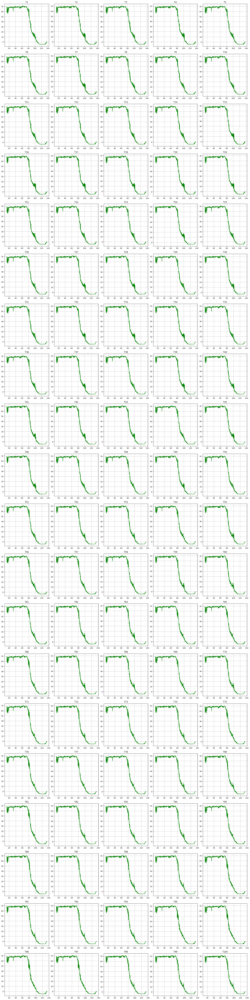

✓ Created RUL predictions subplot
Testing Client 3 - TEST Split
Total samples: 19587
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (19587, 128, 45)
  - X_time (full sequences): (19587, 128, 1)
  - X_env (full sequences): (19587, 128, 1)
  - X_time_last (last timestep for model): (19587, 1)
  - X_env_last (last timestep for model): (19587, 1)
  - y_true (last timestep RUL): (19587, 1)

Processed samples: 19587
Time range: 12.700 -> 147.900
True RUL  : min=0.000  max=135.200
Pred RUL  : min=-20.294  max=19.663

Evaluation Metrics (TEST - Client 3)
  MAE:   73.1167
  RMSE:  81.2609
  sMAPE: 187.92%
  R2:    -3.6347
✓ Saved: checkpoint/client_predictions/client_3_test_true_vs_pred.png
✓ Saved: checkpoint/client_predictions/client_3_test_error.png
✓ Saved: checkpoint/client_predictions/client_3_test_component_his.png
✓ Saved: checkpoint/client_predictions/client_3_test_system_hi.png
✓ Saved: che

Client 3: 100%|███████████████████████████████████████████████████| 100/100 [00:39<00:00,  2.53it/s]


✓ Completed trajectory-based testing for environment 3
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 3


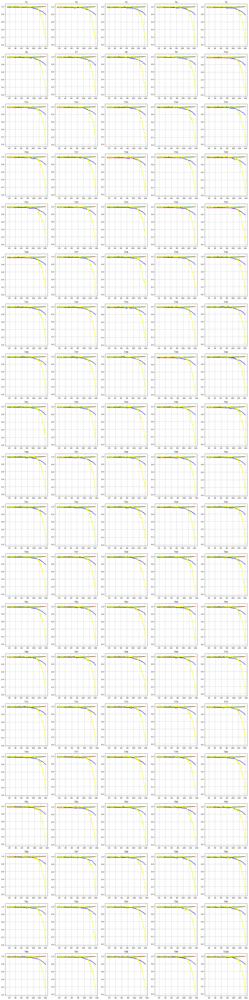

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


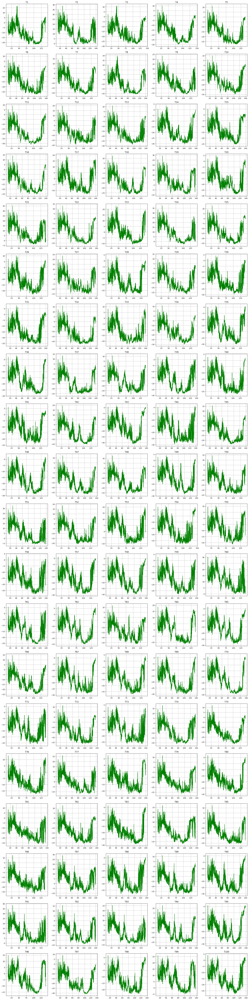

✓ Created RUL predictions subplot
Testing Client 4 - TEST Split
Total samples: 16511
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (16511, 128, 45)
  - X_time (full sequences): (16511, 128, 1)
  - X_env (full sequences): (16511, 128, 1)
  - X_time_last (last timestep for model): (16511, 1)
  - X_env_last (last timestep for model): (16511, 1)
  - y_true (last timestep RUL): (16511, 1)

Processed samples: 16511
Time range: 12.700 -> 127.700
True RUL  : min=0.000  max=115.000
Pred RUL  : min=-22.261  max=27.983

Evaluation Metrics (TEST - Client 4)
  MAE:   62.3417
  RMSE:  68.0930
  sMAPE: 193.09%
  R2:    -3.5731
✓ Saved: checkpoint/client_predictions/client_4_test_true_vs_pred.png
✓ Saved: checkpoint/client_predictions/client_4_test_error.png
✓ Saved: checkpoint/client_predictions/client_4_test_component_his.png
✓ Saved: checkpoint/client_predictions/client_4_test_system_hi.png
✓ Saved: che

Client 4: 100%|███████████████████████████████████████████████████| 100/100 [00:39<00:00,  2.54it/s]


✓ Completed trajectory-based testing for environment 4
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 4


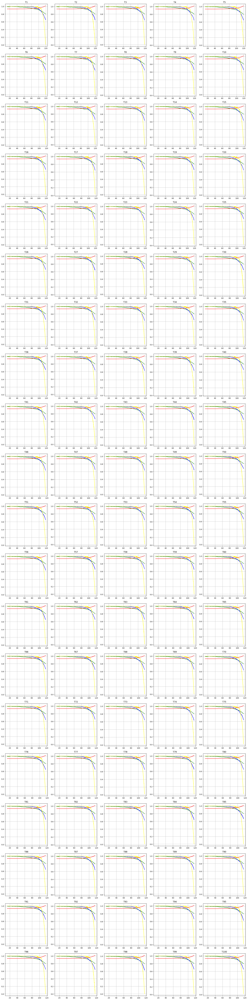

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


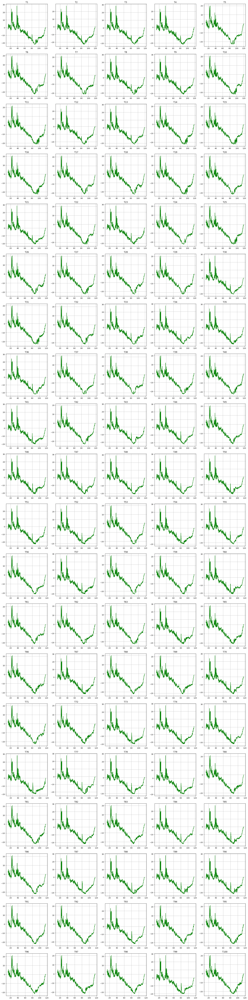

✓ Created RUL predictions subplot

Per-Client TEST Metrics
 client_id  n_samples       MAE      RMSE   sMAPE(%)        R2
         2      19276 45.327305 48.351597 121.949528 -0.694018
         3      19587 73.116749 81.260893 187.920195 -3.634724
         4      16511 62.341738 68.092994 193.089833 -3.573085

--------------------------------------------------------------------------------
Macro Average (unweighted across clients):
  MAE=60.2619  RMSE=65.9018  sMAPE%=167.65  R2=-2.6339
Micro Average (weighted by samples):
  MAE=60.2303  RMSE=67.3208  sMAPE%=166.50  R2=-2.4684
--------------------------------------------------------------------------------
✓ Saved per-client TEST metrics to: checkpoint/client_predictions/test_metrics_clients_2_3_4_contributor.csv
✓ Saved detailed results to: checkpoint/client_predictions/client_contributor_2_test_results.pkl
✓ Saved detailed results to: checkpoint/client_predictions/client_contributor_3_test_results.pkl
✓ Saved detailed results to: chec

In [11]:

if __name__ == "__main__":

    summary = evaluate_clients_2_3_4_on_test(
        test_client_2=test_client_2,
        test_client_3=test_client_3,
        test_client_4=test_client_4,
        vaeSys_initiator=vaeSys_contributor,
        config=config,
        save_csv_path="checkpoint/client_predictions/test_metrics_clients_2_3_4_contributor.csv",
        visualize_each=True,
        save_dir="checkpoint/client_predictions/",
        # Enable trajectory-based testing
        norData=norData,
        preData=preData,
        trajectory_based_test=True,
        normalize_hi=True,
        show_redundant_shutdown=False,
        subplot_num_row=20,
        subplot_num_col=5,
    )

    # Optional: Save detailed results for each client
    import joblib
    for client_id, res in summary["detailed_results"].items():
        out_pkl = f"checkpoint/client_predictions/client_contributor_{client_id}_test_results.pkl"
        os.makedirs(os.path.dirname(out_pkl), exist_ok=True)
        joblib.dump(res, out_pkl)
        print(f"✓ Saved detailed results to: {out_pkl}")

    # Save trajectory-based results
    for client_id, traj_res in summary["trajectory_results"].items():
        out_pkl = f"checkpoint/client_predictions/client_contributor_{client_id}_trajectory_results.pkl"
        os.makedirs(os.path.dirname(out_pkl), exist_ok=True)
        joblib.dump(traj_res, out_pkl)
        print(f"✓ Saved trajectory-based results to: {out_pkl}")


### 2.2.2 Try global best model
That one you trained and saved after 200 epoches

#### Declare the blobal best model, let's call it vaeSys_global_best

We will not use it in training, but use it as our ideal model to compare its results with our fedrated learning one on HI and RUL prediction, because generally and theoritically, our FL model will perform better than the contributors and initiator, but worse than global best.

In [12]:
# --- Robust import & reload of your model class ---

from tensorflow.keras import backend as K
import sys
import importlib, pathlib

# 1) Project root (adjust if needed)
PROJECT_ROOT = pathlib.Path("/content/drive/MyDrive/Duc_an_XAI_edge_cooperation")

# 2) Ensure 'kun' is a package
for pkg_dir in [PROJECT_ROOT / "kun", PROJECT_ROOT / "kun" / "model"]:
    pkg_dir.mkdir(parents=True, exist_ok=True)
    (pkg_dir / "__init__.py").touch(exist_ok=True)

# 3) Put project on sys.path
path_str = str(PROJECT_ROOT.resolve())
if path_str not in sys.path:
    sys.path.insert(0, path_str)

# Required config keys
required_keys = ["seqLength", "inReac"]
missing = [k for k in required_keys if k not in config]
if missing:
    raise KeyError(f"Missing required config keys: {missing}")

config["component"] = "Sys"

# If your HI selection size is configurable, set it here.
# Your logs show 120; keep that unless your code says otherwise.
config.setdefault("hiSelectionDim", 120)

curDir = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/"

vaeSys_global_best = SystemModel(config=config, componentDir=curDir)

# IMPORTANT: Build with FOUR inputs to keep the graph connected:
#   1) main sequence         : (None, seqLength, inReac)
#   2) init/state input      : (None, 1, inReac)
#   3) scalar/time input     : (None, 1)
#   4) HI selection vector   : (None, hiSelectionDim)  <-- previously missing
vaeSys_global_best.build(input_shape=[
    (None, config["seqLength"], config["inReac"]),
    (None, 1, config["inReac"]),
    (None, 1),
    (None, config["hiSelectionDim"]),
])

vaeSys_global_best.summary()

# --- Load weights (paths must exist) ---
modelDirComp1 = curDir + "bestModelReac"
modelDirComp2 = curDir + "bestModelSep"
modelDirComp3 = curDir + "bestModelStrip"
modelDirSys   = curDir + "bestModelSys"

vaeSys_global_best.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)
print("✓ Weights loaded successfully.")




The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:14:12,105-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelStrip


The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:14:21,699-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:14:21,708-DEBUG [ipython-input-4276122690.py:__init__():321]:The shape of hiSelectionInput (None, 120)
Process:4034||2025-10-27 10:14:21,728-DEBUG [ipython-input-4276122690.py:__init__():328]:The shape of multiplied matrix (None, 3)
Process:4034||2025-10-27 10:14:21,737-DEBUG [ipython-input-4276122690.py:__init__():335]:The shape of min, max and linear HI ((None, 1), (None, 1), (None, 1))
Process:4034||2025-10-27 10:14:21,739-DEBUG [ipython-input-4276122690.py:__init__():338]:The shap

Model: "system_model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_selection_3              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_selection_4              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_selection_5              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hi_system_and_rul_1             │ ?                      │   0 (unbuilt) │
│ (HiSystemAndRul)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636,842 (2.43 MB)

 Trainable params: 12,884 (50.33 KB)

 Non-trainable params: 623,958 (2.38 MB)

Process:4034||2025-10-27 10:14:21,811-INFO [ipython-input-4276122690.py:load_weights():907]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelSys
Process:4034||2025-10-27 10:14:22,840-INFO [ipython-input-4276122690.py:load_weights():939]:Loaded the model at the direction:/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_200epoch/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_cooperati

✓ Weights loaded successfully.


#### Mask the vaeSys_global_best model on each environment

In [13]:
binaryMaskReac, probsReac     = vaeSys_global_best.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)
binaryMaskReac, probsReac     = vaeSys_global_best.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

binaryMaskReac, probsReac     = vaeSys_global_best.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)





The number of selected sensor in the environment 1 is 26.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         |      1.0      |  1.0   |
| 1  |         A Feed         | 1.0593292e-12 |  0.0   |
| 2  |      A and C Feed      |      1.0      |  1.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 1.0623663e-12 |  0.0   |
| 7  |   Condenser Coolant    |  1.065079e-12 |  0.0   |
| 8  |       msv A Feed       |  1.059976e-12 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       |      1.0      |  1.0   |
| 11 |    msv A and C Feed    |      1.0      |  1.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Test the vaeSys_global_best on each environment



################################################################################
# Evaluating Clients 2, 3, 4 on TEST Split
# Using dict-based splits from build_env_clients_2_3_4
################################################################################
Testing Client 2 - TEST Split
Total samples: 19276
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (19276, 128, 45)
  - X_time (full sequences): (19276, 128, 1)
  - X_env (full sequences): (19276, 128, 1)
  - X_time_last (last timestep for model): (19276, 1)
  - X_env_last (last timestep for model): (19276, 1)
  - y_true (last timestep RUL): (19276, 1)

Processed samples: 19276
Time range: 12.700 -> 145.700
True RUL  : min=0.000  max=133.000
Pred RUL  : min=1.477  max=128.095

Evaluation Metrics (TEST - Client 2)
  MAE:   2.4187
  RMSE:  2.9659
  sMAPE: 8.60%
  R2:    0.9936
✓ Saved: checkpoint/client_predictions/client_2_test_true_vs_p

Client 2: 100%|███████████████████████████████████████████████████| 100/100 [00:33<00:00,  2.96it/s]


✓ Completed trajectory-based testing for environment 2
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 2


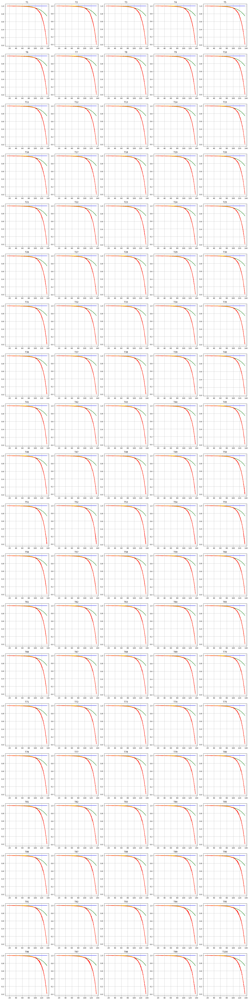

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


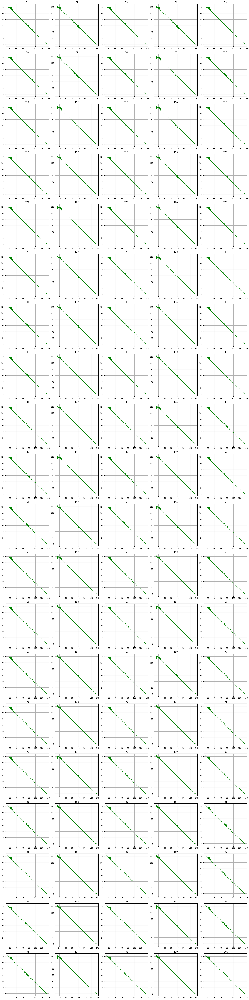

✓ Created RUL predictions subplot
Testing Client 3 - TEST Split
Total samples: 19587
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (19587, 128, 45)
  - X_time (full sequences): (19587, 128, 1)
  - X_env (full sequences): (19587, 128, 1)
  - X_time_last (last timestep for model): (19587, 1)
  - X_env_last (last timestep for model): (19587, 1)
  - y_true (last timestep RUL): (19587, 1)

Processed samples: 19587
Time range: 12.700 -> 147.900
True RUL  : min=0.000  max=135.200
Pred RUL  : min=0.385  max=128.969

Evaluation Metrics (TEST - Client 3)
  MAE:   2.6263
  RMSE:  3.6787
  sMAPE: 7.89%
  R2:    0.9905
✓ Saved: checkpoint/client_predictions/client_3_test_true_vs_pred.png
✓ Saved: checkpoint/client_predictions/client_3_test_error.png
✓ Saved: checkpoint/client_predictions/client_3_test_component_his.png
✓ Saved: checkpoint/client_predictions/client_3_test_system_hi.png
✓ Saved: checkpoin

Client 3: 100%|███████████████████████████████████████████████████| 100/100 [00:36<00:00,  2.77it/s]


✓ Completed trajectory-based testing for environment 3
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 3


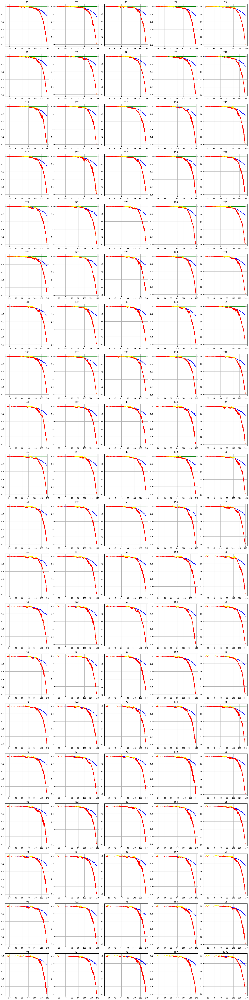

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


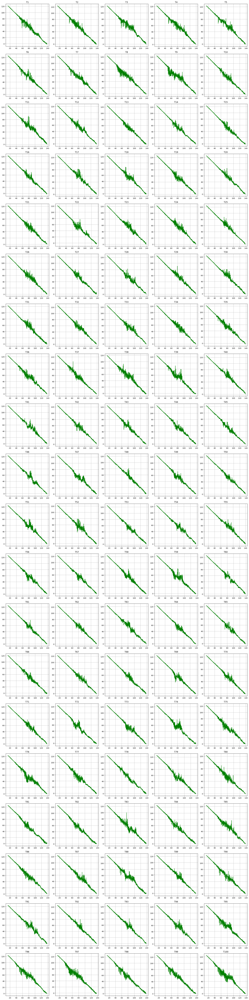

✓ Created RUL predictions subplot
Testing Client 4 - TEST Split
Total samples: 16511
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (16511, 128, 45)
  - X_time (full sequences): (16511, 128, 1)
  - X_env (full sequences): (16511, 128, 1)
  - X_time_last (last timestep for model): (16511, 1)
  - X_env_last (last timestep for model): (16511, 1)
  - y_true (last timestep RUL): (16511, 1)

Processed samples: 16511
Time range: 12.700 -> 127.700
True RUL  : min=0.000  max=115.000
Pred RUL  : min=0.273  max=110.424

Evaluation Metrics (TEST - Client 4)
  MAE:   2.3936
  RMSE:  2.8529
  sMAPE: 8.67%
  R2:    0.9920
✓ Saved: checkpoint/client_predictions/client_4_test_true_vs_pred.png
✓ Saved: checkpoint/client_predictions/client_4_test_error.png
✓ Saved: checkpoint/client_predictions/client_4_test_component_his.png
✓ Saved: checkpoint/client_predictions/client_4_test_system_hi.png
✓ Saved: checkpoin

Client 4: 100%|███████████████████████████████████████████████████| 100/100 [00:30<00:00,  3.29it/s]


✓ Completed trajectory-based testing for environment 4
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 4


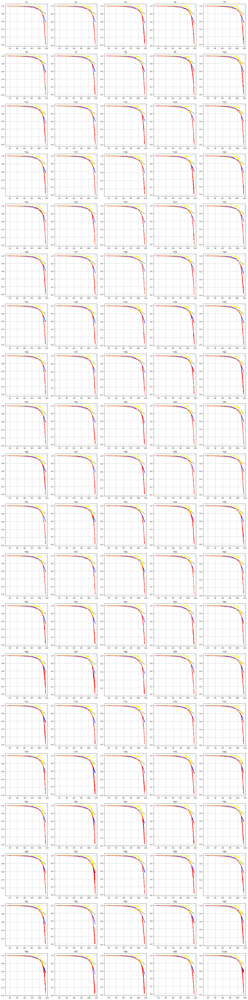

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


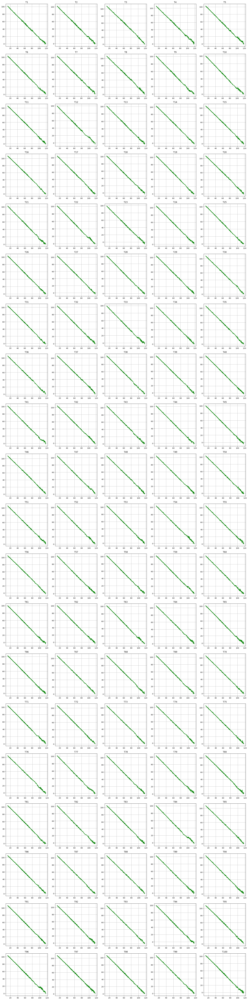

✓ Created RUL predictions subplot

Per-Client TEST Metrics
 client_id  n_samples      MAE     RMSE  sMAPE(%)       R2
         2      19276 2.418712 2.965887  8.601274 0.993626
         3      19587 2.626263 3.678679  7.887286 0.990502
         4      16511 2.393556 2.852949  8.672627 0.991972

--------------------------------------------------------------------------------
Macro Average (unweighted across clients):
  MAE=2.4795  RMSE=3.1658  sMAPE%=8.39  R2=0.9920
Micro Average (weighted by samples):
  MAE=2.4846  RMSE=3.2056  sMAPE%=8.37  R2=0.9921
--------------------------------------------------------------------------------
✓ Saved per-client TEST metrics to: checkpoint/client_predictions/test_metrics_clients_2_3_4_global_best.csv
✓ Saved detailed results to: checkpoint/client_predictions/client_global_best_2_test_results.pkl
✓ Saved detailed results to: checkpoint/client_predictions/client_global_best_3_test_results.pkl
✓ Saved detailed results to: checkpoint/client_predictions/

In [14]:

if __name__ == "__main__":

    summary = evaluate_clients_2_3_4_on_test(
        test_client_2=test_client_2,
        test_client_3=test_client_3,
        test_client_4=test_client_4,
        vaeSys_initiator=vaeSys_global_best,
        config=config,
        save_csv_path="checkpoint/client_predictions/test_metrics_clients_2_3_4_global_best.csv",
        visualize_each=True,
        save_dir="checkpoint/client_predictions/",
        # Enable trajectory-based testing
        norData=norData,
        preData=preData,
        trajectory_based_test=True,
        normalize_hi=True,
        show_redundant_shutdown=False,
        subplot_num_row=20,
        subplot_num_col=5,
    )

    # Optional: Save detailed results for each client
    import joblib
    for client_id, res in summary["detailed_results"].items():
        out_pkl = f"checkpoint/client_predictions/client_global_best_{client_id}_test_results.pkl"
        os.makedirs(os.path.dirname(out_pkl), exist_ok=True)
        joblib.dump(res, out_pkl)
        print(f"✓ Saved detailed results to: {out_pkl}")

    # Save trajectory-based results
    for client_id, traj_res in summary["trajectory_results"].items():
        out_pkl = f"checkpoint/client_predictions/client_global_best_{client_id}_trajectory_results.pkl"
        os.makedirs(os.path.dirname(out_pkl), exist_ok=True)
        joblib.dump(traj_res, out_pkl)
        print(f"✓ Saved trajectory-based results to: {out_pkl}")


#3 During your deployment, Simulate the fedrated learning by Low rank based model collaborative update mechanism

If you see "step xx." That means you need to deploy somthing.


In this part, I defined LoRA model and trained it.

For frozen contributors, aggregate their weights and then hang them on the lora layer, and only train the lora layer to ensure that the aggregated model has better performance


This part implements federated LoRA for a subclassed Keras SystemModel in a Keras-3-safe way by attaching LoRA parameters externally (no add_weight after build) and patching Dense.call to add the low-rank update while freezing base weights. Base model weights for several “variant k” checkpoints are mirrored from disk into a temporary directory and loaded strictly through the SystemModel’s existing loading pipeline. Training follows a two-stage strategy: a quick baseline across all variants (few rounds, tiny local steps) to pick the best variant by weighted global validation MSE, then full federated training only on that winner with early stopping. Federated learning runs across clients env-2/3/4 using FedAvg; FedProx (μ>0) and server-side momentum (β) are optional and on by default, while local optimization uses Adam on LoRA variables only with weight decay and gradient clipping. Inputs are packaged as (raw, seqCycle, env) where env is shaped (B,1) to avoid broadcasting issues; labels are kept on their original scale (no z-score by default). After each improvement, the current best LoRA state is saved to .../HI_model_update/lora/variant_{k}/best_lora.npz with metadata. Finally, the code reloads the best variant, applies the saved LoRA, and runs a test-time evaluation routine that emits per-client metrics and trajectory artifacts.

Here it is your part to deploy。

### **Step 1**. When HI update trigger is detected on the cloud, strat Training with all the following foler are built on your cloud server, When FL is trigger, just use the following code in your deployment.

config_FL_Lora = FLLoraConfig()


model, lora_state = run_federated_lora(system_config=config, config_FL_Lora=config_FL_Lora)

    
Especially, seceral documents ahould be prepared in your deployment,

PROJECT_ROOT = /content/drive/MyDrive/Duc_an_XAI_edge_cooperation
The project root. It’s added to sys.path so your code can import project modules/classes (e.g., SystemModel).

**HI_UPDATE_ROOT = /.../kun/checkpoint/HI_model_update/, The source depot for candidate variants. Stage 1/2 read the variant weights (encoderWts_k.h5, decoderWts_k.h5, maskWts_k.h5, hiAndRulWts_k.h5) from subfolders here (optionally with the _HI_updates suffix).It iss also the parent folder for LoRA outputs (see LORA_SAVE_ROOT) **.

**ORIGINALS_ROOT = /.../kun/checkpoint/bestModel_5epoch/. Legacy “best model” weights location. Kept for environment parity/rollback; not directly consumed by the this FL pipeline.**

TMP_MIRROR_ROOT = /.../kun/checkpoint/_tmp_variant_mirror/
The staging/mirror area. For a chosen variant_k, the script copies the needed .h5 files from HI_UPDATE_ROOT into this folder and renames them to fixed filenames that SystemModel.load_weights() expects, e.g.:

bestModelReac[_HI_updates]/encoderWts_k.h5 → .../_tmp_variant_mirror/bestModelReac/encoderWts.h5

bestModelReac[_HI_updates]/decoderWts_k.h5 → .../_tmp_variant_mirror/bestModelReac/decoderWts.h5

bestModelReac[_HI_updates]/maskWts_k.h5 → .../_tmp_variant_mirror/bestModelReac/maskWts.h5

similar for bestModelSep and bestModelStrip

bestModelSys[_HI_updates]/hiAndRulWts_k.h5 → .../_tmp_variant_mirror/bestModelSys/hiAndRulWts.h5
The mirror subfolders are wiped and recreated each build. This keeps loading deterministic and Keras-3-safe (no mutating built layers), because the model always reads from a stable, uniform path layout.

LORA_SAVE_ROOT = os.path.join(HI_UPDATE_ROOT, "lora")
The persistent output location for LoRA results, organized per variant:

.../lora/variant_{k}/best_lora.npz (the best A/B LoRA matrices)

.../lora/variant_{k}/meta.json (training/validation metadata)
Other evaluation artifacts for that variant may also be placed here.

Quick I/O flow

Read candidate weights from HI_UPDATE_ROOT (possibly the _HI_updates sets).

Stage them into TMP_MIRROR_ROOT with fixed filenames; SystemModel loads from this mirror only.

Write best LoRA to LORA_SAVE_ROOT/variant_{k}/best_lora.npz (+ meta.json).

Note: os.makedirs(..., exist_ok=True) ensures TMP_MIRROR_ROOT and LORA_SAVE_ROOT exist; the mirror is explicitly cleared each time to avoid stale files.

In [15]:
# -*- coding: utf-8 -*-
"""
Federated LoRA on subclassed Keras SystemModel — Keras 3 safe (no add_weight after build).

What this script does (unchanged functionality, industrial refactor):
- Loads the base SystemModel strictly via a mirror pipeline (.h5/joblib on Drive)
- Attaches LoRA EXTERNALLY (no state added to built layers) and optimizes LoRA only
- Runs FedAvg across env-2/3/4 clients (optional FedProx + server momentum)
- Early stopping on global validation (weighted MSE)
- TWO-STAGE procedure:
    1) Quick baseline evaluation (NO LoRA, NO training) on all variants → select best k*
    2) Full LoRA training only on the best variant k*
- Enforces RUL non-negativity via an output clamping (ReLU) wrapper
- Adds series-system "minimum HI" bias: softmin layer override + series-min regularization
- Speed flags: XLA JIT, optional mixed precision, reduced logging
- Saves best LoRA to:
    /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/variant_{k}/best_lora.npz

Industrial changes vs. the provided draft:
- All tunables are centralized in `FLLoraConfig` (config_FL_Lora)
- A single high-level `run_federated_lora(system_config, config_FL_Lora)` orchestrates the pipeline
- The function returns:
    (best_model_with_lora_mounted, best_lora_numpy_state_dict)
  where the model is constructed for the best variant and has the best LoRA already loaded.

IMPORTANT
- The code assumes your project provides `SystemModel` and that global numpy dicts for data
  (train_client_2/3/4, val_client_2/3/4, test_client_2/3/4, norData, preData) exist,
  exactly as in your original environment. This refactor deliberately preserves data flow.
"""

import os
import re
import sys
import json
import time
import glob
import copy
import shutil
import pathlib
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import tensorflow as tf
from tensorflow.keras import backend as K

# =============================================================================
# Paths & project setup (kept as constants to preserve your environment)
# =============================================================================
PROJECT_ROOT     = pathlib.Path("/content/drive/MyDrive/Duc_an_XAI_edge_cooperation")
HI_UPDATE_ROOT   = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/"
ORIGINALS_ROOT   = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/bestModel_5epoch/"
TMP_MIRROR_ROOT  = "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/"
LORA_SAVE_ROOT   = os.path.join(HI_UPDATE_ROOT, "lora")

for p in [TMP_MIRROR_ROOT, LORA_SAVE_ROOT]:
    os.makedirs(p, exist_ok=True)

path_str = str(PROJECT_ROOT.resolve())
if path_str not in sys.path:
    sys.path.insert(0, path_str)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# You must have `SystemModel` importable from your project path inserted above.
# from your_project.models import SystemModel
# In your environment the symbol is expected to be available already.
SystemModel = globals().get("SystemModel", None)  # pragma: no cover


# =============================================================================
# Centralized configuration (config_FL_Lora)
# =============================================================================
@dataclass
class FLLoraConfig:
    """
    Container for all knobs used by the pipeline.
    Defaults match your original script exactly.
    """
    # ---------- Stage 2 training ----------
    global_rounds: int = 500
    local_epochs: int = 2
    local_steps_per_epoch: int = 3

    # ---------- Optimization ----------
    batch_size: int = 512
    lr: float = 5e-4
    weight_decay: float = 1e-4
    patience: int = 10
    min_delta: float = 0.0

    # ---------- LoRA ----------
    lora_r: int = 32
    lora_alpha: float = 64.0
    lora_dropout: float = 0.15
    lora_target_regex: str = r".*"  # match all Dense layers

    # ---------- Federated ----------
    use_fedprox: bool = True
    fedprox_mu: float = 1e-3
    use_server_momentum: bool = True
    server_momentum_beta: float = 0.9
    server_step: float = 1.0

    # ---------- Pre/Post / Label ----------
    use_label_zscore: bool = False  # kept for parity; labels not scaled in this script

    # ---------- Speed / Logs ----------
    use_xla_jit: bool = True
    use_mixed_precision: bool = False
    verbose_local: bool = False
    log_every_n_steps: int = 50
    warmup_after_patch: bool = False

    # ---------- RUL non-negativity ----------
    enforce_rul_nonneg: bool = True

    # ---------- Series-system min HI ----------
    use_softmin_bias: bool = True
    softmin_temp: float = 1.0
    series_min_reg_weight: float = 0.01  # loss weight

    # ---------- Variants source ----------
    use_hi_updates: bool = True  # pick files from *_HI_updates

    # ---------- Softmin attach targets (HI selection/mask) ----------
    softmin_target_regex: str = r".*Selection.*|.*Mask.*"


# =============================================================================
# XLA / mixed precision (applied inside the runner to keep globals clean)
# =============================================================================
def _configure_runtime(cfg: FLLoraConfig):
    if cfg.use_xla_jit:
        tf.config.optimizer.set_jit(True)
        print("[XLA] JIT compilation enabled.")
    if cfg.use_mixed_precision:
        from tensorflow.keras import mixed_precision
        policy = mixed_precision.Policy('mixed_float16')
        mixed_precision.set_global_policy(policy)
        print("[Mixed Precision] Enabled with policy:", policy.name)


# =============================================================================
# Mirror helpers
# =============================================================================
def _comp_dir(root: str, sub: str, use_hi: bool) -> str:
    return os.path.join(root, f"{sub}{'_HI_updates' if use_hi else ''}")

def _ensure_empty_dir(path: str):
    if os.path.isdir(path):
        shutil.rmtree(path)
    os.makedirs(path, exist_ok=True)

def _copy_variant(src_dir: str, dst_dir: str, mapping_with_suffix: dict, idx: int):
    os.makedirs(dst_dir, exist_ok=True)
    for expected_name, base_stem in mapping_with_suffix.items():
        src = os.path.join(src_dir, f"{base_stem}_{idx}.h5")
        dst = os.path.join(dst_dir, f"{expected_name}.h5")
        if not os.path.isfile(src):
            raise FileNotFoundError(f"Variant file not found: {src}")
        shutil.copy2(src, dst)

def mirror_and_build_system_model(
    variant_idx: int,
    use_hi_updates: bool,
    system_config: dict
) -> tf.keras.Model:
    """
    Build and load your SystemModel strictly via the mirrored directory pipeline.
    """
    if SystemModel is None:
        raise RuntimeError("SystemModel not found. Ensure your project is on sys.path and imported.")

    K.clear_session()

    # Sources
    SRC_REAC_DIR  = _comp_dir(HI_UPDATE_ROOT, "bestModelReac",  use_hi_updates)
    SRC_SEP_DIR   = _comp_dir(HI_UPDATE_ROOT, "bestModelSep",   use_hi_updates)
    SRC_STRIP_DIR = _comp_dir(HI_UPDATE_ROOT, "bestModelStrip", use_hi_updates)
    SRC_SYS_DIR   = _comp_dir(HI_UPDATE_ROOT, "bestModelSys",   use_hi_updates)

    # Mirror
    DST_REAC_DIR  = os.path.join(TMP_MIRROR_ROOT, "bestModelReac")
    DST_SEP_DIR   = os.path.join(TMP_MIRROR_ROOT, "bestModelSep")
    DST_STRIP_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelStrip")
    DST_SYS_DIR   = os.path.join(TMP_MIRROR_ROOT, "bestModelSys")

    _ensure_empty_dir(DST_REAC_DIR)
    _ensure_empty_dir(DST_SEP_DIR)
    _ensure_empty_dir(DST_STRIP_DIR)
    _ensure_empty_dir(DST_SYS_DIR)

    COMP_MAPPING = {"encoderWts": "encoderWts", "decoderWts": "decoderWts", "maskWts": "maskWts"}
    SYS_MAPPING  = {"hiAndRulWts": "hiAndRulWts"}

    _copy_variant(SRC_REAC_DIR,  DST_REAC_DIR,  COMP_MAPPING, variant_idx)
    _copy_variant(SRC_SEP_DIR,   DST_SEP_DIR,   COMP_MAPPING, variant_idx)
    _copy_variant(SRC_STRIP_DIR, DST_STRIP_DIR, COMP_MAPPING, variant_idx)
    _copy_variant(SRC_SYS_DIR,   DST_SYS_DIR,   SYS_MAPPING,  variant_idx)

    # Minimal sanity
    required_keys = ["seqLength", "inReac"]
    missing = [k for k in required_keys if k not in system_config]
    if missing:
        raise KeyError(f"Missing required SystemModel config keys: {missing}")

    # Prepare config for SystemModel
    system_config = dict(system_config)  # shallow copy
    system_config["component"] = "Sys"
    system_config.setdefault("hiSelectionDim", 120)
    component_dir_root = TMP_MIRROR_ROOT

    # Instantiate
    vaeSys_contributor = SystemModel(config=system_config, componentDir=component_dir_root)

    # Load weights from the mirror
    modelDirComp1 = os.path.join(component_dir_root, "bestModelReac")
    modelDirComp2 = os.path.join(component_dir_root, "bestModelSep")
    modelDirComp3 = os.path.join(component_dir_root, "bestModelStrip")
    modelDirSys   = os.path.join(component_dir_root, "bestModelSys")
    vaeSys_contributor.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)

    return vaeSys_contributor


# =============================================================================
# Recursive layer traversal (robust)
# =============================================================================
def iter_all_layers(root: tf.keras.Model):
    """Yield all layers recursively, descending into nested tf.keras.Model or `.model` attrs."""
    seen = set()
    def _walk(layer):
        if layer in seen:
            return
        seen.add(layer)
        yield layer
        kids = []
        if hasattr(layer, "layers"):
            kids.extend(layer.layers)
        if hasattr(layer, "model") and isinstance(layer.model, tf.keras.Model):
            kids.append(layer.model)
        for ch in kids:
            for y in _walk(ch):
                yield y
    for l in _walk(root):
        if isinstance(l, tf.keras.layers.Layer):
            yield l


# =============================================================================
# RUL non-negativity: output clamping wrapper
# =============================================================================
class RULClampLayer(tf.keras.layers.Layer):
    """Clamp RUL output to be non-negative via ReLU."""
    def call(self, inputs):
        return tf.nn.relu(inputs)

def wrap_model_with_rul_clamp(model: tf.keras.Model, cfg: FLLoraConfig) -> tf.keras.Model:
    """
    Wrap the model's output with a RUL clamping layer.
    Assumes model returns (possibly tuple/list) where the last element is RUL.
    """
    if not cfg.enforce_rul_nonneg:
        return model

    class RULClampedModel(tf.keras.Model):
        def __init__(self, base_model):
            super().__init__()
            self.base_model = base_model
            self.clamp = RULClampLayer(name="rul_clamp")
        def call(self, inputs, training=None):
            outputs = self.base_model(inputs, training=training)
            if isinstance(outputs, (list, tuple)):
                *rest, rul = outputs
                return (*rest, self.clamp(rul))
            return self.clamp(outputs)

    return RULClampedModel(model)


# =============================================================================
# Series-system minimum HI: softmin bias mechanism
# =============================================================================
def attach_softmin_bias_to_dense(layer: tf.keras.layers.Dense, temp: float):
    """
    For a Dense layer with output_dim=3, override call() to apply softmin to logits.
    This encourages the model to select the minimum HI component.
    """
    if getattr(layer, "_softmin_patched", False):
        return

    units = int(layer.kernel.shape[1])
    if units != 3:
        return  # Only apply to 3-output layers (HI selection mask)

    import types
    original_call = layer.call

    def call_with_softmin(self, inputs, training=None, **kwargs):
        logits = original_call(inputs, training=training, **kwargs)
        # softmin = softmax(-logits / T)
        softmin_weights = tf.nn.softmax(-logits / temp, axis=-1)
        return softmin_weights

    layer.call = types.MethodType(call_with_softmin, layer)
    layer._softmin_patched = True

def attach_softmin_to_model(model: tf.keras.Model, cfg: FLLoraConfig):
    """
    Attach softmin bias mechanism to target Dense layers (e.g., HI selection layers).
    """
    if not cfg.use_softmin_bias:
        return
    pat = re.compile(cfg.softmin_target_regex)
    count = 0
    for lyr in iter_all_layers(model):
        if isinstance(lyr, tf.keras.layers.Dense) and pat.match(lyr.name):
            attach_softmin_bias_to_dense(lyr, temp=cfg.softmin_temp)
            count += 1
    if count > 0:
        print(f"[Softmin] Attached to {count} Dense layer(s).")


# =============================================================================
# EXTERNAL LoRA (Keras 3 safe; no add_weight after build)
# =============================================================================
_LORA_REGISTRY: Dict[tf.keras.layers.Dense, Dict[str, tf.Variable]] = {}

def clear_lora_registry():
    _LORA_REGISTRY.clear()

def attach_lora_to_dense_layer_external(
    layer: tf.keras.layers.Dense, r: int, alpha: float, dropout: float
):
    """
    Create external tf.Variable A/B (not tracked by the layer), override call() to use them.
    Base layer is frozen; only LoRA variables are trained.
    """
    if getattr(layer, "_lora_patched", False):
        return
    if not hasattr(layer, "kernel") or layer.kernel is None:
        raise RuntimeError(f"Dense '{layer.name}' is not built; cannot attach LoRA.")

    in_dim  = int(layer.kernel.shape[0])
    units   = int(layer.kernel.shape[1])
    use_bias = getattr(layer, "use_bias", True)
    act_fn   = layer.activation
    scale    = float(alpha) / float(r) if r > 0 else 0.0
    drop     = tf.keras.layers.Dropout(dropout) if (dropout and dropout > 0) else None

    lora_A = tf.Variable(
        initial_value=tf.keras.initializers.HeNormal()(shape=(in_dim, r), dtype=layer.kernel.dtype),
        trainable=True, dtype=layer.kernel.dtype, name=f"{layer.name}_lora_A")
    lora_B = tf.Variable(
        initial_value=tf.zeros((r, units), dtype=layer.kernel.dtype),
        trainable=True, dtype=layer.kernel.dtype, name=f"{layer.name}_lora_B")

    _LORA_REGISTRY[layer] = {"A": lora_A, "B": lora_B,
                             "scale": tf.constant(scale, dtype=layer.kernel.dtype),
                             "drop": drop, "act": act_fn}

    # Freeze base weights
    layer.trainable = False

    import types
    def call_with_external_lora(self, inputs, training=None, **kwargs):
        x = inputs
        y = tf.linalg.matmul(x, self.kernel)
        if use_bias and getattr(self, "bias", None) is not None:
            y = y + self.bias
        pack = _LORA_REGISTRY[self]
        if r > 0 and float(pack["scale"].numpy()) != 0.0:
            x_in = pack["drop"](x, training=training) if pack["drop"] is not None else x
            lo = tf.linalg.matmul(x_in, pack["A"])
            lo = tf.linalg.matmul(lo, pack["B"])
            y = y + pack["scale"] * lo
        if pack["act"] is not None:
            y = pack["act"](y)
        return y

    layer.call = types.MethodType(call_with_external_lora, layer)
    layer._lora_patched = True

def attach_lora_to_model_external(model: tf.keras.Model, cfg: FLLoraConfig):
    clear_lora_registry()
    pat = re.compile(cfg.lora_target_regex)
    count = 0
    for lyr in iter_all_layers(model):
        if isinstance(lyr, tf.keras.layers.Dense) and pat.match(lyr.name):
            attach_lora_to_dense_layer_external(lyr, r=cfg.lora_r, alpha=cfg.lora_alpha, dropout=cfg.lora_dropout)
            count += 1
    print(f"[LoRA] Attached (external) to {count} Dense layer(s).")

def get_lora_variables_external(model: tf.keras.Model) -> Dict[str, tf.Variable]:
    out = {}
    for lyr, pack in _LORA_REGISTRY.items():
        out[f"{lyr.name}/lora_A"] = pack["A"]
        out[f"{lyr.name}/lora_B"] = pack["B"]
    return out

def lora_state_numpy_external(model: tf.keras.Model) -> Dict[str, np.ndarray]:
    return {k: v.numpy() for k, v in get_lora_variables_external(model).items()}

def load_lora_state_from_numpy_external(model: tf.keras.Model, state: Dict[str, np.ndarray]):
    name2var = get_lora_variables_external(model)
    for k, arr in state.items():
        if k in name2var:
            name2var[k].assign(arr)


# =============================================================================
# Data pipeline (expects your globals: train_client_2/3/4 etc.)
# =============================================================================
def _np_to_tf(x: np.ndarray) -> tf.Tensor:
    return tf.convert_to_tensor(x, dtype=tf.float32)

def _pack_inputs_for_systemmodel(x_all: tf.Tensor, env_id: int) -> Tuple[tf.Tensor, tf.Tensor, tf.Tensor]:
    """Pack inputs as (rawData, seqCycle, env) to match SystemModel."""
    batch = tf.shape(x_all)[0]
    seqCycle = tf.zeros((batch, 1), dtype=tf.float32)
    env = tf.fill([batch, 1], tf.cast(env_id, tf.int32))
    return x_all, seqCycle, env

def make_tf_dataset(client_split: Dict[str, List[np.ndarray]],
                    batch_size: int, shuffle: bool, env_id: int) -> tf.data.Dataset:
    X_all, _, _ = client_split["X"]
    y = client_split["y"].astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((_np_to_tf(X_all), _np_to_tf(y)))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(10000, X_all.shape[0]), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size, drop_remainder=False).prefetch(tf.data.AUTOTUNE)

    def _map(x_all, y_true):
        inputs = _pack_inputs_for_systemmodel(x_all, env_id=env_id)
        return inputs, y_true

    return ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)

def build_all_client_datasets(batch_size: int):
    g = globals()
    def bundle(eid):
        return {"train": g[f"train_client_{eid}"],
                "val":   g[f"val_client_{eid}"],
                "test":  g[f"test_client_{eid}"]}
    c2, c3, c4 = bundle(2), bundle(3), bundle(4)
    def make_all(c, env_id):
        tr = make_tf_dataset(c["train"], batch_size, True,  env_id)
        va = make_tf_dataset(c["val"],   batch_size, False, env_id)
        te = make_tf_dataset(c["test"],  batch_size, False, env_id)
        n  = c["train"]["y"].shape[0]
        return tr, va, te, n
    return make_all(c2, 2), make_all(c3, 3), make_all(c4, 4)


# =============================================================================
# Loss, metrics, label scaler (kept for parity)
# =============================================================================
def mse_loss(y_pred, y_true):
    return tf.reduce_mean(tf.square(y_pred - y_true))

def series_min_regularization(hi_reac, hi_sep, hi_strip):
    """
    Regularization encouraging series-system minimum HI behavior.
    Penalizes deviation from min(HI_reac, HI_sep, HI_strip).
    """
    hi_stack = tf.stack([hi_reac, hi_sep, hi_strip], axis=-1)  # (B, 3)
    hi_min = tf.reduce_min(hi_stack, axis=-1, keepdims=True)   # (B, 1)
    reg = tf.reduce_mean(tf.square(hi_stack - hi_min))
    return reg

class LabelScaler:
    def __init__(self):
        self.mean = None
        self.std  = None
    def fit(self, y_list: List[np.ndarray]):
        y = np.concatenate(y_list, axis=0).astype(np.float32)
        self.mean = float(np.mean(y))
        self.std  = float(np.std(y) + 1e-8)
    def transform(self, y):
        return (y - self.mean) / self.std
    def inverse(self, y):
        return y * self.std + self.mean

def _extract_rul_from_model_output(outs):
    """SystemModel.call returns many things; RUL is the last."""
    return outs[-1] if isinstance(outs, (list, tuple)) else outs

def _extract_hi_components_from_model_output(outs):
    """
    Attempt to extract HI_reac, HI_sep, HI_strip from model output.
    Expected structure (may vary in your project):
    [recon_reac, recon_sep, recon_strip, HI_reac, HI_sep, HI_strip, ..., RUL]
    """
    if not isinstance(outs, (list, tuple)):
        return None, None, None
    try:
        if len(outs) >= 7:
            hi_reac = outs[3]
            hi_sep  = outs[4]
            hi_strip= outs[5]
            return hi_reac, hi_sep, hi_strip
    except Exception:
        pass
    return None, None, None


# =============================================================================
# Warm-up on a real mini-batch
# =============================================================================
def warmup_with_real_batch(model: tf.keras.Model, ds: tf.data.Dataset, cfg: FLLoraConfig):
    if not cfg.warmup_after_patch:
        return
    print("[WARMUP] Running a small forward pass...")
    t0 = time.time()
    for (inputs, _) in ds.take(1):
        _ = model(inputs, training=False)
        _ = model(inputs, training=True)
    print(f"[WARMUP] Done in {time.time() - t0:.2f}s.")


# =============================================================================
# FedOps
# =============================================================================
def evaluate_global(model: tf.keras.Model, val_datasets: List[tf.data.Dataset],
                    scaler: Optional[LabelScaler]) -> Tuple[float, float, List[float]]:
    total_loss = 0.0
    total_n = 0
    per_client = []
    for ds in val_datasets:
        c_loss = 0.0
        c_n = 0
        for (inputs, y) in ds:
            outs = model(inputs, training=False)
            y_pred = _extract_rul_from_model_output(outs)
            loss = mse_loss(y_pred, y).numpy()
            bs = int(y.shape[0])
            c_loss += loss * bs
            c_n    += bs
        per_client.append(c_loss / max(1, c_n))
        total_loss += c_loss
        total_n    += c_n
    weighted = total_loss / max(1, total_n) if total_n > 0 else float("inf")
    mean_mse = float(np.mean(per_client)) if per_client else float("inf")
    return weighted, mean_mse, per_client

def local_train_one_client(
    model: tf.keras.Model,
    train_ds: tf.data.Dataset,
    client_tag: str,
    round_idx: int,
    global_lora_numpy: Dict[str, np.ndarray],
    cfg: FLLoraConfig,
    scaler: Optional[LabelScaler]
) -> Dict[str, np.ndarray]:
    # broadcast latest global LoRA
    load_lora_state_from_numpy_external(model, global_lora_numpy)

    name2var  = get_lora_variables_external(model)
    lora_vars = list(name2var.values())
    optimizer = tf.keras.optimizers.Adam(learning_rate=cfg.lr)

    for ep in range(1, cfg.local_epochs + 1):
        step = 0

        for (inputs, y) in train_ds.take(cfg.local_steps_per_epoch):
            step += 1
            with tf.GradientTape() as tape:
                outs = model(inputs, training=True)
                y_pred = _extract_rul_from_model_output(outs)

                loss = mse_loss(y_pred, y)

                # Series-min regularization
                if cfg.series_min_reg_weight > 0:
                    hi_reac, hi_sep, hi_strip = _extract_hi_components_from_model_output(outs)
                    if hi_reac is not None and hi_sep is not None and hi_strip is not None:
                        series_reg = series_min_regularization(hi_reac, hi_sep, hi_strip)
                        loss = loss + cfg.series_min_reg_weight * series_reg

                # FedProx on LoRA vars
                if cfg.use_fedprox and cfg.fedprox_mu > 0:
                    prox_term = 0.0
                    for name, var in name2var.items():
                        g = tf.convert_to_tensor(global_lora_numpy[name])
                        prox_term += tf.reduce_sum(tf.square(var - g))
                    loss = loss + 0.5 * cfg.fedprox_mu * prox_term

                # L2 on LoRA vars
                if cfg.weight_decay and cfg.weight_decay > 0:
                    wd_term = tf.add_n([tf.reduce_sum(tf.square(v)) for v in lora_vars]) * cfg.weight_decay
                    loss = loss + wd_term

            grads = tape.gradient(loss, lora_vars)
            grads, _ = tf.clip_by_global_norm(grads, 1.0)
            optimizer.apply_gradients(zip(grads, lora_vars))

            if cfg.verbose_local and (step % cfg.log_every_n_steps == 0):
                print(f"[R{round_idx:03d}|{client_tag}|E{ep}|S{step}] loss={float(loss.numpy()):.6f}")

    return lora_state_numpy_external(model)

def fedavg_numpy(global_state: Dict[str, np.ndarray],
                 client_states: List[Tuple[Dict[str, np.ndarray], int]]) -> Dict[str, np.ndarray]:
    keys = list(global_state.keys())
    if not keys:
        return global_state
    total_n = sum(n for _, n in client_states)
    total_n = max(1, total_n)
    acc = {k: np.zeros_like(global_state[k]) for k in keys}
    for state, n in client_states:
        w = float(n) / total_n
        for k in keys:
            acc[k] += state[k] * w
    return acc

def fedavg_with_momentum(old_global: Dict[str, np.ndarray],
                         new_fedavg: Dict[str, np.ndarray],
                         mom_buf: Dict[str, np.ndarray],
                         beta: float,
                         step: float):
    keys = list(old_global.keys())
    for k in keys:
        delta = new_fedavg[k] - old_global[k]
        mom_buf[k] = beta * mom_buf[k] + (1 - beta) * delta
        old_global[k] = old_global[k] + step * mom_buf[k]
    return old_global, mom_buf


# =============================================================================
# Variant enumeration
# =============================================================================
def find_all_variant_indices(use_hi_updates: bool) -> List[int]:
    folder = _comp_dir(HI_UPDATE_ROOT, "bestModelReac", use_hi_updates)
    paths = glob.glob(os.path.join(folder, "encoderWts_*.h5"))
    idxs = []
    for p in paths:
        m = re.search(r"_(\d+)\.h5$", p)
        if m:
            idxs.append(int(m.group(1)))
    return sorted(set(idxs))


# =============================================================================
# Test evaluation utility (kept as-is; optional for your workflow)
# =============================================================================
def evaluate_variant_on_test(variant_idx: int, use_hi_updates: bool, system_config: dict, cfg: FLLoraConfig):
    """
    Independent test evaluation function, called after training is complete.
    Rebuilds the model, mounts best LoRA, and runs your project's test routine.
    """
    print(f"\n========== Test Evaluation for Variant {variant_idx} ==========")

    save_dir = os.path.join(LORA_SAVE_ROOT, f"variant_{variant_idx}")
    best_lora_path = os.path.join(save_dir, "best_lora.npz")

    if not os.path.exists(best_lora_path):
        print(f"⚠ Best LoRA not found at {best_lora_path}, skipping test evaluation")
        return

    # Rebuild model and load best LoRA
    K.clear_session()
    test_model = mirror_and_build_system_model(variant_idx, use_hi_updates, system_config)
    test_model = wrap_model_with_rul_clamp(test_model, cfg)
    attach_softmin_to_model(test_model, cfg)
    attach_lora_to_model_external(test_model, cfg)

    # Load best LoRA weights
    best_lora_loaded = dict(np.load(best_lora_path))
    load_lora_state_from_numpy_external(test_model, best_lora_loaded)
    print(f"✓ Loaded best LoRA from: {best_lora_path}")

    # Get test data splits from globals
    g = globals()
    test_client_2 = g["test_client_2"]
    test_client_3 = g["test_client_3"]
    test_client_4 = g["test_client_4"]
    norData = g["norData"]
    preData = g["preData"]

    # Your project-specific evaluation entry point (kept intact)
    try:
        summary = evaluate_clients_2_3_4_on_test(  # noqa: F821 (provided in your environment)
            test_client_2=test_client_2,
            test_client_3=test_client_3,
            test_client_4=test_client_4,
            vaeSys_initiator=test_model,
            config=system_config,
            save_csv_path=os.path.join(save_dir, f"test_metrics_variant_{variant_idx}.csv"),
            visualize_each=True,
            save_dir=save_dir,
            norData=norData,
            preData=preData,
            trajectory_based_test=True,
            normalize_hi=True,
            show_redundant_shutdown=False,
            subplot_num_row=20,
            subplot_num_col=5,
        )

        # Save detailed results
        import joblib
        for client_id, res in summary["detailed_results"].items():
            out_pkl = os.path.join(save_dir, f"client_{client_id}_test_results.pkl")
            joblib.dump(res, out_pkl)

        for client_id, traj_res in summary["trajectory_results"].items():
            out_pkl = os.path.join(save_dir, f"client_{client_id}_trajectory_results.pkl")
            joblib.dump(traj_res, out_pkl)

        print(f"✓ Test evaluation completed for variant {variant_idx}")

    except Exception as e:
        print(f"⚠ Test evaluation failed for variant {variant_idx}: {e}")
        import traceback
        traceback.print_exc()


# =============================================================================
# Stage 1: Quick baseline evaluation (NO training, NO LoRA)
# =============================================================================
def quick_baseline_evaluation(
    variant_idx: int,
    use_hi_updates: bool,
    system_config: dict,
    val_loaders: List[tf.data.Dataset],
    cfg: FLLoraConfig
) -> float:
    """
    Evaluate the original model (NO LoRA, NO training) on validation sets.
    Returns weighted validation MSE (lower is better).
    """
    print(f"[Baseline] Evaluating variant {variant_idx}...")

    # Build & load base SystemModel (no LoRA)
    base_model = mirror_and_build_system_model(variant_idx, use_hi_updates, system_config)
    base_model = wrap_model_with_rul_clamp(base_model, cfg)
    attach_softmin_to_model(base_model, cfg)

    # Evaluate on validation sets (no training)
    w_val, m_val, per_client = evaluate_global(base_model, val_loaders, scaler=None)
    print(f"[Baseline] Variant {variant_idx}: Val MSE = {w_val:.6f}")

    # Clean up
    K.clear_session()

    return w_val


# =============================================================================
# Stage 2: Full training on selected best variant
# =============================================================================
def full_train_best_variant(
    variant_idx: int,
    use_hi_updates: bool,
    system_config: dict,
    train_loaders: List[tf.data.Dataset],
    val_loaders: List[tf.data.Dataset],
    train_sizes: List[int],
    client_tags: List[str],
    cfg: FLLoraConfig
) -> Tuple[tf.keras.Model, Dict[str, np.ndarray], float]:
    """
    Full training on the selected best variant with early stopping.
    Returns:
      - model: the base SystemModel with LoRA attached
      - best_lora: numpy dict of the best LoRA state
      - best_val: best weighted validation MSE achieved
    """
    print(f"\n========== Full Training: Variant {variant_idx} ==========")

    # Build & load base SystemModel
    base_model = mirror_and_build_system_model(variant_idx, use_hi_updates, system_config)
    base_model = wrap_model_with_rul_clamp(base_model, cfg)
    attach_softmin_to_model(base_model, cfg)

    # Attach LoRA externally
    attach_lora_to_model_external(base_model, cfg)

    # Optional warm-up
    warmup_with_real_batch(base_model, train_loaders[0], cfg)

    # Label scaler (disabled)
    scaler = None

    # Initialize global LoRA
    global_lora = lora_state_numpy_external(base_model)
    best_lora   = copy.deepcopy(global_lora)
    best_val    = float("inf")
    rounds_no_improve = 0

    server_m = None
    if cfg.use_server_momentum:
        server_m = {k: np.zeros_like(v) for k, v in global_lora.items()}

    save_dir = os.path.join(LORA_SAVE_ROOT, f"variant_{variant_idx}")
    os.makedirs(save_dir, exist_ok=True)

    # Full training rounds
    for rnd in range(1, cfg.global_rounds + 1):
        print(f"\n[Round {rnd:03d}] Local training...")
        client_updates: List[Tuple[Dict[str, np.ndarray], int]] = []

        for ci, train_ds in enumerate(train_loaders):
            lora_after = local_train_one_client(
                base_model, train_ds,
                client_tag=client_tags[ci],
                round_idx=rnd,
                global_lora_numpy=global_lora,
                cfg=cfg,
                scaler=scaler
            )
            client_updates.append((lora_after, train_sizes[ci]))

        # Server aggregation
        fedavg_lora = fedavg_numpy(global_lora, client_states=client_updates)
        if cfg.use_server_momentum:
            global_lora, server_m = fedavg_with_momentum(
                global_lora, fedavg_lora, server_m,
                beta=cfg.server_momentum_beta, step=cfg.server_step
            )
        else:
            global_lora = fedavg_lora

        # Evaluate
        load_lora_state_from_numpy_external(base_model, global_lora)
        w_val, m_val, per_client = evaluate_global(base_model, val_loaders, scaler)
        print(f"[Round {rnd:03d}] Val MSE: {w_val:.6f} (per-client: {[f'{v:.4f}' for v in per_client]})")

        # Early stopping
        if w_val + cfg.min_delta < best_val:
            best_val = w_val
            best_lora = copy.deepcopy(global_lora)
            rounds_no_improve = 0

            # Save best LoRA
            np.savez_compressed(os.path.join(save_dir, "best_lora.npz"), **best_lora)
            meta = {
                "variant_idx": variant_idx,
                "use_hi_updates": use_hi_updates,
                "lora_config": {
                    "r": cfg.lora_r, "alpha": cfg.lora_alpha, "dropout": cfg.lora_dropout,
                    "target_regex": cfg.lora_target_regex
                },
                "train_config": {
                    "global_rounds": cfg.global_rounds, "local_epochs": cfg.local_epochs,
                    "lr": cfg.lr, "weight_decay": cfg.weight_decay,
                    "patience": cfg.patience, "min_delta": cfg.min_delta,
                    "fedprox": cfg.use_fedprox, "fedprox_mu": cfg.fedprox_mu,
                    "server_momentum": cfg.use_server_momentum, "beta": cfg.server_momentum_beta,
                    "local_steps_per_epoch": cfg.local_steps_per_epoch,
                },
                "val_loss_weighted": float(best_val),
                "timestamp": int(time.time()),
            }
            with open(os.path.join(save_dir, "meta.json"), "w") as f:
                json.dump(meta, f, indent=2)
            print(f"[Round {rnd:03d}] ✓ Saved best LoRA (val={best_val:.6f})")
        else:
            rounds_no_improve += 1
            if rounds_no_improve >= cfg.patience:
                print(f"Early stopping at round {rnd} (no improvement for {cfg.patience} rounds).")
                break

    print(f"✓ Finished training variant {variant_idx}. Best val MSE = {best_val:.6f}")

    # Ensure the returned model has the best LoRA state mounted
    load_lora_state_from_numpy_external(base_model, best_lora)
    return base_model, best_lora, best_val


# =============================================================================
# Orchestrator: run the full two-stage pipeline and return the best model + weights
# =============================================================================
def run_federated_lora(system_config: dict, config_FL_Lora: FLLoraConfig) -> Tuple[tf.keras.Model, Dict[str, np.ndarray]]:
    """
    High-level entry point.

    Args
    ----
    system_config : dict
        Configuration for your SystemModel constructor (as used in your project).
        Must include required keys like "seqLength" and "inReac".
    config_FL_Lora : FLLoraConfig
        Centralized hyperparameters & flags.

    Returns
    -------
    best_model : tf.keras.Model
        The SystemModel for the best variant, wrapped (RUL clamp) + softmin bias attached,
        with LoRA externally attached and the best LoRA weights already loaded.
    best_lora_state : Dict[str, np.ndarray]
        Numpy dict of the trained LoRA variables (keys like "<dense_name>/lora_A", ".../lora_B").
    """
    cfg = config_FL_Lora
    _configure_runtime(cfg)

    # Build datasets once from globals
    (c2_train, c2_val, c2_test, n2), (c3_train, c3_val, c3_test, n3), (c4_train, c4_val, c4_test, n4) = \
        build_all_client_datasets(cfg.batch_size)
    train_loaders = [c2_train, c3_train, c4_train]
    val_loaders   = [c2_val,   c3_val,   c4_val]
    train_sizes   = [n2, n3, n4]
    client_tags   = ["env2", "env3", "env4"]

    # Stage 1: Quick baseline evaluation (NO training, NO LoRA)
    print("\n" + "="*80)
    print("STAGE 1: Quick baseline evaluation (NO training, NO LoRA)")
    print("="*80)

    idxs = find_all_variant_indices(use_hi_updates=cfg.use_hi_updates)
    if not idxs:
        raise RuntimeError("No perturbed variants found.")
    print("Found perturbed variant indices:", idxs)

    variant_scores: Dict[int, float] = {}
    for k in idxs:
        val_mse = quick_baseline_evaluation(k, cfg.use_hi_updates, system_config, val_loaders, cfg)
        variant_scores[k] = val_mse

    # Select best variant
    best_variant = min(variant_scores, key=variant_scores.get)
    best_score = variant_scores[best_variant]

    print("\n" + "="*80)
    print("BASELINE EVALUATION RESULTS:")
    for k in sorted(variant_scores.keys()):
        marker = " ← BEST" if k == best_variant else ""
        print(f"  Variant {k}: Val MSE = {variant_scores[k]:.6f}{marker}")
    print("="*80)
    print(f"\n✓ Selected best variant: {best_variant} (Val MSE = {best_score:.6f})")

    # Stage 2: Full LoRA training on best variant only
    print("\n" + "="*80)
    print(f"STAGE 2: Full LoRA training on best variant {best_variant}")
    print("="*80)

    best_model, best_lora_state, _ = full_train_best_variant(
        variant_idx=best_variant,
        use_hi_updates=cfg.use_hi_updates,
        system_config=system_config,
        train_loaders=train_loaders,
        val_loaders=val_loaders,
        train_sizes=train_sizes,
        client_tags=client_tags,
        cfg=cfg
    )

    # Return the best model (with LoRA mounted) and the best LoRA weights (numpy dict)
    return best_model, best_lora_state


# =============================================================================
# Example CLI usage (kept minimal)
# =============================================================================
if __name__ == "__main__":


    # Create config_FL_Lora with defaults (exactly your original hyperparameters)
    config_FL_Lora = FLLoraConfig()

    # Run the two-stage Federated LoRA pipeline
    model, lora_state = run_federated_lora(system_config=config, config_FL_Lora=config_FL_Lora)

    # Optional: persist the returned LoRA state (already saved inside training, too)
    # np.savez_compressed("/tmp/best_lora_returned.npz", **lora_state)

    # The `model` is ready to be evaluated or exported; it has the best LoRA mounted.
    print("Done. Best LoRA is mounted on the returned model.")


[XLA] JIT compilation enabled.

STAGE 1: Quick baseline evaluation (NO training, NO LoRA)
Found perturbed variant indices: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
[Baseline] Evaluating variant 1...
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:17:58,721-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Process:4034||2025-10-27 10:17:58,783-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:17:58,791-DEBUG [ipython-input-427612

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:17:58,914-INFO [ipython-input-4276122690.py:load_weights():907]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSys
Process:4034||2025-10-27 10:17:58,982-INFO [ipython-input-4276122690.py:load_weights():939]:Loaded the model at the direction:/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_co

[Softmin] Attached to 1 Dense layer(s).
[Baseline] Variant 1: Val MSE = 4169.003906
[Baseline] Evaluating variant 2...
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:18:09,638-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Process:4034||2025-10-27 10:18:09,702-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:18:09,710-DEBUG [ipython-input-427612

... (15 outputs left out)

Process:4034||2025-10-27 10:19:28,909-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Process:4034||2025-10-27 10:19:28,969-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:19:28,977-DEBUG [ipython-input-427612

[Softmin] Attached to 1 Dense layer(s).
[Baseline] Variant 10: Val MSE = 5046.307129

BASELINE EVALUATION RESULTS:
  Variant 1: Val MSE = 4169.003906
  Variant 2: Val MSE = 2727.011963 ← BEST
  Variant 3: Val MSE = 1251686.625000
  Variant 4: Val MSE = 3381.065674
  Variant 5: Val MSE = 4555.136719
  Variant 6: Val MSE = 3402.218750
  Variant 7: Val MSE = 3759.700195
  Variant 8: Val MSE = 2759.498779
  Variant 9: Val MSE = 3911.459961
  Variant 10: Val MSE = 5046.307129

✓ Selected best variant: 2 (Val MSE = 2727.011963)

STAGE 2: Full LoRA training on best variant 2

========== Full Training: Variant 2 ==========
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:19:38,809-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Process:4034||2025-10-27 10:19:38,873-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:19:38,882-DEBUG [ipython-input-427612

[Softmin] Attached to 1 Dense layer(s).
[LoRA] Attached (external) to 11 Dense layer(s).

[Round 001] Local training...
[Round 001] Val MSE: 2712.272217 (per-client: ['2068.4600', '2822.2747', '3331.0696'])
[Round 001] ✓ Saved best LoRA (val=2712.272217)

[Round 002] Local training...
[Round 002] Val MSE: 2684.275879 (per-client: ['2041.8246', '2792.3909', '3303.7317'])
[Round 002] ✓ Saved best LoRA (val=2684.275879)

[Round 003] Local training...
[Round 003] Val MSE: 2644.343750 (per-client: ['2003.9099', '2749.8428', '3264.5593'])
[Round 003] ✓ Saved best LoRA (val=2644.343750)

[Round 004] Local training...
[Round 004] Val MSE: 2593.668457 (per-client: ['1955.9047', '2695.9343', '3214.6187'])
[Round 004] ✓ Saved best LoRA (val=2593.668457)

[Round 005] Local training...
[Round 005] Val MSE: 2533.365479 (per-client: ['1898.9476', '2631.8884', '3154.8677'])
[Round 005] ✓ Saved best LoRA (val=2533.365479)

[Round 006] Local training...
[Round 006] Val MSE: 2464.385498 (per-client: ['18

### **Step 2**. Loaded the lora_model version, and distribute

In [16]:

# -*- coding: utf-8 -*-
"""
Utility: load_best_model_with_lora  (fixed + hard-min for HIsys)
- Scan lora/variant_*/meta.json to pick the best variant
- Rebuild SystemModel via mirror, load all base weights
- Attach EXTERNAL LoRA to Dense layers per meta['lora_config'] and load best_lora.npz
- (Optional) Attach softmin bias and RUL clamp to match training-time behavior
- Adds a hard-min selector for HIsys when calling `getHIandRUL`
- (Optional) Load best RUL calibration if present

Returns:
    model  : tf.keras.Model (with LoRA mounted and best LoRA weights loaded)
    info   : dict with keys {variant_idx, meta, meta_path, lora_path, calib_path, save_dir}
"""

import os
import json
import glob
from typing import Dict, Tuple, Optional, List, Any
import numpy as np
import tensorflow as tf
from tensorflow.keras import backend as K

# Reuse project constants if already defined; else fallback to defaults.
HI_UPDATE_ROOT = globals().get(
    "HI_UPDATE_ROOT",
    "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/"
)
LORA_SAVE_ROOT = globals().get("LORA_SAVE_ROOT", os.path.join(HI_UPDATE_ROOT, "lora"))

# --- Optional RUL calibration head (only if you actually use it downstream) ---
class RULCalibrationHead:
    def __init__(self, per_env: bool = False, init_a: float = 1.0, init_b: float = 0.0, init_c: float = 0.0):
        self.per_env = per_env
        if per_env:
            self.a_vars = {e: tf.Variable(init_a, tf.float32, True, name=f"rul_calib_a_env{e}") for e in [2,3,4]}
            self.b_vars = {e: tf.Variable(init_b, tf.float32, True, name=f"rul_calib_b_env{e}") for e in [2,3,4]}
            self.c_vars = {e: tf.Variable(init_c, tf.float32, True, name=f"rul_calib_c_env{e}") for e in [2,3,4]}
        else:
            self.a_var = tf.Variable(init_a, tf.float32, True, name="rul_calib_a")
            self.b_var = tf.Variable(init_b, tf.float32, True, name="rul_calib_b")
            self.c_var = tf.Variable(init_c, tf.float32, True, name="rul_calib_c")
    def load_state_dict(self, state: Dict[str, np.ndarray]):
        if self.per_env:
            for e in [2,3,4]:
                self.a_vars[e].assign(state[f"a_env{e}"])
                self.b_vars[e].assign(state[f"b_env{e}"])
                self.c_vars[e].assign(state[f"c_env{e}"])
        else:
            self.a_var.assign(state["a"]); self.b_var.assign(state["b"]); self.c_var.assign(state["c"])

def _scan_variants(lora_root: str):
    """Yield (variant_idx, meta_dict, meta_path, lora_path, calib_path_or_None)."""
    out = []
    for meta_path in glob.glob(os.path.join(lora_root, "variant_*", "meta.json")):
        vdir = os.path.dirname(meta_path)
        lora_path  = os.path.join(vdir, "best_lora.npz")
        calib_path = os.path.join(vdir, "best_rul_calib.npz")
        if not os.path.isfile(lora_path):
            continue
        with open(meta_path, "r") as f:
            meta = json.load(f)
        try:
            vidx = int(meta.get("variant_idx", os.path.basename(vdir).split("_")[-1]))
        except Exception:
            vidx = int(os.path.basename(vdir).split("_")[-1])
        out.append((vidx, meta, meta_path, lora_path, calib_path if os.path.isfile(calib_path) else None))
    if not out:
        raise RuntimeError(f"No candidate variants found under: {lora_root}")
    return out

def _choose_best(cands):
    """Lowest val_loss_weighted (fallback val_mae_weighted); tie → newer timestamp."""
    def key_fn(x):
        _, meta, _, _, _ = x
        val = float(meta.get("val_loss_weighted", meta.get("val_mae_weighted", np.inf)))
        ts  = int(meta.get("timestamp", 0))
        return (val, -ts)
    return sorted(cands, key=key_fn)[0]

# --------- Bridge wrapper so methods like getHIandRUL still work ----------
def _bridge_wrapper_methods(wrapper: tf.keras.Model, *, use_hardmin_for_hisys: bool = True, clamp_rul: bool = True):
    """
    If `wrapper` has `.base_model`, forward common methods and provide a
    bridge `getHIandRUL` that:
      - enforces HIsys = hard-min(HI_reac, HI_sep, HI_strip) when enabled
      - applies ReLU to predicted RUL when enabled
    """
    if not hasattr(wrapper, "base_model"):
        return
    base = wrapper.base_model

    # Forward a few common methods if missing on wrapper
    for name in ["predict", "save", "save_weights", "get_layer", "get_config"]:
        if hasattr(base, name) and not hasattr(wrapper, name):
            setattr(wrapper, name, getattr(base, name))

    # Clamp-aware + hard-min-aware getHIandRUL (keep tuple/list structure unchanged)
    if hasattr(base, "getHIandRUL"):
        def _getHIandRUL_bridge(*args, **kwargs):
            outs = base.getHIandRUL(*args, **kwargs)
            try:
                if isinstance(outs, (list, tuple)) and len(outs) >= 5:
                    seq = list(outs)
                    # seq indices: 0=HI_reac, 1=HI_sep, 2=HI_strip, 3=HI_sys, 4=pred_RUL, 5=hiMatrixOutput (if present)
                    if use_hardmin_for_hisys:
                        hi_reac = tf.convert_to_tensor(seq[0])
                        hi_sep  = tf.convert_to_tensor(seq[1])
                        hi_strip= tf.convert_to_tensor(seq[2])
                        # stack & reduce_min for a true hard minimum
                        hi_stack = tf.stack([hi_reac, hi_sep, hi_strip], axis=-1)  # (..., 3)
                        hi_min   = tf.reduce_min(hi_stack, axis=-1, keepdims=True)  # match column shape if inputs are column vectors
                        # reshape to original HIsys shape (robust to rank differences)
                        hi_sys_shape = tf.shape(seq[3])
                        hi_min = tf.reshape(hi_min, hi_sys_shape)
                        seq[3] = hi_min
                    if clamp_rul:
                        seq[4] = tf.nn.relu(seq[4])
                    return tuple(seq) if isinstance(outs, tuple) else seq
            except Exception:
                # if anything goes wrong, fall back to original outputs
                pass
            return outs
        setattr(wrapper, "getHIandRUL", _getHIandRUL_bridge)
        # For introspection/debug
        setattr(wrapper, "_hisys_hardmin_enabled", bool(use_hardmin_for_hisys))

def load_best_model_with_lora(
    system_config: dict,
    mount_softmin_bias: bool = True,
    mount_rul_clamp: bool = True,
    load_rul_calibration: bool = False
) -> Tuple[tf.keras.Model, Dict]:
    """
    Build SystemModel (mirror), attach LoRA, load best_lora.npz, optionally softmin/RUL clamp/calibration.
    """
    # --- Check required helpers from your refactor are available in globals ---
    required = [
        "FLLoraConfig",
        "mirror_and_build_system_model",
        "attach_lora_to_model_external",
        "load_lora_state_from_numpy_external",
    ]
    if mount_softmin_bias:
        required.append("attach_softmin_to_model")
    if mount_rul_clamp:
        required.append("wrap_model_with_rul_clamp")
    for sym in required:
        if sym not in globals():
            raise RuntimeError(f"Missing required symbol in globals: {sym}")

    # --- Pick best variant ---
    cands = _scan_variants(LORA_SAVE_ROOT)
    vidx, meta, meta_path, lora_npz, calib_npz = _choose_best(cands)
    save_dir = os.path.dirname(meta_path)
    print(f"[Loader] Best variant = {vidx} (meta: {meta_path})")

    # --- LoRA config from meta ---
    lora_cfg = meta.get("lora_config", {})
    use_hi_updates = bool(meta.get("use_hi_updates", True))
    r            = int(lora_cfg.get("r", 32))
    alpha        = float(lora_cfg.get("alpha", 64.0))
    dropout      = float(lora_cfg.get("dropout", 0.15))
    target_regex = str(lora_cfg.get("target_regex", r".*"))

    # Assemble a minimal FLLoraConfig used for attachment/wrappers
    cfg = FLLoraConfig(
        lora_r=r,
        lora_alpha=alpha,
        lora_dropout=dropout,
        lora_target_regex=target_regex,
        use_softmin_bias=bool(mount_softmin_bias),
        enforce_rul_nonneg=bool(mount_rul_clamp),
    )

    # --- Rebuild SystemModel via mirror (loads ALL base weights) ---
    K.clear_session()
    model = mirror_and_build_system_model(
        variant_idx=vidx,
        use_hi_updates=use_hi_updates,
        system_config=system_config
    )

    # --- Optional: softmin bias (matches training-time inductive bias) ---
    if mount_softmin_bias:
        attach_softmin_to_model(model, cfg)

    # --- Attach EXTERNAL LoRA (Dense-only) & load best LoRA weights ---
    attach_lora_to_model_external(model, cfg)
    lora_state = dict(np.load(lora_npz))
    load_lora_state_from_numpy_external(model, lora_state)
    print(f"[Loader] Loaded LoRA weights from: {lora_npz}")

    # --- Optional: RUL clamp wrapper (ensure non-negative RUL) ---
    if mount_rul_clamp:
        model = wrap_model_with_rul_clamp(model, cfg)
        # Bridge: expose base_model APIs + hard-min HIsys + RUL clamp in getHIandRUL
        _bridge_wrapper_methods(model, use_hardmin_for_hisys=True, clamp_rul=True)
    else:
        # 即使未包 RUL clamp，也可只做硬最小 HIsys 的桥接
        _bridge_wrapper_methods(model, use_hardmin_for_hisys=True, clamp_rul=False)

    # --- Optional: RUL calibration head (if you actually consume it) ---
    if load_rul_calibration and calib_npz and os.path.isfile(calib_npz):
        calib_state = dict(np.load(calib_npz))
        rc_cfg = meta.get("rul_calib_config", {})
        per_env = bool(rc_cfg.get("per_env", False))
        init_a  = float(rc_cfg.get("init_a", 1.0))
        init_b  = float(rc_cfg.get("init_b", 0.0))
        init_c  = float(rc_cfg.get("init_c", 0.0))
        rul_calib_head = RULCalibrationHead(per_env=per_env, init_a=init_a, init_b=init_b, init_c=init_c)
        rul_calib_head.load_state_dict(calib_state)
        globals()["rul_calib_head"] = rul_calib_head
        print(f"[Loader] Loaded RUL calibration from: {calib_npz}")
    else:
        calib_npz = None  # normalize output

    info = {
        "variant_idx": vidx,
        "meta": meta,
        "meta_path": meta_path,
        "lora_path": lora_npz,
        "calib_path": calib_npz,
        "save_dir": save_dir,
    }
    return model, info


# ----------------------------
# Example minimal usage:
# ----------------------------
if __name__ == "__main__":
    # Assumes `config` dict already defined in your session for SystemModel.
    if "config" not in globals():
        raise RuntimeError("Please provide your SystemModel `config` dict in globals before running this script.")
    best_model, load_info = load_best_model_with_lora(
        system_config=config,
        mount_softmin_bias=True,
        mount_rul_clamp=True,
        load_rul_calibration=False  # set True if you saved/need calibration
    )
    print("[Done] Best model with LoRA mounted is ready.")
    print("       Variant:", load_info["variant_idx"])
    print("       Meta   :", load_info["meta_path"])
    print("       LoRA   :", load_info["lora_path"])


[Loader] Best variant = 2 (meta: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/variant_2/meta.json)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:31:56,070-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():942]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip
Process:4034||2025-10-27 10:31:56,140-INFO [ipython-input-4276122690.py:loadWeightAndFreezePretrainedHI():981]:Loaded the model at the direction:('/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep', '/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip') and freezed it successfully!!!
Process:4034||2025-10-27 10:31:56,148-DEBUG [ipython-input-427612

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:4034||2025-10-27 10:31:56,276-INFO [ipython-input-4276122690.py:load_weights():907]:Loading the model at the direction: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSys
Process:4034||2025-10-27 10:31:56,353-INFO [ipython-input-4276122690.py:load_weights():939]:Loaded the model at the direction:/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelReac, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelSep, /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/_tmp_variant_mirror/bestModelStrip, /content/drive/MyDrive/Duc_an_XAI_edge_co

[Softmin] Attached to 1 Dense layer(s).
[LoRA] Attached (external) to 11 Dense layer(s).
[Loader] Loaded LoRA weights from: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/variant_2/best_lora.npz
[Done] Best model with LoRA mounted is ready.
       Variant: 2
       Meta   : /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/variant_2/meta.json
       LoRA   : /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/variant_2/best_lora.npz


## Testing version with my test code, directly test on different clients' data（env data） to simulte the server's behavior in making sure it is the global brest.


========== Run TEST Evaluation (using in-memory best_model) ==========

################################################################################
# Evaluating Clients 2, 3, 4 on TEST Split
# Using dict-based splits from build_env_clients_2_3_4
################################################################################
Testing Client 2 - TEST Split
Total samples: 19276
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (19276, 128, 45)
  - X_time (full sequences): (19276, 128, 1)
  - X_env (full sequences): (19276, 128, 1)
  - X_time_last (last timestep for model): (19276, 1)
  - X_env_last (last timestep for model): (19276, 1)
  - y_true (last timestep RUL): (19276, 1)

Processed samples: 19276
Time range: 12.700 -> 145.700
True RUL  : min=0.000  max=133.000
Pred RUL  : min=0.000  max=108.118

Evaluation Metrics (TEST - Client 2)
  MAE:   11.1374
  RMSE:  13.5705
  sMAPE: 47.77%
  R

Client 2: 100%|███████████████████████████████████████████████████| 100/100 [00:36<00:00,  2.73it/s]


✓ Completed trajectory-based testing for environment 2
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 2


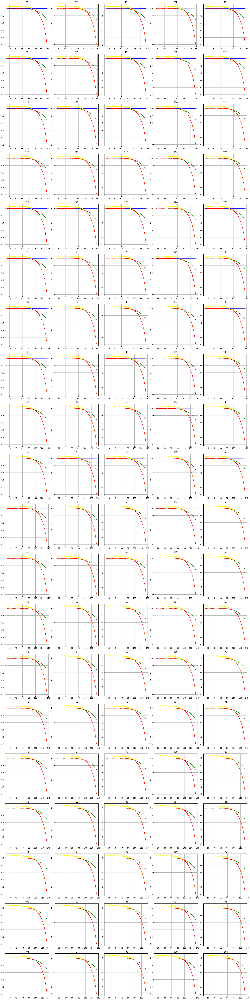

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


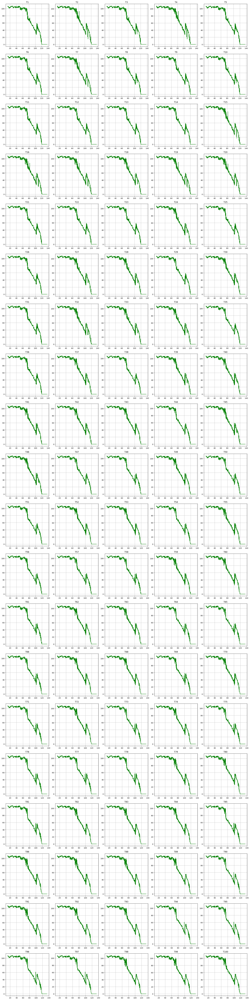

✓ Created RUL predictions subplot
Testing Client 3 - TEST Split
Total samples: 19587
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (19587, 128, 45)
  - X_time (full sequences): (19587, 128, 1)
  - X_env (full sequences): (19587, 128, 1)
  - X_time_last (last timestep for model): (19587, 1)
  - X_env_last (last timestep for model): (19587, 1)
  - y_true (last timestep RUL): (19587, 1)

Processed samples: 19587
Time range: 12.700 -> 147.900
True RUL  : min=0.000  max=135.200
Pred RUL  : min=0.000  max=115.505

Evaluation Metrics (TEST - Client 3)
  MAE:   12.9638
  RMSE:  15.4485
  sMAPE: 60.13%
  R2:    0.8325
✓ Saved: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/runtime_eval/client_3_test_true_vs_pred.png
✓ Saved: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/runtime_eval/client_3_test_error.png
✓ Saved: /con

Client 3: 100%|███████████████████████████████████████████████████| 100/100 [00:38<00:00,  2.63it/s]


✓ Completed trajectory-based testing for environment 3
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 3


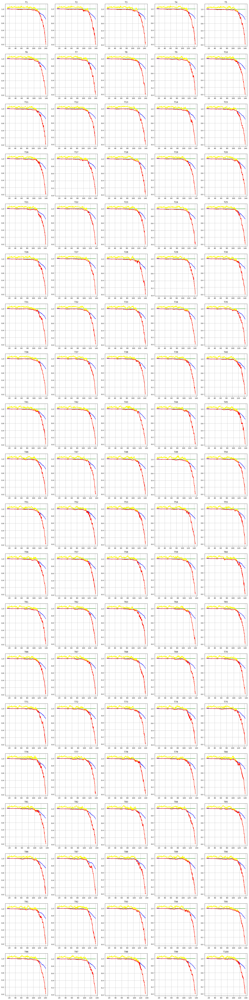

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


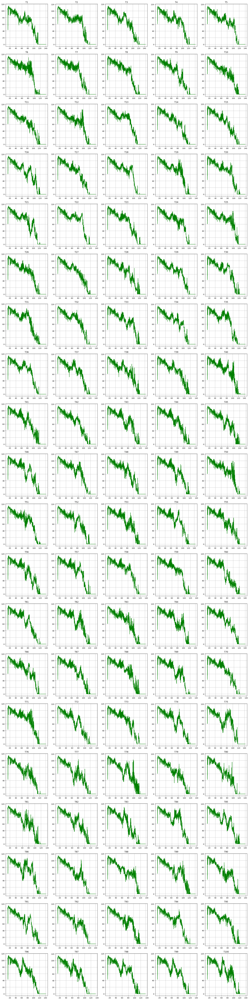

✓ Created RUL predictions subplot
Testing Client 4 - TEST Split
Total samples: 16511
Model configuration:
  - Sequence length: 128
  - Input features:  45
  - HI selection dim:120
Input shapes:
  - X_allSensor (full sequences): (16511, 128, 45)
  - X_time (full sequences): (16511, 128, 1)
  - X_env (full sequences): (16511, 128, 1)
  - X_time_last (last timestep for model): (16511, 1)
  - X_env_last (last timestep for model): (16511, 1)
  - y_true (last timestep RUL): (16511, 1)

Processed samples: 16511
Time range: 12.700 -> 127.700
True RUL  : min=0.000  max=115.000
Pred RUL  : min=0.000  max=74.945

Evaluation Metrics (TEST - Client 4)
  MAE:   13.3529
  RMSE:  16.9052
  sMAPE: 62.88%
  R2:    0.7181
✓ Saved: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/runtime_eval/client_4_test_true_vs_pred.png
✓ Saved: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/runtime_eval/client_4_test_error.png
✓ Saved: /cont

Client 4: 100%|███████████████████████████████████████████████████| 100/100 [00:32<00:00,  3.12it/s]


✓ Completed trajectory-based testing for environment 4
  Total trajectories processed: 100

Creating Subplot Visualizations for Environment 4


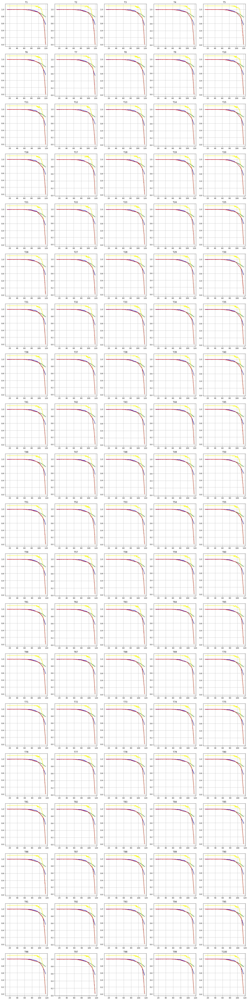

✓ Created HI components subplot (Reactor, Separator, Stripper, System)


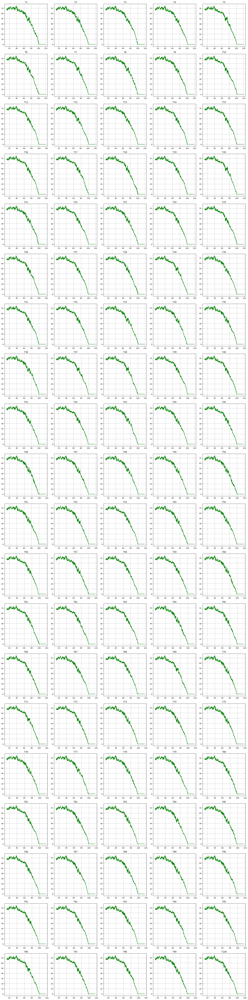

✓ Created RUL predictions subplot

Per-Client TEST Metrics
 client_id  n_samples       MAE      RMSE  sMAPE(%)       R2
         2      19276 11.137369 13.570460 47.772403 0.866560
         3      19587 12.963830 15.448507 60.129744 0.832493
         4      16511 13.352928 16.905191 62.884673 0.718133

--------------------------------------------------------------------------------
Macro Average (unweighted across clients):
  MAE=12.4847  RMSE=15.3081  sMAPE%=56.93  R2=0.8057
Micro Average (weighted by samples):
  MAE=12.4440  RMSE=15.2885  sMAPE%=56.65  R2=0.8211
--------------------------------------------------------------------------------
✓ Saved per-client TEST metrics to: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/runtime_eval/test_metrics_runtime_1761561116.csv
✓ Saved detailed results: /content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/lora/runtime_eval/client_2_test_results.pkl
✓ Saved detailed results

In [17]:
# -*- coding: utf-8 -*-
"""
Post-Training TEST runner (use in-memory `best_model` only; no fallback loading).
- Uses global `best_model` returned by your training pipeline.
- Guarantees:
    * `getHIandRUL` is available
    * HIsys = hard-min(HI_reac, HI_sep, HI_strip)
    * predicted RUL is ReLU-clamped (non-negative)
- Runs evaluate_clients_2_3_4_on_test(...) on TEST splits and saves artifacts.
"""

import os
import time
import numpy as np
import tensorflow as tf

# -----------------------------------------------------------------------------
# Paths (kept consistent with your training script)
# -----------------------------------------------------------------------------
HI_UPDATE_ROOT = globals().get(
    "HI_UPDATE_ROOT",
    "/content/drive/MyDrive/Duc_an_XAI_edge_cooperation/kun/checkpoint/HI_model_update/"
)
LORA_SAVE_ROOT = globals().get("LORA_SAVE_ROOT", os.path.join(HI_UPDATE_ROOT, "lora"))

# -----------------------------------------------------------------------------
# Bridge/patch helpers to enforce hard-min HIsys and ReLU RUL via getHIandRUL
# -----------------------------------------------------------------------------
def _bridge_wrapper_methods(wrapper: tf.keras.Model, *, use_hardmin_for_hisys: bool = True, clamp_rul: bool = True):
    """
    If `wrapper` wraps a base model (has `.base_model`), forward base methods and
    expose a getHIandRUL that applies:
      - HIsys := hard-min(HI_reac, HI_sep, HI_strip)
      - RUL   := ReLU(RUL)
    """
    if not hasattr(wrapper, "base_model"):
        return
    base = wrapper.base_model

    # Forward common methods
    for name in ["predict", "save", "save_weights", "get_layer", "get_config"]:
        if hasattr(base, name) and not hasattr(wrapper, name):
            setattr(wrapper, name, getattr(base, name))

    if hasattr(base, "getHIandRUL"):
        def _getHIandRUL_bridge(*args, **kwargs):
            outs = base.getHIandRUL(*args, **kwargs)
            try:
                if isinstance(outs, (list, tuple)) and len(outs) >= 5:
                    seq = list(outs)
                    # indices: 0=HI_reac, 1=HI_sep, 2=HI_strip, 3=HI_sys, 4=pred_RUL, (5=hiMatrixOutput, ...)
                    if use_hardmin_for_hisys:
                        hi_reac = tf.convert_to_tensor(seq[0])
                        hi_sep  = tf.convert_to_tensor(seq[1])
                        hi_strip= tf.convert_to_tensor(seq[2])
                        hi_stack= tf.stack([hi_reac, hi_sep, hi_strip], axis=-1)
                        hi_min  = tf.reduce_min(hi_stack, axis=-1, keepdims=True)
                        hi_min  = tf.reshape(hi_min, tf.shape(seq[3]))
                        seq[3]  = hi_min
                    if clamp_rul:
                        seq[4]  = tf.nn.relu(seq[4])
                    return tuple(seq) if isinstance(outs, tuple) else seq
            except Exception:
                pass
            return outs
        setattr(wrapper, "getHIandRUL", _getHIandRUL_bridge)
        setattr(wrapper, "_hisys_hardmin_enabled", bool(use_hardmin_for_hisys))

def _patch_plain_model_getHIandRUL(model: tf.keras.Model, *, use_hardmin_for_hisys: bool = True, clamp_rul: bool = True):
    """
    If `model` is not a wrapper but has `getHIandRUL`, wrap that method to enforce
    hard-min HIsys and ReLU-clamped RUL.
    """
    if not hasattr(model, "getHIandRUL"):
        raise RuntimeError("`best_model` does not expose `getHIandRUL`.")
    _orig = model.getHIandRUL

    def _patched(*args, **kwargs):
        outs = _orig(*args, **kwargs)
        try:
            if isinstance(outs, (list, tuple)) and len(outs) >= 5:
                seq = list(outs)
                if use_hardmin_for_hisys:
                    hi_reac = tf.convert_to_tensor(seq[0])
                    hi_sep  = tf.convert_to_tensor(seq[1])
                    hi_strip= tf.convert_to_tensor(seq[2])
                    hi_stack= tf.stack([hi_reac, hi_sep, hi_strip], axis=-1)
                    hi_min  = tf.reduce_min(hi_stack, axis=-1, keepdims=True)
                    hi_min  = tf.reshape(hi_min, tf.shape(seq[3]))
                    seq[3]  = hi_min
                if clamp_rul:
                    seq[4]  = tf.nn.relu(seq[4])
                return tuple(seq) if isinstance(outs, tuple) else seq
        except Exception:
            pass
        return outs

    model.getHIandRUL = _patched

# -----------------------------------------------------------------------------
# Prepare in-memory `best_model`
# -----------------------------------------------------------------------------
def prepare_best_model_for_test():
    """
    Use global `best_model` only (no fallback loader).
    Ensures getHIandRUL exists and applies hard-min for HIsys + ReLU clamp for RUL.
    """
    g = globals()
    if "best_model" not in g or not isinstance(g["best_model"], tf.keras.Model):
        raise RuntimeError("Global `best_model` is required in memory (no fallback allowed).")

    model = g["best_model"]

    # If it's a wrapper (e.g., RULClampedModel), bridge methods on the wrapper.
    if hasattr(model, "base_model"):
        _bridge_wrapper_methods(model, use_hardmin_for_hisys=True, clamp_rul=True)
        if not hasattr(model, "getHIandRUL"):
            raise RuntimeError("Wrapped `best_model` does not expose `getHIandRUL` after bridging.")
    else:
        # Plain model: patch its getHIandRUL directly.
        _patch_plain_model_getHIandRUL(model, use_hardmin_for_hisys=True, clamp_rul=True)

    return model

# -----------------------------------------------------------------------------
# TEST runner
# -----------------------------------------------------------------------------
def run_test_using_best_model(
    visualize_each: bool = True,
    trajectory_based_test: bool = True,
    normalize_hi: bool = True,
    show_redundant_shutdown: bool = False,
    subplot_num_row: int = 20,
    subplot_num_col: int = 5,
):
    """
    Run TEST evaluation using in-memory `best_model` only.
    Saves artifacts under {LORA_SAVE_ROOT}/runtime_eval/.
    """
    g = globals()
    # Required globals
    required_syms = [
        "config",
        "evaluate_clients_2_3_4_on_test",
        "test_client_2",
        "test_client_3",
        "test_client_4",
    ]
    for sym in required_syms:
        if sym not in g:
            raise RuntimeError(f"Global `{sym}` is required for test evaluation.")

    model = prepare_best_model_for_test()

    save_dir = os.path.join(LORA_SAVE_ROOT, "runtime_eval")
    os.makedirs(save_dir, exist_ok=True)
    csv_out = os.path.join(save_dir, f"test_metrics_runtime_{int(time.time())}.csv")

    # Optional resources for trajectory-based testing
    norData = g.get("norData", None)
    preData = g.get("preData", None)

    print("\n========== Run TEST Evaluation (using in-memory best_model) ==========")
    summary = g["evaluate_clients_2_3_4_on_test"](
        test_client_2=g["test_client_2"],
        test_client_3=g["test_client_3"],
        test_client_4=g["test_client_4"],
        vaeSys_initiator=model,
        config=g["config"],
        save_csv_path=csv_out,
        visualize_each=visualize_each,
        save_dir=save_dir,
        # trajectory-based options
        norData=norData,
        preData=preData,
        trajectory_based_test=trajectory_based_test and (norData is not None) and (preData is not None),
        normalize_hi=normalize_hi,
        show_redundant_shutdown=show_redundant_shutdown,
        subplot_num_row=subplot_num_row,
        subplot_num_col=subplot_num_col,
    )

    # Persist detailed outputs if provided by your evaluator
    try:
        import joblib
        for cid, res in summary.get("detailed_results", {}).items():
            out_pkl = os.path.join(save_dir, f"client_{cid}_test_results.pkl")
            joblib.dump(res, out_pkl)
            print(f"✓ Saved detailed results: {out_pkl}")
        for cid, traj_res in summary.get("trajectory_results", {}).items():
            out_pkl = os.path.join(save_dir, f"client_{cid}_trajectory_results.pkl")
            joblib.dump(traj_res, out_pkl)
            print(f"✓ Saved trajectory results: {out_pkl}")
        print("\n✓ TEST evaluation completed.")
    except Exception as e:
        print(f"[WARN] Persisting artifacts failed: {e}")

    return dict(save_dir=save_dir, summary=summary)

# -----------------------------------------------------------------------------
# CLI
# -----------------------------------------------------------------------------
if __name__ == "__main__":
    _ = run_test_using_best_model(
        visualize_each=True,
        trajectory_based_test=True,  # requires norData & preData
        normalize_hi=True,
        show_redundant_shutdown=False,
        subplot_num_row=20,
        subplot_num_col=5,
    )


## Testing version and resue your code to make sure the best model can seamlyess intergrate with your pipeline

In [18]:

environmentIdx      = 2
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime))

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,
                                                                shuffle     = False,
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = best_model.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # aiLogger.debug(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

# aiLogger.debug((timeDraw[0].shape))
if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:4034||2025-10-27 10:35:20,123-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...


Getting the HI at the idx 1


Process:4034||2025-10-27 10:35:20,490-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...


Getting the HI at the idx 2


Process:4034||2025-10-27 10:35:20,853-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...


Getting the HI at the idx 3


... (190 outputs left out)

Process:4034||2025-10-27 10:35:56,906-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...


Getting the HI at the idx 99


Process:4034||2025-10-27 10:35:57,269-INFO [preProcessingDataTEP.py:getTensorData():871]:Spliting data into sequences now ...


Getting the HI at the idx 100


In [19]:

import plotly.graph_objects as go
import os
def draw2DMultipleY(
                    xCoor       = [0,10],
                    yCoor       = [[0,10],[10,1]],
                    yLabel      = "Y Value",
                    xLabel      = "Time Unit",
                    title       = "XYAxis",
                    saveFig     = False,
                    direction   = "checkpoint/",
                    savedName   = "default",
                    useLegend   = True,
                    legend      = ["line1","line2"],
                    color       = ["blue","green"],
                    yLim       = [],):

    plt.figure()
    for idx,yValue in enumerate(yCoor):
        plt.plot(xCoor,yValue, color=color[idx])

    plt.title(title)
    # plt.xlabel(xLabel)
    # plt.ylabel(yLabel)

    if len(yLim) != 0:
        plt.ylim(yLim)
    if useLegend:
        plt.legend(legend, loc='upper left')
    plt.grid(True)
    if saveFig:

        if not os.path.exists(direction):
            os.makedirs(direction)
        plt.savefig(direction + savedName + '.png')
        plt.close()
    else:
        plt.show()


def draw2DMultipleY_plotly(
        xCoor=[0, 10],
        yCoor=[[0, 10], [10, 1]],
        yLabel="Y Value",
        xLabel="Time Unit",
        title="XYAxis",
        saveFig=False,
        direction="checkpoint/",
        savedName="default",
        useLegend=True,
        legend=["line1", "line2"],
        color=["blue", "green"],
        yLim=[]
    ):

    fig = go.Figure()

    for idx, yValue in enumerate(yCoor):
        fig.add_trace(go.Scatter(
            x=xCoor,
            y=yValue,
            mode='lines',
            name=legend[idx] if useLegend else None,
            line=dict(color=color[idx])
        ))

    # fig.update_layout(
    #     title=title,
    #     xaxis_title=xLabel,
    #     yaxis_title=yLabel,
    #     yaxis=dict(range=yLim if yLim else None),
    #     showlegend=useLegend
    # )
    fig.update_layout(
    title=title,
    xaxis_title=xLabel,
    yaxis_title=yLabel,
    yaxis=dict(range=yLim if yLim else None),
    showlegend=useLegend,
    plot_bgcolor='white',
    paper_bgcolor='white'
)


    if saveFig:
        if not os.path.exists(direction):
            os.makedirs(direction)
        fig.write_image(f"{direction}{savedName}.png")
    else:
        fig.show()


In [20]:

drawId = 2
curTimeDraw = timeDraw[drawId]
hi1Draw = hiEnv1["Reac"][drawId]
hi2Draw = hiEnv1["Sep"][drawId]
hi3Draw = hiEnv1["Strip"][drawId]
hiSysDraw = hiEnv1["Sys"][drawId]

draw2DMultipleY_plotly(xCoor = curTimeDraw, yCoor = [hi1Draw, hi2Draw, hi3Draw], title = None, xLabel = "Cycle", yLabel = "Component HIs", color = ["blue", "green", "orange"], useLegend= False, yLim = [0,1.1])


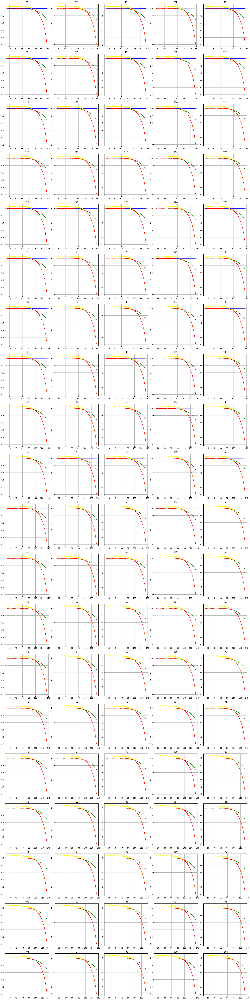

In [21]:

plot1 = MatPlot()
plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

# New Section